# 4강. 일반화: 과적합을 보고, 막고, 기록하기

**대상**: 파이썬과 1~3강 내용을 아는 입문자 · **분량**: 5부 · **환경**: Google Colab

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**예상 학습 시간**: 읽고 실습하는 데 6~8시간, 학습 대기 시간은 별도입니다. 전체 실행은 Apple GPU에서 다른 작업과 함께 돌려 약 1시간 30분에서 2시간 걸렸습니다. Colab에서는 재 보지 못했습니다. **막혔을 때**: 에러 메시지로 [PyTorch 포럼](https://discuss.pytorch.org/)을 검색하고, 함수는 [PyTorch 공식 문서](https://pytorch.org/docs/stable/index.html)에서 확인하세요.

학습 데이터에서 잘 맞는 모델을 만드는 일은 생각보다 쉽습니다. 어려운 일은 **처음 보는 데이터에서도 잘 맞게** 만드는 것입니다. 이 성질을 일반화(generalization)라고 부릅니다. 이번 강의는 일반화가 무너지는 모습을 먼저 눈으로 보고, 그것을 막는 도구를 하나씩 실험으로 확인합니다.

이 강을 마치면 다음을 할 수 있습니다.

- 학습 곡선을 보고 과적합과 과소적합을 구분한다.
- torchvision과 Albumentations로 증강을 구성하고, 데이터에 맞는 증강을 고른다. AutoAugment와 TTA도 쓸 수 있다.
- BatchNorm과 Dropout의 동작을 학습 모드와 평가 모드로 나누어 설명한다.
- L1, L2, Elastic Net의 차이를 설명하고, Early stopping을 구현한다.
- gradient 소실과 폭발을 측정하고, clipping으로 다룬다.
- 배깅, 보팅, 부스팅, 스태킹을 구분하고 신경망 앙상블을 만든다.
- 실험을 TensorBoard와 wandb에 기록한다.

| 부 | 주제 | 필수 | 선택 |
|---|---|---|---|
| 1부 | 과적합과 데이터 증강 | 과적합 관찰, 증강의 효과, `transforms.v2` | Albumentations, 속도 비교 |
| 2부 | 증강 고르기 | 좋은 증강의 조건, MNIST 실험, 지금의 기본 조합(TrivialAugment, MixUp, CutMix) | AutoAugment, TTA |
| 3부 | BatchNorm과 Dropout | BatchNorm, Dropout, CIFAR-10 비교 실험 | covariate shift, whitening의 수식 |
| 4부 | 규제와 Early stopping, gradient | L1, L2, AdamW, Early stopping, gradient 소실, clipping | Elastic Net, scikit-learn 실습, MTL |
| 5부 | 앙상블과 실험 기록 | 배깅, 보팅, 부스팅, 시드 앙상블, TensorBoard | 스태킹, 사전학습 모델 합치기, wandb |

> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 학습이 빨라집니다. 전체 실행에는 GPU로도 한 시간 넘게 걸릴 수 있습니다. 오래 걸리는 실험의 학습 횟수는 첫 코드 셀의 상수(`OVERFIT_EPOCHS` 등)로 모아 두었으니 시간이 부족하면 줄여서 돌리세요. 선택 절은 설명을 건너뛰어도 되지만 뒤에서 쓰는 변수가 있으니 **코드 셀은 실행하세요.** `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.
>
> 저장된 출력은 한 번 실행한 결과입니다. 난수와 장비가 다르면 숫자가 조금 달라질 수 있습니다.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리 (ttach는 Colab에 없고, 나머지는 있으면 그대로 넘어갑니다)
%pip install -q albumentations ttach tensorboard wandb scikit-learn pandas

import os
import random
import shutil
import time
import warnings
from collections.abc import Callable, Iterable
from pathlib import Path

# Albumentations가 import할 때마다 새 버전을 인터넷에서 확인하지 않게 합니다
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.models as models
import ttach as tta
from albumentations.pytorch import ToTensorV2
from PIL import Image
from sklearn.base import BaseEstimator
from sklearn.calibration import CalibratedClassifierCV
from sklearn.datasets import fetch_california_housing, load_digits, load_iris
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from torch.utils.data import DataLoader, Subset, random_split
from torch.utils.data.sampler import SubsetRandomSampler
from torch.utils.tensorboard import SummaryWriter
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from torchvision import datasets
from torchvision.transforms import v2
import wandb

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ Albumentations:", A.__version__, "/ device:", device)

# Colab(리눅스)에서는 일꾼 프로세스 2개가 빠릅니다. Mac과 Windows는 노트북에서 일꾼을 띄우는 방식이 달라 0으로 둡니다
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

# 이미지를 0~1 실수 텐서로 바꾸는 표준 단계입니다. 1.5에서 설명합니다
to_tensor = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

plt.rcParams["figure.dpi"] = 72  # 저장되는 노트북 크기를 줄이기 위해 해상도를 낮춥니다

# 학습 횟수를 한곳에 모았습니다. 시간이 부족하면 여기만 줄이세요
OVERFIT_EPOCHS = 30   # 1, 3부 CIFAR-10 과적합 실험
MNIST_EPOCHS = 10     # 2부 MNIST 증강 실험과 3부 BatchNorm 실험
LENET_EPOCHS = 150    # 3부 작은 CNN의 Dropout 비교
ENSEMBLE_EPOCHS = 5   # 5부 사전학습 모델 앙상블
WANDB_EPOCHS = 30     # 5부 wandb 실습


class Transforms:
    """
    Albumentations 변환을 torchvision 데이터셋에 꽂을 수 있게 감쌉니다.

    Albumentations는 image=image 형태로 호출해야 하는데 torchvision 데이터셋은 transform(img)로
    호출하므로, 이 클래스가 중간에서 맞춰 줍니다. 1.6과 2.2에서 씁니다.
    """

    def __init__(self, transforms: A.Compose):
        self.transforms = transforms

    def __call__(self, img: Image.Image) -> torch.Tensor:
        # 여기서 ["image"]를 꺼내면 학습 코드를 torchvision 쪽과 똑같이 쓸 수 있습니다
        return self.transforms(image=np.array(img))["image"]


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다. 1강에서 만든 함수입니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / Albumentations: 2.0.8 / device: mps


---
# 1부. 과적합을 보고, 데이터 증강으로 줄이기

## 1.1 과적합과 과소적합

**오버피팅(overfitting, 과적합)**: 학습 데이터(Training Set)에 대해 과하게 학습된 상황입니다. 그래서 학습 데이터 밖의 데이터에서는 모델이 잘 동작하지 못합니다. 학습 데이터가 부족하거나, 데이터의 특성에 비해 모델이 너무 복잡할 때 생깁니다. Training Set의 loss는 계속 떨어지는데 Test Set의 loss는 감소하다가 다시 증가하는 모습이 전형적인 신호입니다.

**언더피팅(underfitting, 과소적합)**: 이미 가진 Training Set조차 학습하지 못한 상태입니다. 오버피팅과 반대되는 상태입니다. 학습 반복 횟수가 너무 적거나, 데이터의 특성에 비해 모델이 너무 간단할 때 생깁니다.

데이터가 너무 적어도 비슷한 증상이 나타날 수 있습니다. 다만 데이터가 적을 때의 대표 증상은 오버피팅이고(적은 점은 외우기 쉽습니다), 언더피팅의 주된 원인은 모델과 학습 부족입니다. 둘을 가르는 기준은 데이터 양보다 **학습 오차**입니다. 학습 오차부터 크면 언더피팅, 학습 오차는 작은데 테스트 오차만 크면 오버피팅입니다.

아래 코드는 사인 곡선에서 뽑은 점 15개에 다항식을 맞춥니다. 차수가 모델의 복잡도입니다. 곡선 맞추기와 학습 곡선, 복잡도와 오차의 관계를 직접 그려 봅니다. 참고 그림: [언더피팅과 오버피팅 1](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbeQHe2%2FbtslA7YD0FV%2FAIkkuPA0OacDkwphCAuq11%2Fimg.png) · [언더피팅과 오버피팅 2](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FF6VDF%2FbtslB0ETueD%2FkrQCDcOlF5ZN4iHyPhkvok%2Fimg.png) · [학습 곡선](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fos0E5%2FbtqEmoQh8Z6%2FtU2unf6BnFNmwb4Yxssoik%2Fimg.png) · [복잡도와 오차](https://ko.d2l.ai/_images/capacity_vs_error.svg)

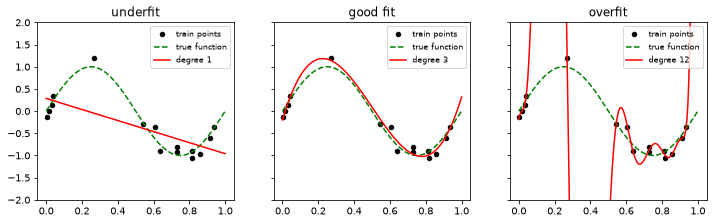

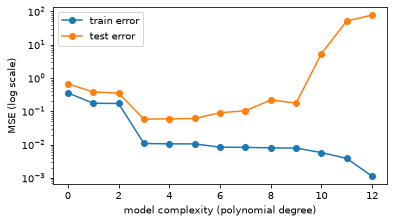

테스트 오차가 가장 작은 차수: 3


In [2]:
def make_poly_data(n: int, noise: float = 0.2, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """사인 곡선 위의 점에 잡음을 더해 만듭니다."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 1, n))
    return x, np.sin(2 * np.pi * x) + rng.normal(0, noise, n)


x_poly, y_poly = make_poly_data(15)
x_poly_test, y_poly_test = make_poly_data(200, seed=1)
x_grid = np.linspace(0, 1, 200)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, degree, name in zip(axes, [1, 3, 12], ["underfit", "good fit", "overfit"]):
    coef = np.polyfit(x_poly, y_poly, degree)
    ax.scatter(x_poly, y_poly, color="black", s=20, label="train points")
    ax.plot(x_grid, np.sin(2 * np.pi * x_grid), "g--", label="true function")
    ax.plot(x_grid, np.polyval(coef, x_grid), "r", label=f"degree {degree}")
    ax.set_ylim(-2, 2)
    ax.set_title(name)
    ax.legend(fontsize=8)
plt.show()

# 차수를 올리면서 학습 오차와 테스트 오차를 잽니다
degrees = list(range(0, 13))
train_errors, test_errors = [], []
for degree in degrees:
    coef = np.polyfit(x_poly, y_poly, degree)
    train_errors.append(np.mean((np.polyval(coef, x_poly) - y_poly) ** 2))
    test_errors.append(np.mean((np.polyval(coef, x_poly_test) - y_poly_test) ** 2))

plt.figure(figsize=(6, 3.2))
plt.semilogy(degrees, train_errors, "o-", label="train error")
plt.semilogy(degrees, test_errors, "o-", label="test error")
plt.xlabel("model complexity (polynomial degree)")
plt.ylabel("MSE (log scale)")
plt.legend()
plt.show()
print("테스트 오차가 가장 작은 차수:", degrees[int(np.argmin(test_errors))])

학습 오차는 차수가 오를수록 계속 줄어듭니다. 테스트 오차는 줄다가 어느 지점부터 다시 커집니다. **학습 오차만 보면 가장 복잡한 모델이 항상 이깁니다.** 그래서 학습에 쓰지 않은 데이터로 평가해야 합니다.

## 1.2 신경망에서 과적합 재현하기

이 현상을 신경망에서 보겠습니다. 데이터는 CIFAR-10(32×32 컬러 사진, 10개 클래스)입니다.

실험을 하면 숫자가 계속 쌓이므로 기록 도구를 함께 씁니다. `SummaryWriter`는 숫자를 TensorBoard용 파일로 남깁니다. 경로를 주지 않으면 기본적으로 `./runs/` 아래에 실행마다 새 폴더를 만듭니다. 여기서는 나중에 찾기 쉽게 이름을 붙입니다. 기록한 파일을 화면으로 여는 방법은 5부에서 다룹니다.

`add_custom_scalars`는 TensorBoard에서 train과 test 곡선을 한 그래프에 겹쳐 그리도록 배치를 정해 주는 함수입니다.

In [3]:
# 다시 실행했을 때 이전 기록과 섞이지 않도록 지우고 시작합니다
shutil.rmtree("runs", ignore_errors=True)


def make_writer(name: str) -> SummaryWriter:
    """실험 이름별 폴더에 기록하는 writer를 만들고, train과 test를 겹쳐 그리도록 배치를 지정합니다."""
    layout = {
        name.upper(): {
            "loss": ["Multiline", ["loss/train", "loss/test"]],
            "accuracy": ["Multiline", ["accuracy/train", "accuracy/test"]],
        },
    }
    writer = SummaryWriter(log_dir=f"runs/{name}")
    writer.add_custom_scalars(layout)
    return writer

In [4]:
cifar_transform = v2.Compose(
    [to_tensor,
     v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 32

trainset = datasets.CIFAR10(root="./data", train=True, download=True, transform=cifar_transform)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

testset = datasets.CIFAR10(root="./data", train=False, download=True, transform=cifar_transform)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)

classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
print(len(trainset), len(testset))

50000 10000


학습과 평가 함수를 만듭니다. 한 epoch의 평균 loss와 정확도를 writer에 기록합니다.

`model.train()`과 `model.eval()`을 눈여겨보세요. Dropout, BatchNorm처럼 학습과 평가에서 다르게 동작하는 층이 있어서 반드시 전환해야 합니다. 이유는 3부에 실험으로 봅니다.

> **흔한 실수**: `loss.item()`은 이미 배치 평균입니다. 이것을 전부 더한 뒤 **샘플 수**로 나누면 loss가 실제 값의 배치 크기 분의 1로 찍힙니다. 평균 loss가 1인데 0.03으로 보이는 식입니다. **배치 수**로 나누세요.

In [5]:
History = dict[str, list[float]]


def train(model: nn.Module, device: torch.device, train_loader: DataLoader, optimizer: optim.Optimizer,
          criterion: nn.Module, epoch: int, writer: SummaryWriter | None = None,
          batch_transform: Callable[[torch.Tensor, torch.Tensor], tuple[torch.Tensor, torch.Tensor]] | None = None) -> tuple[float, float]:
    """한 epoch 학습하고 평균 loss와 정확도(%)를 돌려줍니다. batch_transform은 2.5의 MixUp, CutMix에 씁니다."""
    # Dropout, BatchNorm처럼 학습과 평가에서 다르게 동작하는 층 때문에 모드를 전환합니다
    model.train()
    train_loss, train_total, train_correct = 0.0, 0, 0
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        if batch_transform is not None:
            data, target = batch_transform(data, target)
        optimizer.zero_grad()                   # 이전 배치의 gradient를 지웁니다
        output = model(data)                    # 순전파
        loss = criterion(output, target)
        train_loss += loss.item()
        _, predictions = torch.max(output, 1)   # 가장 높은 값과 그 인덱스 중 인덱스만 씁니다
        train_total += target.size(0)
        # MixUp, CutMix를 쓰면 정답이 확률 벡터이므로 가장 큰 클래스와 비교합니다
        hard_target = target.argmax(dim=1) if target.ndim == 2 else target
        train_correct += (predictions == hard_target).sum().item()
        loss.backward()                         # 역전파
        optimizer.step()                        # 가중치 갱신
    avg_loss = train_loss / len(train_loader)
    acc = round(train_correct / train_total * 100, 2)
    if writer is not None:
        writer.add_scalar("loss/train", avg_loss, epoch)   # 여기서 기록
        writer.add_scalar("accuracy/train", acc, epoch)
    return avg_loss, acc


def test(model: nn.Module, device: torch.device, test_loader: DataLoader, criterion: nn.Module,
         epoch: int, writer: SummaryWriter | None = None) -> tuple[float, float]:
    """테스트 데이터의 평균 loss와 정확도(%)를 돌려줍니다."""
    model.eval()
    test_loss, test_total, test_correct = 0.0, 0, 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += criterion(output, target).item()
            _, predictions = torch.max(output, 1)
            test_total += target.size(0)
            test_correct += (predictions == target).sum().item()
    avg_loss = test_loss / len(test_loader)
    acc = round(test_correct / test_total * 100, 2)
    if writer is not None:
        writer.add_scalar("loss/test", avg_loss, epoch)    # 여기서 기록
        writer.add_scalar("accuracy/test", acc, epoch)
    return avg_loss, acc


def fit(model: nn.Module, epochs: int, train_loader: DataLoader | None = None, test_loader: DataLoader | None = None,
        writer: SummaryWriter | None = None, print_every: int = 5,
        make_optimizer: Callable[[Iterable[nn.Parameter]], optim.Optimizer] | None = None,
        batch_transform: Callable[[torch.Tensor, torch.Tensor], tuple[torch.Tensor, torch.Tensor]] | None = None) -> History:
    """학습하며 epoch별 loss와 정확도를 모아 돌려줍니다. 옵티마이저 기본값은 Adam입니다."""
    train_loader = train_loader or trainloader
    test_loader = test_loader or testloader
    criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model.parameters()) if make_optimizer else torch.optim.Adam(model.parameters())
    history: History = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = train(model, device, train_loader, optimizer, criterion, epoch, writer, batch_transform)
        te_loss, te_acc = test(model, device, test_loader, criterion, epoch, writer)
        for key, value in zip(history, (tr_loss, tr_acc, te_loss, te_acc)):
            history[key].append(value)
        if epoch % print_every == 0 or epoch == epochs - 1:
            print(f"Epoch [{epoch}] Loss: {tr_loss:.4f}, Accuracy: {tr_acc} "
                  f"| Test_loss: {te_loss:.4f}, Test_accuracy: {te_acc}")
    if writer is not None:
        writer.flush()
        writer.close()   # 학습이 끝나면 writer를 닫아 파일에 확실히 씁니다
    print("Finished Training")
    return history


def plot_history(histories: dict[str, History], title: str) -> None:
    """여러 실험의 loss와 정확도를 나란히 그립니다. 실선은 train, 점선은 test입니다."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for (name, h), color in zip(histories.items(), ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
        for ax, kind in zip(axes, ["loss", "acc"]):
            ax.plot(h[f"train_{kind}"], color=color, label=f"{name} train")
            ax.plot(h[f"test_{kind}"], color=color, linestyle="--", label=f"{name} test")
    axes[0].set_ylabel("cross-entropy loss")
    axes[1].set_ylabel("accuracy (%)")
    for ax in axes:
        ax.set_xlabel("epoch")
        # 곡선을 가리지 않도록 범례를 그래프 아래에 둡니다
        ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
    fig.suptitle(title)
    plt.show()


def summarize(name: str, h: History) -> None:
    """test loss가 가장 낮았던 지점과 마지막 지점을 비교해 출력합니다."""
    best = int(np.argmin(h["test_loss"]))
    print(f"{name}: test loss 최저 {h['test_loss'][best]:.3f} (epoch {best}), "
          f"마지막 {h['test_loss'][-1]:.3f} | "
          f"마지막 정확도 train {h['train_acc'][-1]:.1f}% / test {h['test_acc'][-1]:.1f}%")

일부러 오버피팅이 잘 생기는 모델을 만듭니다. 합성곱 3층 뒤에 512칸짜리 완전연결층을 붙이고, 규제는 하나도 넣지 않습니다.

합성곱 뒤의 크기는 직접 계산했습니다. 32×32 입력이 합성곱(3×3, 패딩 없음)에서 2칸, 풀링에서 절반으로 줄어 32 → 15 → 6 → 2가 되므로 채널 128과 곱해 512입니다. 계산이 번거로우면 입력 크기를 비워 두는 `nn.LazyLinear`를 쓸 수도 있습니다.

30 epoch 학습합니다. GPU 없이는 오래 걸리므로, CPU라면 `OVERFIT_EPOCHS`를 줄이세요.

In [6]:
class OverfitNet(nn.Module):
    """규제가 없으면 과적합이 잘 생기는 CNN입니다. dropout을 주면 완전연결층 앞뒤에 Dropout을 넣습니다."""

    def __init__(self, dropout: float = 0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2),     # 32 -> 15
            nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2),    # 15 -> 6
            nn.Conv2d(64, 128, 3), nn.ReLU(), nn.MaxPool2d(2),   # 6 -> 2
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(128 * 2 * 2, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


set_seed()
net = OverfitNet().to(device)
print(net)
history_base = fit(net, OVERFIT_EPOCHS, writer=make_writer("overfitting"))

OverfitNet(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.0, inplace=False)
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.0, inplace=False)
    (5): Linear(in_features=512, out_features=10, bias=True)
  )
)


Epoch [0] Loss: 1.4089, Accuracy: 48.35 | Test_loss: 1.1490, Test_accuracy: 59.62


Epoch [5] Loss: 0.4949, Accuracy: 82.53 | Test_loss: 0.8107, Test_accuracy: 73.76


Epoch [10] Loss: 0.2140, Accuracy: 92.36 | Test_loss: 1.1163, Test_accuracy: 73.2


Epoch [15] Loss: 0.1366, Accuracy: 95.34 | Test_loss: 1.5364, Test_accuracy: 72.17


Epoch [20] Loss: 0.1179, Accuracy: 96.0 | Test_loss: 1.7540, Test_accuracy: 73.32


Epoch [25] Loss: 0.1032, Accuracy: 96.71 | Test_loss: 1.9774, Test_accuracy: 72.94


Epoch [29] Loss: 0.0935, Accuracy: 97.07 | Test_loss: 2.4121, Test_accuracy: 72.07
Finished Training


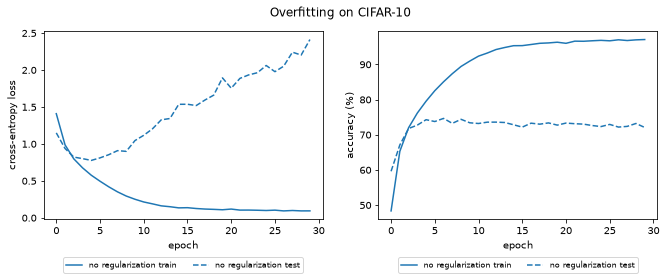

규제 없음: test loss 최저 0.776 (epoch 4), 마지막 2.412 | 마지막 정확도 train 97.1% / test 72.1%


In [7]:
plot_history({"no regularization": history_base}, "Overfitting on CIFAR-10")
summarize("규제 없음", history_base)

교과서 같은 과적합입니다. 학습 loss는 0.09까지 내려가고 학습 정확도는 97.1%에 이릅니다. 그런데 test loss는 epoch 4에서 0.776으로 가장 낮았다가 이후 올라 마지막에는 2.412가 됩니다. 테스트 정확도는 72~73%에서 멈춰 72.1%로 끝납니다. 학습과 테스트의 정확도 차이가 25%포인트나 납니다.

**Q. 정확도 곡선은 크게 나빠지지 않는데 test loss가 크게 오르는 이유는 무엇일까요?**

<details><summary>답</summary>

정확도는 "가장 높은 클래스가 맞았는가"만 봅니다. Loss는 "얼마나 확신했는가"까지 봅니다. 과적합이 진행된 모델은 틀린 문제에도 아주 높은 확신을 내고, cross-entropy는 그런 답에 큰 벌점을 줍니다. 그래서 맞힌 개수는 비슷해도 loss는 치솟습니다. 과적합을 일찍 알아채려면 정확도만 보지 말고 loss도 보세요.

</details>

## 1.3 Data Augmentation이란

과적합을 막는 가장 직접적인 방법은 데이터를 늘리는 것입니다. Image Augmentation(이미지 증강)은 **이미지 하나에 약간의 변형을 더해 새로운 학습 샘플을 여러 개 만들어 내는 기법**입니다. 아래 코드를 실행하면 말 사진 한 장이 여러 모습으로 바뀌는 것을 볼 수 있습니다.

**왜 필요한가요?** 딥러닝은 좋은 성능을 내고 오버피팅을 막기 위해 굉장히 많은 데이터를 요구합니다. 그런데 아래와 같은 이유로 데이터 수집이 어려운 경우가 생각보다 많습니다.

**라벨링에 드는 돈과 시간**: Object Detection용 데이터를 모은다면 원하는 물체마다 사람이 박스를 그려야 합니다. Classification까지 더하면 그 물체의 클래스도 직접 적어야 합니다. 의료처럼 전문 분야의 데이터라면 비싼 인력을 고용해 라벨링해야 합니다.

**데이터 수집의 어려움**: 의료 데이터는 법적 규제가 심해 구하기 쉽지 않습니다. 위성 영상은 원하는 사진을 찍으려면 위성을 보내야 하는 기회비용이 있습니다. 도로 사진은 직접 차를 몰고 곳곳을 돌아다녀야 합니다.

In [8]:
# 사진 한 장을 여러 번 변형해 봅니다. 실행할 때마다 다른 그림이 나옵니다
sample_image, sample_label = datasets.CIFAR10(root="./data", train=True)[7]
show_aug = v2.Compose([
    v2.RandomResizedCrop(32, scale=(0.6, 1.0)),
    v2.RandomHorizontalFlip(),
    v2.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4),
])

fig, axes = plt.subplots(1, 7, figsize=(11, 1.9))
axes[0].imshow(sample_image)
axes[0].set_title(f"original: {classes[sample_label]}", fontsize=9)
for ax in axes[1:]:
    ax.imshow(show_aug(sample_image))
    ax.set_title("augmented", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


## 1.4 증강은 학습에 어떤 영향을 줄까

[Sebastian Raschka의 글](https://sebastianraschka.com/blog/2023/data-augmentation-pytorch.html)에 증강을 추가한 쪽의 테스트 정확도가 더 높게 나오는 [결과 그림](https://sebastianraschka.com/images/blog/2023/data-augmentation-pytorch/augmentation-results.png)이 있습니다.

직접 확인해 봅시다. 1.2와 **완전히 같은 모델**로, 학습 데이터에만 증강을 넣습니다. 테스트 데이터에는 넣지 않습니다. 시험지를 변형하면 다른 시험이 되기 때문입니다.

- `RandomCrop(32, padding=4)`: 사방에 4칸을 덧댄 뒤 32×32를 무작위로 잘라 물체 위치를 조금씩 옮깁니다.
- `RandomHorizontalFlip()`: 50% 확률로 좌우를 뒤집습니다. 비행기나 고양이는 뒤집어도 비행기, 고양이입니다.

Epoch [0] Loss: 1.5265, Accuracy: 43.83 | Test_loss: 1.1693, Test_accuracy: 58.54


Epoch [5] Loss: 0.8094, Accuracy: 71.67 | Test_loss: 0.7381, Test_accuracy: 74.51


Epoch [10] Loss: 0.6728, Accuracy: 76.46 | Test_loss: 0.6954, Test_accuracy: 76.54


Epoch [15] Loss: 0.6084, Accuracy: 78.64 | Test_loss: 0.6641, Test_accuracy: 77.28


Epoch [20] Loss: 0.5748, Accuracy: 80.07 | Test_loss: 0.6616, Test_accuracy: 77.94


Epoch [25] Loss: 0.5503, Accuracy: 80.93 | Test_loss: 0.6221, Test_accuracy: 79.42


Epoch [29] Loss: 0.5246, Accuracy: 81.46 | Test_loss: 0.5951, Test_accuracy: 79.91
Finished Training


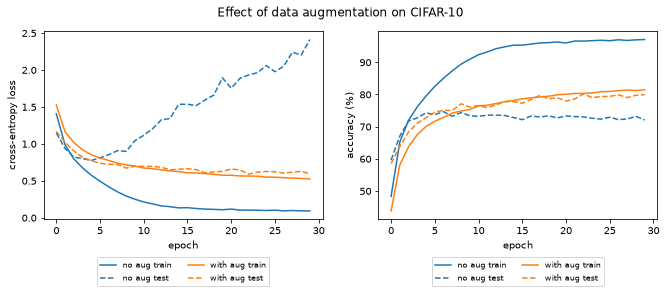

증강 없음: test loss 최저 0.776 (epoch 4), 마지막 2.412 | 마지막 정확도 train 97.1% / test 72.1%
증강 있음: test loss 최저 0.591 (epoch 22), 마지막 0.595 | 마지막 정확도 train 81.5% / test 79.9%


In [9]:
aug_transform = v2.Compose([
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    to_tensor,
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
aug_trainset = datasets.CIFAR10(root="./data", train=True, transform=aug_transform)
aug_trainloader = DataLoader(aug_trainset, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

set_seed()
aug_net = OverfitNet().to(device)
history_aug = fit(aug_net, OVERFIT_EPOCHS, train_loader=aug_trainloader, writer=make_writer("augment"))
plot_history({"no aug": history_base, "with aug": history_aug}, "Effect of data augmentation on CIFAR-10")
summarize("증강 없음", history_base)
summarize("증강 있음", history_aug)

같은 모델인데 결과가 크게 달라졌습니다. 마지막 test loss는 2.412에서 0.595로, 테스트 정확도는 72.1%에서 79.9%로 좋아졌습니다. 학습 정확도는 97.1%에서 81.5%로 내려가서 학습과 테스트의 차이가 거의 사라졌습니다. 증강 쪽 test loss는 epoch 22의 0.591 뒤로도 거의 나빠지지 않습니다. 다만 시드 하나의 결과입니다.

증강을 넣으면 학습 loss가 천천히 떨어지고, 학습 속도 자체도 느려질 수 있습니다. 대신 epoch을 충분히 주면 증강 없는 학습보다 좋은 성능을 내는 경우가 많습니다. 매 epoch마다 조금씩 다른 그림을 보므로 외우기가 어려워지기 때문입니다.

## 1.5 PyTorch로 증강하기

이제 도구를 익혀 봅시다. 먼저 torchvision입니다. 사용할 수 있는 증강의 목록은 [공식 문서](https://pytorch.org/vision/stable/transforms.html)에 있습니다. 공식 문서가 권장하는 **`torchvision.transforms.v2`**를 씁니다. 이미지뿐 아니라 박스와 마스크도 함께 변환할 수 있고, MixUp과 CutMix도 들어 있습니다.

이미지를 신경망에 넣을 텐서로 바꾸는 단계는 두 개입니다. `v2.ToImage()`가 PIL 이미지를 텐서로 바꾸고, `v2.ToDtype(torch.float32, scale=True)`가 0~255를 0~1 실수로 바꿉니다. 첫 코드 셀에서 이 둘을 묶어 `to_tensor`로 만들어 두었습니다. 다른 자료에서 자주 보이는 `transforms.ToTensor()`도 같은 일을 하지만, v2에서는 사용 중단(deprecated) 표시가 붙어 있습니다.

MNIST에 `Resize`, `RandomCrop`, `RandomHorizontalFlip`을 걸어 봅니다. `v2.Compose`는 변환들을 **리스트로** 받아 순서대로 적용합니다.

In [10]:
# 데이터 로드 및 Augmentation 설정
torchvision_transform = v2.Compose([
    v2.Resize((28, 28)),
    v2.RandomCrop(24),
    v2.RandomHorizontalFlip(),
    to_tensor,
])

torch_dataset = datasets.MNIST(root="./data", train=True, transform=torchvision_transform, download=True)
torch_dataloader = DataLoader(torch_dataset, batch_size=4, shuffle=True)

# 클래스 레이블 정의
mnist_classes = ("0", "1", "2", "3", "4", "5", "6", "7", "8", "9")

DataLoader에서 첫 배치를 꺼내 이미지를 출력합니다. 증강은 데이터를 미리 늘려 두는 것이 아니라 **꺼낼 때마다 그 자리에서** 적용됩니다. 그래서 같은 사진도 epoch마다 다르게 보입니다.

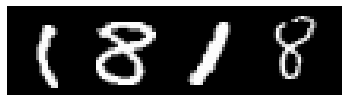

1     8     1     8    


In [11]:
# 데이터셋에서 이미지를 무작위로 가져와서 시각화
data_iter = iter(torch_dataloader)
images, labels = next(data_iter)

plt.figure(figsize=(6, 2))
plt.imshow(torchvision.utils.make_grid(images).permute(1, 2, 0))
plt.axis("off")
plt.show()
print(" ".join(f"{mnist_classes[labels[j]]:5s}" for j in range(4)))

**공식 문서에서 모듈을 가져와 쓰는 법.** [공식 문서](https://pytorch.org/vision/stable/transforms.html)에서 원하는 증강을 고릅니다. 모듈 이름을 눌러 맨 아래의 Example using으로 가면 예제까지 볼 수 있습니다.

예를 들어 `ColorJitter`를 골랐다고 합시다. 초보자가 자주 하는 실수가 두 가지 있습니다. `Compose`에 리스트가 아니라 변환 하나를 그대로 넘기는 것과, 텐서 변환 단계를 빠뜨리는 것입니다. 첫 번째 실수의 에러 메시지를 봅시다.

In [12]:
# 일부러 내는 에러: Compose는 리스트를 받아야 합니다
try:
    v2.Compose(v2.ColorJitter(brightness=.5, hue=.3))
except TypeError as error:
    print("TypeError:", error)

# 올바른 형태입니다. 홈페이지에 있는 다른 파라미터도 같은 방법으로 넘기면 됩니다
transform = v2.Compose([
    v2.ColorJitter(brightness=.5, hue=.3),
    to_tensor,
])

# MNIST는 흑백이라 hue(색조)가 아무 일도 하지 않습니다. 색이 보이도록 CIFAR-10에 겁니다
jitter_dataset = datasets.CIFAR10(root="./data", train=True, transform=transform)
jitter_dataloader = DataLoader(jitter_dataset, batch_size=4, shuffle=True)
jitter_images, _ = next(iter(jitter_dataloader))
plt.figure(figsize=(6, 2))
plt.imshow(torchvision.utils.make_grid(jitter_images).permute(1, 2, 0))
plt.axis("off")
plt.show()

TypeError: Argument transforms should be a sequence of callables


이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


## 1.6 Albumentations로 증강하기

[Albumentations](https://albumentations.ai/docs/)는 NumPy 배열을 다루는 증강 라이브러리입니다. 박스와 마스크까지 함께 변환해 주어 detection과 segmentation에서 많이 씁니다.

> **참고**: 이 저장소는 2025년에 보관(archive) 상태가 되어 더 이상 갱신되지 않습니다. 코드 자체는 지금도 잘 돌아가고(2.0.8에서 확인), 뒤를 잇는 `albumentationsx`는 AGPL 또는 상용 라이선스입니다. 회사 프로젝트라면 라이선스를 확인하고 고르세요.

앞의 torchvision과 같은 변환을 구성합니다. Albumentations는 `image=` 이름을 붙여서 호출해야 하고 **딕셔너리를 돌려줍니다.** torchvision 데이터셋은 `transform(img)` 형태로 호출하므로 바로 넘기면 에러가 납니다. 그래서 첫 코드 셀에 만들어 둔 작은 클래스 `Transforms`로 감쌉니다.

In [13]:
A_transform = A.Compose([
    A.Resize(28, 28),
    A.RandomCrop(24, 24),
    A.HorizontalFlip(),         # v2.RandomHorizontalFlip()과 같습니다
    A.ToFloat(max_value=255),   # 0~255를 0~1로 바꿉니다. 이유는 아래에 있습니다
    ToTensorV2(),
])

# 일부러 내는 에러: 감싸지 않고 호출하면 어떻게 되는지 봅니다
try:
    A_transform(np.zeros((28, 28), dtype=np.uint8))
except (KeyError, TypeError) as error:
    print(type(error).__name__, ":", error)


albumentation_dataset = datasets.MNIST(root="./data", train=True, transform=Transforms(A_transform), download=True)
albumentation_dataloader = DataLoader(albumentation_dataset, batch_size=4, shuffle=True)

KeyError : 'You have to pass data to augmentations as named arguments, for example: aug(image=image)'


첫 배치를 꺼내 확인합니다. 클래스 레이블은 앞에서 정의한 `mnist_classes`를 그대로 씁니다.

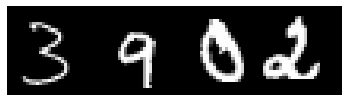

3     9     0     2    
값의 범위: 0.0 ~ 1.0


In [14]:
# 데이터셋에서 이미지를 무작위로 가져와서 시각화
data_iter = iter(albumentation_dataloader)
images, labels = next(data_iter)

plt.figure(figsize=(6, 2))
plt.imshow(torchvision.utils.make_grid(images).permute(1, 2, 0))
plt.axis("off")
plt.show()
print(" ".join(f"{mnist_classes[labels[j]]:5s}" for j in range(4)))
print("값의 범위:", images.min().item(), "~", images.max().item())

> **조심할 점**: `ToTensorV2`는 이름과 달리 앞의 `to_tensor`와 동작이 다릅니다. **255로 나누지 않습니다.** 그대로 쓰면 신경망에 0~255 값이 들어갑니다. 2.2에서 이 차이가 정확도에 어떻게 나타나는지 잽니다. `A.ToFloat`나 `A.Normalize`를 앞에 두세요.

**공식 문서에서 모듈을 가져와 쓰는 법.** [공식 문서](https://albumentations.ai/docs/)에서 변환 목록과 파라미터를 볼 수 있습니다. 모듈 이름이 곧 `A.` 뒤에 쓸 이름이고, 설명에 적힌 파라미터가 실제 인자입니다.

예를 들어 `AdvancedBlur`를 골랐다면 아래처럼 씁니다. `A.Compose`에도 리스트를 넘깁니다.

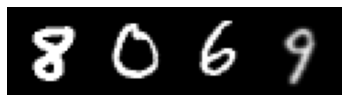

In [15]:
blur_transform = A.Compose([
    A.AdvancedBlur(blur_limit=37, sigma_x_limit=0.5),   # 다른 파라미터도 같은 방법으로 넘기면 됩니다
    A.ToFloat(max_value=255),
    ToTensorV2(),
])

# 아래쪽은 앞에서 실습한 것과 같습니다
blur_dataset = datasets.MNIST(root="./data", train=True, transform=Transforms(blur_transform), download=True)
blur_dataloader = DataLoader(blur_dataset, batch_size=4, shuffle=True)

images, labels = next(iter(blur_dataloader))
plt.figure(figsize=(6, 2))
plt.imshow(torchvision.utils.make_grid(images).permute(1, 2, 0))
plt.axis("off")
plt.show()

## 1.7 torchvision과 Albumentations 속도 비교

Albumentations는 속도를 장점으로 내세웁니다. 같은 파이프라인으로 직접 재 봅니다. 공정하도록 두 쪽 모두 0~1로 바꾸는 단계를 넣었고, 순서 효과를 줄이려고 각각 두 번 잽니다.

In [16]:
def measure_load_time(loader: DataLoader) -> float:
    """데이터 전체를 한 번 꺼내는 데 걸린 시간(초)을 잽니다."""
    start = time.time()
    for _ in loader:
        pass
    return time.time() - start


# 같은 데이터로더를 두 번씩 번갈아 잽니다
for trial in range(2):
    print(f"torch_dataload_time = {measure_load_time(torch_dataloader):.4f} sec")
    print(f"albumentation_dataload_time = {measure_load_time(albumentation_dataloader):.4f} sec")

torch_dataload_time = 3.4575 sec


albumentation_dataload_time = 1.5626 sec


torch_dataload_time = 3.3252 sec


albumentation_dataload_time = 1.6098 sec


이 실행에서는 torchvision이 약 3.39초(3.46, 3.33), Albumentations가 약 1.59초(1.56, 1.61)로 Albumentations가 약 2배 빨랐습니다. 여기서는 PIL 이미지를 한 장씩 변환하는 경우입니다. torchvision 문서는 텐서 입력을 쓰면 더 빠르다고 안내하니, 입력 형식에 따라 차이는 달라질 수 있습니다.

속도는 라이브러리 이름보다 어떤 변환을 쓰는지, 입력 크기가 얼마인지에 크게 좌우됩니다. MNIST는 28×28로 아주 작아서 차이가 절대 시간으로는 작습니다. 큰 사진을 쓸 때 데이터 로딩이 병목이면 그때 직접 재 보고 고르세요.

셀 하나의 시간을 잴 때는 `time.time()`을 직접 쓰지 않고, 셀 첫 줄에 `%%time`을 적어도 됩니다.

In [17]:
%%time
for images, labels in albumentation_dataloader:
    pass

CPU times: user 1.59 s, sys: 6.15 ms, total: 1.6 s
Wall time: 1.6 s


## 1부 실습

MNIST 첫 번째 이미지에 `RandomRotation(30)`과 `to_tensor`를 차례로 적용하는 `rotate_transform`을 만드세요. 같은 이미지에 두 번 적용한 결과 `first`, `second`가 서로 다른지 확인합니다. 값의 범위는 0~1이어야 합니다.

In [18]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
mnist_image, _ = datasets.MNIST(root="./data", train=True)[0]
rotate_transform = v2.Compose([
    v2.RandomRotation(30),
    to_tensor,
])
first = rotate_transform(mnist_image)
second = rotate_transform(mnist_image)
print(first.shape, first.max().item())
assert first.shape == (1, 28, 28)
assert not torch.equal(first, second)   # 호출할 때마다 각도가 달라집니다
assert 0 <= first.min() and first.max() <= 1
```
</details>

---
# 2부. 증강 고르기: 좋은 증강과 지금의 기본 조합

## 2.1 좋은 증강을 고르는 방법

증강은 **데이터의 유효한 정보를 잘 보존하면서 다양성을 많이 늘리는** 방법이 좋습니다.

**예시 1: 고양이 사진.** 고양이는 돌리든 뒤집든 고양이입니다. ([참고 그림](https://blog.kakaocdn.net/dn/b7fmua/btqWVSMBevN/BzTdTP90jwXk00i2sEtZ81/img.png)) 다만 "정보가 보존되는가"만으로 끝나지 않습니다. 실제 서비스에 거꾸로 된 고양이 사진이 전혀 들어오지 않는다면, 그 변형을 배우는 데 모델의 능력을 쓸 이유가 적습니다. **테스트 때 만날 법한 변형인가**도 함께 따지세요.

**예시 2: 숫자.** 5를 상하로 뒤집으면 2와 구분하기 어려워지고, 6을 상하좌우로 뒤집으면(180도 회전) 9와 구분할 수 없습니다. **증강으로 자기 정보를 잃는 것입니다.** ([참고 그림](https://www.researchgate.net/publication/346701220/figure/fig2/AS:966307725996033@1607397123511/Examples-of-data-augmentation-transformations-on-an-image-from-the-MNIST-dataset-a.jpg)) 실제 MNIST로 봅시다. 앞 절의 `HorizontalFlip`도 숫자에는 어울리지 않는 증강이었습니다.

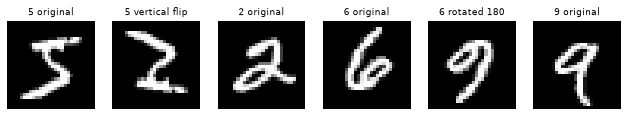

In [19]:
# 라벨은 그대로인데 그림의 뜻이 바뀌는 사례를 실제 MNIST로 만듭니다
raw_mnist = datasets.MNIST(root="./data", train=True)


def first_image_of(digit: int) -> torch.Tensor:
    """해당 숫자의 첫 번째 이미지를 텐서로 돌려줍니다."""
    index = (raw_mnist.targets == digit).nonzero()[0].item()
    return raw_mnist.data[index]


examples = [
    ("5 original", first_image_of(5)),
    ("5 vertical flip", first_image_of(5).flip(0)),
    ("2 original", first_image_of(2)),
    ("6 original", first_image_of(6)),
    ("6 rotated 180", first_image_of(6).flip(0).flip(1)),
    ("9 original", first_image_of(9)),
]
fig, axes = plt.subplots(1, 6, figsize=(11, 2))
for ax, (title, image) in zip(axes, examples):
    ax.imshow(image, cmap="gray")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.show()

## 2.2 원하는 증강을 골라 MNIST 분류기의 성능을 올려 보기

모델은 고정하고 **증강만 바꿉니다.** 아래 두 데이터로더 셀에 주석으로 후보를 적어 두었으니, 숙제에서 주석을 풀어 가며 직접 실험하세요. 증강은 학습 데이터에만 걸리고, 테스트 데이터는 그대로입니다. `Normalize`는 증강이 아니라 입력 범위를 맞추는 전처리이므로 후보에 넣지 않았습니다. 쓰려면 **학습과 테스트에 똑같이** 넣어야 합니다(`to_tensor` 뒤에 두고, 3.7의 `bn_transform`처럼 씁니다). 한쪽에만 넣으면 입력 범위가 어긋나는데도 에러가 나지 않습니다. 증강을 추가했으니 train loss가 떨어지는 속도는 조금 느릴 수 있습니다.

학습 코드를 함수로 묶습니다. 모델만 바꾸면 3부에도 그대로 쓸 수 있습니다.

> **흔한 실수**: 데이터로더 셀 두 개가 같은 변수 이름을 쓰면 나중에 실행한 쪽이 앞쪽을 덮어써서, 비교한다고 생각했지만 한쪽만 학습하게 됩니다. 여기서는 각각 따로 돌려 비교합니다. 앞서 말한 0~255 입력 문제도 함께 재 봅니다.

In [20]:
class MLP(nn.Module):
    """간단한 완전연결 신경망입니다. 모델은 고정하고 증강만 바꿉니다."""

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(-1, 28 * 28)   # 입력을 일렬로 폅니다
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)


def evaluate(model: nn.Module, test_loader: DataLoader) -> float:
    """테스트 정확도(%)를 돌려줍니다."""
    correct, total = 0, 0
    model.eval()
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device, dtype=torch.float32)
            labels = labels.to(device)
            _, predicted = torch.max(model(inputs), 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


def train_and_eval(model: nn.Module, train_loader: DataLoader, test_loader: DataLoader, method: str,
                   epochs: int | None = None, print_every: int = 3, criterion: nn.Module | None = None,
                   make_optimizer: Callable[[Iterable[nn.Parameter]], optim.Optimizer] | None = None) -> float:
    """학습한 뒤 테스트 정확도(%)를 돌려줍니다. 기본은 CrossEntropy와 Adam(lr=0.001)입니다."""
    # 기본값을 호출할 때 읽어야 MNIST_EPOCHS를 바꾼 뒤 이 셀을 다시 돌리지 않아도 반영됩니다
    epochs = MNIST_EPOCHS if epochs is None else epochs
    criterion = criterion or nn.CrossEntropyLoss()
    model.to(device)
    optimizer = make_optimizer(model.parameters()) if make_optimizer else optim.Adam(model.parameters(), lr=0.001)
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        start_time = time.time()
        for inputs, labels in train_loader:
            # 변환에 따라 정수 텐서가 올 수 있어 실수형으로 맞춥니다
            inputs = inputs.to(device, dtype=torch.float32)
            labels = labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        if epoch % print_every == 0 or epoch == epochs - 1:
            print(f"[Epoch {epoch}] Loss: {running_loss / len(train_loader):.4f}, "
                  f"{method}_time = {time.time() - start_time:.2f} sec")
    accuracy = evaluate(model, test_loader)
    print(f"{method} Accuracy on test data: {accuracy:.2f}%")
    return accuracy


# 실험 결과를 모아 두었다가 마지막에 표로 봅니다
mnist_results: dict[str, float] = {}

In [21]:
# PyTorch 증강 모듈 모음: https://pytorch.org/vision/stable/transforms.html
torch_transform = v2.Compose([
    # v2.RandomAffine(20),
    # v2.Resize((28, 28)),
    # v2.CenterCrop((28, 28)),
    to_tensor,
])
plain_test_dataset = datasets.MNIST(root="./data", train=False, transform=to_tensor, download=True)
plain_test_loader = DataLoader(plain_test_dataset, batch_size=64, shuffle=False)

train_dataset = datasets.MNIST(root="./data", train=True, transform=torch_transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

set_seed()
baseline_mlp = MLP()
mnist_results["no augmentation (torch)"] = train_and_eval(baseline_mlp, train_loader, plain_test_loader, "Pytorch")

[Epoch 0] Loss: 0.3520, Pytorch_time = 5.35 sec


[Epoch 3] Loss: 0.0743, Pytorch_time = 5.04 sec


[Epoch 6] Loss: 0.0380, Pytorch_time = 6.98 sec


[Epoch 9] Loss: 0.0237, Pytorch_time = 6.02 sec


Pytorch Accuracy on test data: 97.68%


In [22]:
# Albumentations 모듈 모음: https://albumentations.ai/docs/
A_transform = A.Compose([
    # A.RandomCrop(24, 24), A.Resize(28, 28),   # MLP는 28x28만 받으므로 자른 뒤 크기를 되돌립니다
    # A.HorizontalFlip(),
    A.ToFloat(max_value=255),
    ToTensorV2(),
])
train_dataset = datasets.MNIST(root="./data", train=True, transform=Transforms(A_transform), download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
# 테스트에는 증강을 넣지 않습니다. 위 주석을 풀어도 이쪽은 그대로입니다
A_test_transform = A.Compose([A.ToFloat(max_value=255), ToTensorV2()])
test_dataset = datasets.MNIST(root="./data", train=False, transform=Transforms(A_test_transform), download=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

set_seed()
mnist_results["no augmentation (albumentations)"] = train_and_eval(MLP(), train_loader, test_loader, "Albumentations")

# ToTensorV2만 쓰면 입력이 0~255로 들어갑니다. 무엇이 달라지는지 재 봅니다
raw_transform = Transforms(A.Compose([ToTensorV2()]))
train_dataset = datasets.MNIST(root="./data", train=True, transform=raw_transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = datasets.MNIST(root="./data", train=False, transform=raw_transform, download=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

set_seed()
mnist_results["0-255 input (ToTensorV2 only)"] = train_and_eval(MLP(), train_loader, test_loader, "Raw")

[Epoch 0] Loss: 0.3520, Albumentations_time = 6.56 sec


[Epoch 3] Loss: 0.0744, Albumentations_time = 3.83 sec


[Epoch 6] Loss: 0.0381, Albumentations_time = 4.65 sec


[Epoch 9] Loss: 0.0212, Albumentations_time = 3.81 sec


Albumentations Accuracy on test data: 97.81%


[Epoch 0] Loss: 0.3274, Raw_time = 6.01 sec


[Epoch 3] Loss: 0.1005, Raw_time = 6.03 sec


[Epoch 6] Loss: 0.0792, Raw_time = 4.46 sec


[Epoch 9] Loss: 0.0661, Raw_time = 4.62 sec


Raw Accuracy on test data: 97.27%


숫자에 어울리는 증강을 하나 넣어 봅니다. `RandomAffine(20)`은 ±20도 안에서 살짝 돌립니다. 손글씨는 원래 조금씩 기울어져 있으니 라벨을 해치지 않습니다. 비교 삼아 숫자에 어울리지 않는 `RandomVerticalFlip`(상하 뒤집기)도 돌립니다.

네트워크를 잘 구성하는 것도 중요하지만, 그 전에 **데이터를 열어 보고 분석해서 그 데이터에 맞는 학습을 구성하는 일**이 굉장히 중요합니다.

In [23]:
def run_torch_aug(name: str, train_transform: v2.Compose, seed: int = 1729) -> None:
    """주어진 증강으로 MLP를 학습하고 결과를 표에 추가합니다."""
    dataset = datasets.MNIST(root="./data", train=True, transform=train_transform, download=True)
    loader = DataLoader(dataset, batch_size=64, shuffle=True)
    set_seed(seed)
    mnist_results[name] = train_and_eval(MLP(), loader, plain_test_loader, "Pytorch", print_every=100)


run_torch_aug("RandomAffine(20)", v2.Compose([v2.RandomAffine(20), to_tensor]))
run_torch_aug("RandomVerticalFlip", v2.Compose([v2.RandomVerticalFlip(), to_tensor]))
print(pd.Series(mnist_results, name="test accuracy (%)").round(2).to_string())

[Epoch 0] Loss: 0.4358, Pytorch_time = 6.48 sec


[Epoch 9] Loss: 0.0697, Pytorch_time = 4.55 sec


Pytorch Accuracy on test data: 97.83%


[Epoch 0] Loss: 0.5479, Pytorch_time = 3.88 sec


[Epoch 9] Loss: 0.0789, Pytorch_time = 4.46 sec


Pytorch Accuracy on test data: 96.53%
no augmentation (torch)             97.68
no augmentation (albumentations)    97.81
0-255 input (ToTensorV2 only)       97.27
RandomAffine(20)                    97.83
RandomVerticalFlip                  96.53


표를 읽어 봅시다.

- torchvision은 97.68%, Albumentations는 97.81%입니다. 같은 시드, 증강 없는 같은 데이터라 epoch 6까지의 loss가 소수 셋째 자리까지 같습니다. 13장 차이는 부동소수점의 작은 차이가 쌓인 흔들림으로 봐야 합니다. 라이브러리가 결과를 좌우하지 않습니다.
- 0~255를 그대로 넣은 방식은 97.27%로 조금 낮습니다. 마지막 epoch의 학습 loss도 0.0661로, 0~1 입력의 0.0212보다 세 배 크니 학습이 잘 안 된 것입니다.
- `RandomVerticalFlip`은 96.53%로 떨어졌습니다. 뜻을 해치는 증강의 대가입니다.
- `RandomAffine(20)`은 97.83%로 기준과 0.15%포인트 차이입니다. 테스트 10000장 중 15장이니 시드의 흔들림과 구별하기 어렵습니다. MNIST는 이미 쉬운 문제이고 10 epoch은 짧습니다.

## 2.3 Google의 AutoAugment

어떤 증강이 좋은지 사람이 고르는 대신 찾아 주면 어떨까요? AutoAugment([Cubuk et al., 2018](https://arxiv.org/abs/1805.09501))는 **강화학습으로 좋은 증강 정책(policy)을 탐색합니다.** 정책을 하나 뽑아 작은 모델을 학습시키고, 그 검증 정확도를 보상으로 삼아 다음 정책을 뽑습니다.

의의는 이렇습니다. 이 방법이 나오기 전까지는 사람이 데이터셋을 보고 직관으로 증강을 골랐습니다. 이것을 탐색으로 대체했고, 사람이 고른 증강보다 나은 성능을 보였습니다. 논문은 정책 하나의 효과를 보려면 모델을 80~100 epoch 이상 학습해야 하므로 120 epoch으로 학습했다고 밝힙니다. 데이터셋마다 약 15,000개의 정책을 시험했으니 탐색 비용이 아주 큽니다. ([참고 글](https://deepkerry.tistory.com/27))

정책(policy)은 강화학습에서 모델이 현재 상황을 고려해 선택하는 행동의 규칙이고, 여기서는 "어떤 증강을 얼마나 세게, 어떤 확률로 쓸 것인가"입니다. **정책은 어떤 데이터셋으로 찾았는지에 따라 다릅니다.** 논문에 따르면 CIFAR-10에서는 Equalize 같은 색 위주의 변환이, SVHN(거리의 집 번호 사진)에서는 Invert, Equalize, ShearX/Y, Rotate처럼 숫자에 맞는 변환이 뽑혔습니다.

> **오해하기 쉬운 점**: 아래의 [`v2.AutoAugment`](https://pytorch.org/vision/stable/generated/torchvision.transforms.v2.AutoAugment.html)는 **탐색을 하지 않습니다.** 논문이 이미 찾아 둔 정책 표(`IMAGENET`(기본값), `CIFAR10`, `SVHN`)를 그대로 적용합니다. 그래서 `Compose`에 한 줄 넣는 것으로 끝나고, 내 데이터에 최적이라는 보장은 없습니다.

MNIST는 SVHN처럼 숫자이므로 SVHN 정책을 써 봅니다. 먼저 어떤 그림이 나오는지 봅시다. (공식 문서의 [변환 예시 모음](https://pytorch.org/vision/stable/auto_examples/transforms/plot_transforms_illustrations.html)도 함께 보세요.)

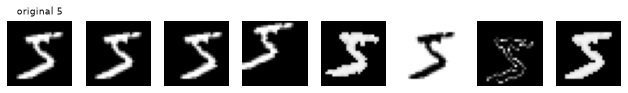

[Epoch 0] Loss: 1.0798, Pytorch_time = 6.24 sec


[Epoch 9] Loss: 0.2834, Pytorch_time = 5.32 sec


Pytorch Accuracy on test data: 97.11%
no augmentation (torch)             97.68
no augmentation (albumentations)    97.81
0-255 input (ToTensorV2 only)       97.27
RandomAffine(20)                    97.83
RandomVerticalFlip                  96.53
AutoAugment(SVHN)                   97.11


In [24]:
# 아래와 같이 Compose에 AutoAugment만 추가하면 바로 쓸 수 있습니다
# 정책 종류: AutoAugmentPolicy.IMAGENET(기본값), AutoAugmentPolicy.CIFAR10, AutoAugmentPolicy.SVHN
auto_transform = v2.Compose([
    v2.AutoAugment(policy=v2.AutoAugmentPolicy.SVHN),
    to_tensor,
])

mnist_image, mnist_label = raw_mnist[0]
fig, axes = plt.subplots(1, 8, figsize=(11, 1.7))
axes[0].imshow(mnist_image, cmap="gray")
axes[0].set_title(f"original {mnist_label}", fontsize=9)
for ax in axes[1:]:
    ax.imshow(auto_transform(mnist_image).squeeze().numpy(), cmap="gray")
for ax in axes:
    ax.axis("off")
plt.show()

run_torch_aug("AutoAugment(SVHN)", auto_transform)
print(pd.Series(mnist_results, name="test accuracy (%)").round(2).to_string())

이번 실행에서 AutoAugment는 97.11%로 증강 없는 97.68%보다 **낮습니다.** 마지막 학습 loss가 0.2834로 아직 높으니 10 epoch으로는 학습이 덜 된 것입니다. 맨 앞 셀의 `MNIST_EPOCHS`를 40으로 바꿔 시드 2개로 이 노트북 밖에서 따로 재 보니, AutoAugment가 증강 없음보다 평균 0.2%포인트 높았습니다(`run_torch_aug`의 `seed` 인자로 재현할 수 있습니다). 시드 수가 적어 확실한 차이라고 하기는 어렵습니다. 증강을 넣으면 학습을 더 오래 해야 합니다.

시드 하나, 10 epoch의 결과이므로 소수점 아래 차이를 믿지는 마세요. 증강의 효과는 epoch을 늘릴수록 뚜렷해지는 경우가 많습니다.

## 2.4 Test Time Augmentation (TTA)

증강을 **테스트 때도** 쓰는 방법입니다. 입력 한 장을 변형해 2장을 더 만들면, 총 3장을 학습된 모델에 각각 넣게 됩니다. 나온 점수를 평균해 최종 클래스를 예측합니다. ([참고 그림](https://user-images.githubusercontent.com/31475037/123568577-94eb1a00-d7ff-11eb-8182-14abc59ce384.png))

```
입력 사진 ──┐
좌우 반전  ──┼─▶ 같은 모델 ─▶ 점수 3개 ─▶ 평균 ─▶ 최종 예측
밝기 변경  ──┘
```

[`ttach`](https://github.com/qubvel/ttach)는 이것을 모델 감싸기 한 번으로 해 줍니다. 오랫동안 갱신되지 않은 패키지지만(0.0.3) 현재 torch에서 동작을 확인했고, 직접 구현해도 몇 줄이면 됩니다(2부 실습).

In [25]:
# 2 * 2 * 3 * 3 = 36가지 조합을 정의합니다
# 변수 이름을 transforms로 지으면 torchvision의 transforms를 쓰는 코드와 헷갈리므로 다른 이름을 씁니다
tta_transforms = tta.Compose([
    tta.HorizontalFlip(),
    tta.Rotate90(angles=[0, 180]),
    tta.Scale(scales=[1, 2, 4]),
    tta.Multiply(factors=[0.9, 1, 1.1]),
])
print("조합 수:", len(tta_transforms))

# 이걸로 모델을 감싸서 model 대신 tta_model을 쓰면 됩니다
# tta_model = tta.ClassificationTTAWrapper(model, tta_transforms, merge_mode="mean")
# merge_mode: "mean", "gmean", "sum", "max", "min", "tsharpen"

조합 수: 36


앞에서 학습한 `baseline_mlp`(증강 없음)로 시험합니다. 먼저 `HorizontalFlip`, `Rotate90`, `Multiply`를 모두 쓴 조합이 어떻게 되는지 봅시다. `Scale`은 입력 크기를 바꾸기 때문에 크기가 고정된 MLP에는 쓸 수 없어서 뺐습니다.

In [26]:
def evaluate_tta(model: nn.Module, test_loader: DataLoader, aug: tta.Compose, name: str) -> float:
    """모델을 ttach로 감싸 정확도를 잽니다."""
    # ClassificationTTAWrapper는 모델 출력(여기서는 softmax 전의 logit)을 평균합니다
    tta_model = tta.ClassificationTTAWrapper(model, aug, merge_mode="mean")
    accuracy = evaluate(tta_model, test_loader)
    print(f"{name}: {accuracy:.2f}% (입력 한 장을 {len(aug)}번 추론)")
    return accuracy


print(f"TTA 없음: {evaluate(baseline_mlp, plain_test_loader):.2f}%")
evaluate_tta(baseline_mlp, plain_test_loader,
             tta.Compose([tta.HorizontalFlip(), tta.Rotate90(angles=[0, 180]), tta.Multiply(factors=[0.9, 1, 1.1])]),
             "뒤집기+180도 회전+밝기")
evaluate_tta(baseline_mlp, plain_test_loader, tta.Compose([tta.Multiply(factors=[0.9, 1, 1.1])]), "밝기만")


class ShiftTTA(nn.Module):
    """숫자의 뜻을 해치지 않는 변형(1칸 평행이동)으로 직접 만든 TTA입니다. ttach에는 평행이동이 없습니다."""

    def __init__(self, model: nn.Module, shifts: tuple[tuple[int, int], ...] = ((0, 0), (1, 0), (-1, 0), (0, 1), (0, -1))):
        super().__init__()
        self.model = model
        self.shifts = shifts

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        outputs = [self.model(torch.roll(x, shifts=s, dims=(2, 3))) for s in self.shifts]
        return torch.stack(outputs).mean(dim=0)


print(f"직접 만든 평행이동 TTA: {evaluate(ShiftTTA(baseline_mlp), plain_test_loader):.2f}%")

TTA 없음: 97.68%


뒤집기+180도 회전+밝기: 62.60% (입력 한 장을 12번 추론)


밝기만: 97.68% (입력 한 장을 3번 추론)


직접 만든 평행이동 TTA: 97.81%


결과가 말해 줍니다. TTA 없음 97.68%에서 뒤집기와 회전을 섞은 조합은 **62.60%**로 무너집니다. 밝기만 바꾸는 TTA는 97.68%로 변화가 없고, 평행이동 TTA는 97.81%로 조금 오릅니다.

**TTA에도 2.1의 규칙이 그대로 적용됩니다.** 뜻을 바꾸는 변형을 섞으면 뒤집힌 숫자에 대한 엉뚱한 점수가 평균에 들어가 오히려 망가집니다.

좌우 반전이 자연스러운 CIFAR-10에서는 어떨까요? 1.4에서 좌우 반전으로 학습한 `aug_net`으로 시험합니다.

In [27]:
print(f"TTA 없음: {evaluate(aug_net, testloader):.2f}%")
_ = evaluate_tta(aug_net, testloader, tta.Compose([tta.HorizontalFlip()]), "좌우 반전 TTA")

TTA 없음: 79.91%


좌우 반전 TTA: 82.62% (입력 한 장을 2번 추론)


79.91%에서 82.62%로 2.7%포인트 올랐습니다. 학습을 더 하지 않고, 추론을 두 번 한 것만으로 얻은 개선입니다.

TTA는 추론 시간이 변형 수만큼 늘어나는 대신 학습을 다시 할 필요가 없습니다. 대회나 오프라인 평가에서 자주 쓰고, 지연 시간이 중요한 서비스에서는 비용을 따져 봐야 합니다.

## 2.5 지금의 기본 조합: TrivialAugment, MixUp, CutMix

AutoAugment의 탐색 비용을 없앤 후속 방법이 있습니다. **`TrivialAugmentWide`**는 탐색도 설정도 없이, 이미지마다 변환 하나와 세기를 무작위로 고릅니다. 입문자가 처음 고를 자동 증강으로 좋습니다. 비슷한 `RandAugment`는 변환 개수와 세기를 인자로 줍니다.

- **`RandomErasing`**: 사진의 일부 사각형을 지웁니다. 텐서 변환 뒤에 둡니다.
- **MixUp**: 두 사진을 비율대로 겹치고, 정답도 같은 비율로 섞습니다.
- **CutMix**: 한 사진의 사각형 영역을 다른 사진으로 바꾸고, 넓이 비율대로 정답을 섞습니다.

MixUp과 CutMix는 두 사진을 쓰므로 **배치 단위로** 적용합니다. 정답이 확률 벡터가 되지만 `CrossEntropyLoss`는 이런 정답도 받습니다. 학습 정확도는 정확히 정의되지 않으니 가장 큰 클래스와 비교한 참고값으로 보세요.

TorchVision은 이런 재료를 묶은 레시피로 ImageNet 사전학습 가중치를 새로 학습했습니다([공식 블로그](https://pytorch.org/blog/how-to-train-state-of-the-art-models-using-torchvision-latest-primitives/)). TrivialAugment, RandomErasing, Label Smoothing(`nn.CrossEntropyLoss(label_smoothing=0.1)`), MixUp, CutMix가 그 일부입니다. 다만 600 epoch을 학습한 레시피입니다. **강한 증강은 긴 학습과 짝을 이룹니다.** 1.4와 같은 모델, 같은 30 epoch으로 어떤지 재 봅시다.

Epoch [0] Loss: 1.8728, Accuracy: 30.29 | Test_loss: 1.3382, Test_accuracy: 52.83


Epoch [5] Loss: 1.3322, Accuracy: 52.26 | Test_loss: 0.9142, Test_accuracy: 68.05


Epoch [10] Loss: 1.2197, Accuracy: 56.76 | Test_loss: 0.8063, Test_accuracy: 72.4


Epoch [15] Loss: 1.1575, Accuracy: 59.13 | Test_loss: 0.7522, Test_accuracy: 73.51


Epoch [20] Loss: 1.1245, Accuracy: 60.19 | Test_loss: 0.6788, Test_accuracy: 76.39


Epoch [25] Loss: 1.0924, Accuracy: 61.54 | Test_loss: 0.6528, Test_accuracy: 77.24


... (4 outputs left out)

Epoch [15] Loss: 1.5203, Accuracy: 58.75 | Test_loss: 0.7952, Test_accuracy: 76.23


Epoch [20] Loss: 1.5027, Accuracy: 59.65 | Test_loss: 0.7885, Test_accuracy: 75.69


Epoch [25] Loss: 1.4851, Accuracy: 60.19 | Test_loss: 0.7787, Test_accuracy: 76.56


Epoch [29] Loss: 1.4668, Accuracy: 61.2 | Test_loss: 0.7534, Test_accuracy: 76.8
Finished Training


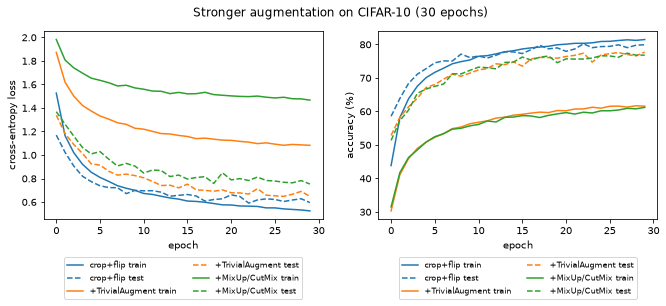

crop+flip: test loss 최저 0.591 (epoch 22), 마지막 0.595 | 마지막 정확도 train 81.5% / test 79.9%
+TrivialAugment: test loss 최저 0.647 (epoch 29), 마지막 0.647 | 마지막 정확도 train 61.6% / test 77.7%
+MixUp/CutMix: test loss 최저 0.753 (epoch 29), 마지막 0.753 | 마지막 정확도 train 61.2% / test 76.8%


In [28]:
trivial_transform = v2.Compose([
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    v2.TrivialAugmentWide(),
    to_tensor,
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    v2.RandomErasing(p=0.1),
])
trivial_loader = DataLoader(datasets.CIFAR10(root="./data", train=True, transform=trivial_transform),
                            batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

set_seed()
history_trivial = fit(OverfitNet().to(device), OVERFIT_EPOCHS, train_loader=trivial_loader, writer=make_writer("trivial"))

# 배치마다 MixUp과 CutMix 중 하나를 고릅니다
mix_transform = v2.RandomChoice([v2.CutMix(num_classes=10), v2.MixUp(num_classes=10)])
set_seed()
history_mix = fit(OverfitNet().to(device), OVERFIT_EPOCHS, train_loader=aug_trainloader, writer=make_writer("mix"), batch_transform=mix_transform)

plot_history({"crop+flip": history_aug, "+TrivialAugment": history_trivial, "+MixUp/CutMix": history_mix}, "Stronger augmentation on CIFAR-10 (30 epochs)")
summarize("crop+flip", history_aug)
summarize("+TrivialAugment", history_trivial)
summarize("+MixUp/CutMix", history_mix)

30 epoch에서는 강한 증강이 **더 낮습니다.** 테스트 정확도는 crop+flip 79.9%, TrivialAugment를 더하면 77.7%, MixUp과 CutMix를 더하면 76.8%입니다. 강한 증강 쪽 학습 정확도는 61%대에 머물러 아직 학습이 덜 되었고, test loss도 두 쪽 모두 마지막 epoch에서 가장 낮으니 아직 내려가는 중입니다. 대신 과적합은 보이지 않습니다. 증강된 학습 문제가 더 어려워서 학습 정확도가 오히려 테스트 정확도보다 낮습니다. MixUp과 CutMix는 정답이 섞여 있어 학습 loss가 높게 나오는 것이 정상입니다. 이 작은 모델과 짧은 학습으로는 crop+flip이 좋은 출발점이고, 강한 증강은 큰 모델을 오래 학습할 때 시도하세요. 이 실험은 30 epoch 한 번의 결과일 뿐, 긴 학습에서의 우열은 재지 않았습니다.

## 2부 실습

ttach 없이 좌우 반전 TTA를 직접 구현하세요. `flip_tta(model, x)`는 입력 `x`와 좌우 반전한 `x`를 모델에 넣어 나온 **출력의 평균**을 돌려줍니다. 입력은 `(N, C, H, W)` 모양이고 좌우는 3번 축입니다. `aug_net`의 첫 배치에서 ttach와 같은 값이 나오는지 확인하세요.

In [29]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def flip_tta(model: nn.Module, x: torch.Tensor) -> torch.Tensor:
    return (model(x) + model(x.flip(3))) / 2


aug_net.eval()
batch_x, _ = next(iter(testloader))
batch_x = batch_x.to(device)
with torch.no_grad():
    mine = flip_tta(aug_net, batch_x)
    wrapper = tta.ClassificationTTAWrapper(aug_net, tta.Compose([tta.HorizontalFlip()]), merge_mode="mean")
    theirs = wrapper(batch_x)
print((mine - theirs).abs().max().item())
assert mine.shape == (batch_size, 10)
assert torch.allclose(mine, theirs, atol=1e-4)
```
</details>

---
# 3부. Batch Normalization과 Dropout

## 3.1 Covariate Shift

고양이와 강아지를 분류하는 모델을 학습시킨다고 합시다. 학습 데이터의 고양이 사진은 '러시안 블루'종뿐인데, 테스트에서는 '페르시안'종을 분류하려고 합니다. 모델이 잘 해낼까요? 학습 데이터와 테스트 데이터의 분포가 다르므로 성능이 떨어질 것입니다. 이처럼 **학습 데이터와 테스트 데이터의 입력 분포가 다른 현상을 covariate shift**라고 부릅니다. ([참고 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fbrz8Im%2Fbtq4CijbLUR%2FBaeMc4KJijoX1CdxqjKUr1%2Fimg.png), [글](https://cvml.tistory.com/m/5))

## 3.2 Internal Covariate Shift

BatchNorm 논문은 위의 현상이 **층마다** 일어난다고 봤습니다. 층을 지날 때마다 입력의 분포가 달라지고, 층을 지날수록 변형이 심해져 학습에 나쁜 영향을 준다는 것입니다. 또 앞 층의 파라미터가 업데이트되면 다음 층은 업데이트 전후로 다른 분포의 입력을 받게 됩니다. 뒤 층 입장에서는 시험 범위가 계속 바뀌는 셈입니다. ([참고 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcyscr7%2Fbtq4AtZz7ST%2FOXf1ywXwrkCaNhT8bQCaO1%2Fimg.png), [글](https://cvml.tistory.com/m/5))

실제로 그런지 잽시다. 작은 MLP를 학습하면서 세 번째 Sigmoid에 들어가는 값의 평균과 표준편차를 기록합니다.

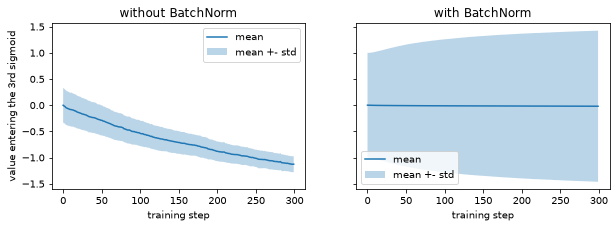

In [30]:
def record_layer_stats(use_bn: bool, steps: int = 300) -> tuple[list[float], list[float]]:
    """학습 중 세 번째 Sigmoid에 들어가는 값의 평균과 표준편차를 기록합니다."""
    set_seed()
    blocks: list[nn.Module] = [nn.Flatten()]
    in_size = 28 * 28
    for _ in range(3):
        blocks.append(nn.Linear(in_size, 64))
        if use_bn:
            blocks.append(nn.BatchNorm1d(64))
        blocks.append(nn.Sigmoid())
        in_size = 64
    blocks.append(nn.Linear(64, 10))
    model = nn.Sequential(*blocks)
    means, stds = [], []
    # 세 번째 Sigmoid 직전의 값을 forward hook으로 엿봅니다
    watched = [m for m in model if isinstance(m, nn.BatchNorm1d if use_bn else nn.Linear)][2]

    def record(_module: nn.Module, _inputs: tuple[torch.Tensor], output: torch.Tensor) -> None:
        # hook이 값을 돌려주면 층의 출력이 그 값으로 바뀌므로 아무것도 돌려주지 않습니다
        means.append(output.mean().item())
        stds.append(output.std().item())

    hook = watched.register_forward_hook(record)
    optimizer = optim.SGD(model.parameters(), lr=0.5)
    loader = DataLoader(datasets.MNIST(root="./data", train=True, transform=to_tensor), batch_size=64, shuffle=True)
    for step, (x, y) in enumerate(loader):
        if step == steps:
            break
        optimizer.zero_grad()
        F.cross_entropy(model(x), y).backward()
        optimizer.step()
    hook.remove()
    return means, stds


fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, use_bn, title in zip(axes, [False, True], ["without BatchNorm", "with BatchNorm"]):
    means, stds = record_layer_stats(use_bn)
    means, stds = np.array(means), np.array(stds)
    ax.plot(means, label="mean")
    ax.fill_between(range(len(means)), means - stds, means + stds, alpha=0.3, label="mean +- std")
    ax.set_title(title)
    ax.set_xlabel("training step")
    ax.legend()
axes[0].set_ylabel("value entering the 3rd sigmoid")
plt.show()

BatchNorm이 없으면 값의 평균이 학습 내내 0 근처에서 약 -1.1까지 흘러가고, 흩어진 정도는 오히려 줄어듭니다. 다음 층 입장에서는 입력 분포가 계속 바뀌는 것입니다. BatchNorm이 있으면 평균이 0에 머무르고, 표준편차는 1에서 1.4 정도로 천천히 변합니다. 정규화 뒤에 곱하는 학습 파라미터가 조금씩 커지기 때문인데, 이 파라미터($\gamma$)는 3.4에서 정의합니다.

> **더 알아 두기**: "BatchNorm은 internal covariate shift를 줄여서 학습을 돕는다"는 설명은 논문 제목에도 있고 널리 알려졌지만, 지금은 그것이 진짜 이유인지 의심받습니다. [Santurkar et al. (2018)](https://arxiv.org/abs/1805.11604)은 BatchNorm 뒤에 일부러 잡음을 넣어 분포를 흔들어도 학습이 여전히 잘 된다는 것을 보였고, 진짜 효과는 **loss 지형을 매끄럽게 만드는 것**이라고 주장했습니다. BatchNorm이 잘 듣는다는 사실 자체는 변함없고, "왜"에 대한 설명이 바뀌고 있는 셈입니다.

## 3.3 Whitening

분포가 문제라면 입력을 고정된 분포로 바꾸면 되지 않을까요? 그런 방법 중 하나가 whitening입니다. **평균을 0으로 옮기고 분산을 1로 맞출 뿐 아니라, 변수 사이의 상관관계까지 없앱니다.** 평균 0, 표준편차 1로 바꾸기만 하는 것은 표준화이고, whitening에는 상관 제거가 더 들어갑니다. 아래 그림의 가운데와 오른쪽 차이입니다. ([참고 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcpCNWE%2Fbtq4HZWzSfK%2FhLFtMWpqfo0xclWf20dNo0%2Fimg.png))

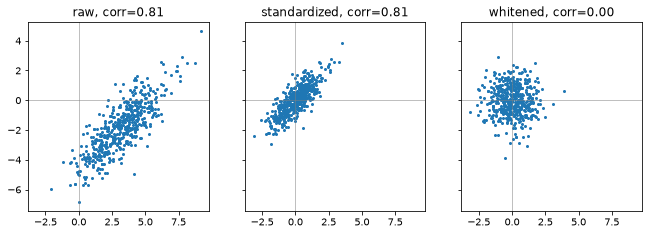

In [31]:
# 상관된 2차원 데이터를 만들어 표준화와 whitening을 비교합니다
rng = np.random.default_rng(0)
X_raw = rng.multivariate_normal([3, -2], [[3.0, 2.4], [2.4, 3.0]], size=500)

X_center = X_raw - X_raw.mean(axis=0)
X_std = X_center / X_raw.std(axis=0)
eigvals, eigvecs = np.linalg.eigh(np.cov(X_center, rowvar=False))
X_white = X_center @ eigvecs / np.sqrt(eigvals)   # 고유벡터로 돌리고 각 축의 분산을 1로 맞춥니다

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
for ax, data, title in zip(axes, [X_raw, X_std, X_white], ["raw", "standardized", "whitened"]):
    ax.scatter(data[:, 0], data[:, 1], s=4)
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.set_title(f"{title}, corr={np.corrcoef(data, rowvar=False)[0, 1]:.2f}")
plt.show()

그런데 각 층의 입력에 whitening을 하려니 문제가 생깁니다.

1. 공분산 행렬을 구하고 그 역행렬까지 계산해야 해서 비쌉니다.
2. 정규화를 **gradient 계산 밖에서** 하면 파라미터 업데이트와 상쇄됩니다. 논문의 예시를 봅시다. 입력 $u$와 학습 파라미터 $b$가 있고 $x = u + b$일 때 평균을 빼는 정규화를 합니다.

$$\hat{x} = x - \mathbb{E}[x] \quad \text{where, } \mathbb{E}[x] = \frac{1}{N} \sum_{i=1}^{N} x_i$$

gradient가 정규화의 존재를 모른 채 $b$를 $\Delta b$만큼 바꾸면 다음과 같이 됩니다.

$$u + (b + \Delta b) - \mathbb{E}[u + (b + \Delta b)] = u + b - \mathbb{E}[u + b]$$

$\Delta b$로 $b$를 업데이트했는데 정규화된 출력이 그대로입니다. 출력이 안 바뀌니 loss도 그대로이고, $b$는 무한정 커질 수 있습니다. 업데이트가 정규화에 무시된 것입니다.

## 3.4 Batch Normalization

BatchNorm은 이 두 문제를 이렇게 풉니다. 상관 제거는 포기하고 **차원(feature)마다 따로** 정규화합니다. 그리고 **미니배치 통계**로 계산하는 **신경망의 층**으로 만들어 gradient가 정규화까지 통과하게 합니다. ([참고 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FENgn2%2Fbtq4F27Avlg%2F0lGC2vYOp4lHIrW1SUFDo0%2Fimg.png), [글](https://cvml.tistory.com/m/5))

크기 $m$인 미니배치 $B$의 평균과 분산을 구합니다.

$$\mu_{B}\leftarrow\frac{1}{m}\sum_{i=1}^{m}x_{i}$$

$$\sigma^{2}_{B}\leftarrow\frac{1}{m}\sum_{i=1}^{m}\left( x_{i}-\mu_{B} \right)^{2}$$

입력의 각 차원별로 정규화합니다. $\epsilon$은 0으로 나누는 것을 막기 위한 작은 값입니다.

$$\hat{x}_{i}\leftarrow\frac{x_{i}-\mu_{B}}{\sqrt{\sigma^{2}_{B}+\epsilon}}$$

정규화된 값에 Scale factor($\gamma$)와 Shift factor($\beta$)를 적용합니다. $\gamma, \beta$는 **학습 가능한 파라미터**입니다.

$$y_{i}\leftarrow\gamma\hat{x}_{i}+\beta\equiv BN_{\gamma,\beta}\left(x_{i}\right)$$

수식을 그대로 코드로 옮겨 `nn.BatchNorm1d`와 비교해 봅시다.

In [32]:
set_seed()
x_batch = torch.randn(8, 3) * 3 + 5     # 배치 8개, 특징 3개. 평균 5, 표준편차 3 근처입니다
bn = nn.BatchNorm1d(3)
bn_output = bn(x_batch)

mu = x_batch.mean(dim=0)
var = x_batch.var(dim=0, unbiased=False)  # 수식처럼 m으로 나눕니다 (m-1이 아닙니다)
x_hat = (x_batch - mu) / torch.sqrt(var + bn.eps)
manual = bn.weight * x_hat + bn.bias      # weight가 gamma, bias가 beta입니다

print("nn.BatchNorm1d와 수식의 최대 차이:", (bn_output - manual).abs().max().item())
print("출력 평균:", bn_output.mean(dim=0).detach().numpy().round(4))
print("출력 표준편차:", bn_output.std(dim=0, unbiased=False).detach().numpy().round(4))
print("학습 파라미터:", [name for name, _ in bn.named_parameters()], "/ 학습하지 않는 통계:", [name for name, _ in bn.named_buffers()])
assert torch.allclose(bn_output, manual, atol=1e-5)

nn.BatchNorm1d와 수식의 최대 차이: 2.384185791015625e-07
출력 평균: [-0. -0. -0.]
출력 표준편차: [1. 1. 1.]
학습 파라미터: ['weight', 'bias'] / 학습하지 않는 통계: ['running_mean', 'running_var', 'num_batches_tracked']


**Scale factor는 왜 있을까요?** 정규화를 하면 값이 0 근처로 모입니다. 다음에 만나는 함수가 sigmoid라면 0 근처는 거의 직선이라, 비선형성이 부족해 층을 쌓은 의미가 줄어듭니다. 그래서 정규화된 값을 다시 늘리고 옮길 수 있도록 $\gamma, \beta$를 둡니다. 필요하다면 학습을 통해 정규화 이전으로 되돌릴 수도 있습니다($\gamma=\sigma, \beta=\mu$). ([참고 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FlDXk8%2FbtrKoS5zWel%2FwnZUe8Qa8cdPLvnMyMz2k0%2Fimg.png), [글](https://killerwhale0917.tistory.com/13))

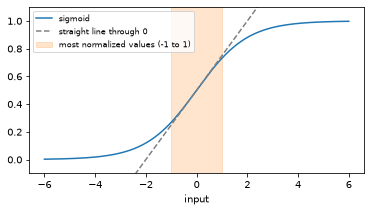

In [33]:
z = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(z, 1 / (1 + np.exp(-z)), label="sigmoid")
ax.plot(z, 0.5 + z / 4, "--", color="gray", label="straight line through 0")
ax.axvspan(-1, 1, alpha=0.2, color="tab:orange", label="most normalized values (-1 to 1)")
ax.set_ylim(-0.1, 1.1)
ax.set_xlabel("input")
ax.legend(fontsize=8)
plt.show()

## 3.5 추론할 때의 BatchNorm

학습이 끝난 뒤 추론할 때는 BatchNorm이 어떻게 정규화를 할까요? 테스트 데이터 **한 장**에 대해 답을 내야 할 수도 있으니 배치의 평균과 분산을 계산할 수 없습니다. 또 같은 사진이 함께 들어온 다른 사진에 따라 다른 답을 받으면 곤란합니다.

그래서 추론 때는 **training set의 평균과 분산으로 대체**합니다. 학습 때 쓴 미니배치 통계로 이것을 추정하는 방법이 크게 2가지 있습니다.

**모집단 추정 방식**: 표본평균들의 평균은 모집단의 평균을 추정한다는 성질을 이용합니다.

$$E \left [ x^{\left(k\right)}\right] = E_{B}\left[\mu^{\left(k\right)}_{B}\right]$$

$$Var\left[x^{\left(k\right)}\right] = \frac{m}{m-1}E_{B}\left[\sigma^{\left(k\right)^{2}}_{B}\right]$$

**Moving Average 방식**: 직전까지의 값과 현재 배치의 값을 $(\alpha, 1-\alpha)$로 섞는 일을 반복합니다.

$$\hat{\mu}\leftarrow\alpha\hat{\mu}+\left(1-\alpha\right)\mu^{\left(i\right)}_{B}$$

$$\hat{\sigma}\leftarrow\alpha\hat{\sigma}+\left(1-\alpha\right)\sigma^{\left(i\right)}_{B}$$

모든 배치의 값을 저장해야 하는 모집단 추정 방식보다 Moving Average를 많이 씁니다. PyTorch도 이 방식입니다. 다만 **`momentum=0.1`이 위 식의 $1-\alpha$에 해당하고($\alpha=0.9$), 표준편차가 아니라 분산을 이동 평균합니다.** 또 한 가지, 배치를 정규화할 때는 수식처럼 $m$으로 나눈 분산을 쓰지만, `running_var`에는 $m-1$로 나눈 분산을 넣습니다. 아래 코드의 `unbiased=True`가 그 차이입니다. 코드로 확인합시다.

In [34]:
set_seed()
bn = nn.BatchNorm1d(3)     # momentum=0.1이 기본값입니다
batch_1, batch_2 = torch.randn(8, 3) + 2, torch.randn(8, 3) + 2

bn(batch_1)
expected_mean = 0.9 * torch.zeros(3) + 0.1 * batch_1.mean(dim=0)   # running_mean의 초깃값은 0입니다
expected_var = 0.9 * torch.ones(3) + 0.1 * batch_1.var(dim=0, unbiased=True)   # running_var의 초깃값은 1입니다
print("배치 1개 뒤 running_mean:", bn.running_mean.numpy().round(4))
print("직접 계산한 값         :", expected_mean.numpy().round(4))
print("배치 1개 뒤 running_var :", bn.running_var.numpy().round(4))
print("직접 계산한 값         :", expected_var.numpy().round(4))

# 학습 모드와 평가 모드는 같은 입력에도 다른 값을 냅니다
bn.train()
print("\ntrain 모드 출력:", bn(batch_2)[0].detach().numpy().round(3))
bn.eval()
print("eval  모드 출력:", bn(batch_2)[0].detach().numpy().round(3))

# 일부러 내는 에러: 학습 모드에서는 배치 한 장의 분산을 구할 수 없습니다
bn.train()
try:
    bn(torch.randn(1, 3))
except ValueError as error:
    print("\nValueError:", error)
bn.eval()
print("eval 모드에서는 한 장도 됩니다:", bn(torch.randn(1, 3)).shape)

배치 1개 뒤 running_mean: [0.2113 0.1808 0.2079]
직접 계산한 값         : [0.2113 0.1808 0.2079]
배치 1개 뒤 running_var : [0.9531 0.9648 0.9924]
직접 계산한 값         : [0.9531 0.9648 0.9924]

train 모드 출력: [ 0.053 -1.    -0.504]
eval  모드 출력: [2.21  0.581 1.358]

ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 3])
eval 모드에서는 한 장도 됩니다: torch.Size([1, 3])


**추론 전에 `model.eval()`을 잊으면** BatchNorm이 테스트 배치의 통계로 계산하고 running 통계까지 바꿔 버립니다. 입문자가 가장 자주 하는 실수 중 하나입니다.

BatchNorm에 대해 더 알아 두면 좋은 것들입니다.

- 학습 파라미터가 있어 하나의 층(layer)으로 인정받습니다.
- 보통 활성화 함수 직전에 들어갑니다. Scale과 Shift가 있는 이유를 생각하면 자연스럽습니다.
- Convolution, Batch Normalization, Dropout, 활성화 함수가 자주 묶여서 쓰입니다.

**다른 정규화 층**: BatchNorm은 배치가 작으면 통계가 불안정해집니다. 그래서 Transformer와 ConvNeXt 같은 현대 구조는 샘플 하나 안에서 정규화하는 `nn.LayerNorm`을 쓰고, 배치가 작은 detection과 segmentation에서는 `nn.GroupNorm`도 씁니다. 작은 CNN을 직접 만들 때는 BatchNorm이 여전히 좋은 출발점입니다.

논문: Ioffe, Sergey, and Christian Szegedy. "Batch normalization: Accelerating deep network training by reducing internal covariate shift." ICML, 2015. [arXiv:1502.03167](https://arxiv.org/abs/1502.03167)

## 3.6 Dropout의 개념

Dropout은 학습할 때 **서로 연결된 층의 뉴런을 확률적으로 끄고(drop)** 업데이트하는 기법입니다. 아래 그림은 drop rate가 0.5일 때의 예로, 뉴런의 절반가량이 꺼진 모습입니다. ([참고 그림 1](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fm5YtD%2FbtrbwgszFXZ%2FxdUhkeyK2lmrQXYy7HioL0%2Fimg.png) · [참고 그림 2](https://miro.medium.com/v2/resize:fit:1184/format:webp/0*vAy-23gZE8UxGwuL.png))

어떤 뉴런이든 다음 배치에 꺼질 수 있으니 특정 뉴런에 지나치게 의존할 수 없습니다. 노드가 데이터셋에 과하게 맞춰지는 것을 막아 **과적합을 어느 정도 해소**합니다. 매번 다른 부분 네트워크를 학습하므로 일종의 앙상블로 볼 수도 있습니다.

Dropout은 `model.eval()`을 부르면 꺼집니다. "BatchNorm도 꺼진다"고 흔히 말하지만 정확히는 다릅니다. **BatchNorm은 꺼지지 않고, 저장해 둔 통계를 쓰는 쪽으로 동작이 바뀝니다.** 자동으로 일어나는 일도 아닙니다. `model.eval()`을 직접 불러야 합니다. 공식 문서: [`nn.Dropout`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html)

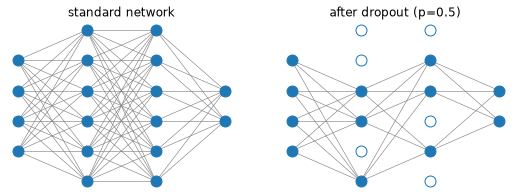

In [35]:
# 은닉층 두 개에 Dropout을 건 모습을 그립니다
layer_sizes = [4, 6, 6, 2]
# 은닉층 뉴런의 절반을 끈 예시입니다. 실제로는 배치마다 무작위로 바뀝니다
keep = [np.ones(4, bool), np.array([1, 0, 1, 1, 0, 0], bool), np.array([0, 1, 0, 1, 1, 0], bool), np.ones(2, bool)]

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, use_drop, title in zip(axes, [False, True], ["standard network", "after dropout (p=0.5)"]):
    positions = [[(i, j - (size - 1) / 2) for j in range(size)] for i, size in enumerate(layer_sizes)]
    for i in range(len(layer_sizes) - 1):
        for a, pa in enumerate(positions[i]):
            for b, pb in enumerate(positions[i + 1]):
                if not use_drop or (keep[i][a] and keep[i + 1][b]):
                    ax.plot([pa[0], pb[0]], [pa[1], pb[1]], color="gray", linewidth=0.6)
    for i, layer in enumerate(positions):
        for j, (px, py) in enumerate(layer):
            alive = not use_drop or keep[i][j]
            ax.scatter(px, py, s=120, zorder=3, color="tab:blue" if alive else "white", edgecolors="tab:blue")
    ax.set_title(title)
    ax.axis("off")
plt.show()

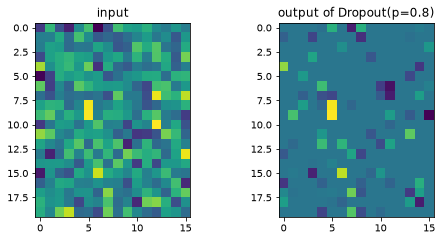

0이 된 비율: 0.7562500238418579
살아남은 값의 배율: 5.0 = 1/(1-0.8)
eval 모드에서 입력과 같은가: True


In [36]:
# p=0.8이면 값의 80%가 0이 됩니다
m = nn.Dropout(p=0.8)
input_tensor = torch.randn(20, 16)
output_tensor = m(input_tensor)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(input_tensor)
axes[0].set_title("input")
axes[1].imshow(output_tensor)
axes[1].set_title("output of Dropout(p=0.8)")
plt.show()

print("0이 된 비율:", (output_tensor == 0).float().mean().item())
# 살아남은 값은 1/(1-p)배로 커집니다. 평균적으로 다음 층이 받는 크기를 평가 때와 맞추기 위해서입니다
survivors = output_tensor != 0
print("살아남은 값의 배율:", (output_tensor[survivors] / input_tensor[survivors]).mean().item(), "= 1/(1-0.8)")
m.eval()
print("eval 모드에서 입력과 같은가:", torch.equal(m(input_tensor), input_tensor))

## 3.7 BatchNorm과 Dropout을 넣은 CNN

MNIST로 CNN을 학습합니다. BatchNorm과 Dropout을 넣은 모델을 돌리고, 효과를 보려고 둘을 뺀 모델도 같이 돌립니다. 코드에 **바꿔 볼 수 있는 곳**을 표시해 두었습니다. 숙제에서 Dropout의 위치와 비율, 옵티마이저를 바꿔 보세요.

참고로 Dropout을 BatchNorm 바로 앞에 두면 학습과 평가 사이에 분산이 어긋나 성능이 떨어질 수 있다는 분석이 있습니다([Li et al., 2018](https://arxiv.org/abs/1801.05134)). 아래 구조에서 위치를 옮겨 비교해 보는 것도 좋은 연습입니다.

코드의 `nn.Dropout2d`는 값 하나하나가 아니라 **채널(특징 맵) 전체를 통째로** 끕니다. 합성곱 특징 맵은 이웃한 값끼리 비슷해서, 값을 하나씩 끄면 주변 값이 같은 정보를 그대로 전하기 때문입니다.

In [37]:
# ---------------------------- 아래쪽을 바꿔 보세요 ----------------------------
bn_transform = v2.Compose([
    to_tensor,
    v2.Normalize((0.5,), (0.5,)),
])
# ------------------------------------------------------------------------------

train_dataset = datasets.MNIST(root="./data", train=True, transform=bn_transform, download=True)
test_dataset = datasets.MNIST(root="./data", train=False, transform=bn_transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


# ---------------------------- 아래쪽을 바꿔 보세요 ----------------------------
class BNNet(nn.Module):
    """BatchNorm과 Dropout을 넣은 CNN입니다. 끄는 옵션은 비교 실험을 위해 추가했습니다."""

    def __init__(self, use_bn: bool = True, use_dropout: bool = True):
        super().__init__()

        def norm(channels: int, dim: int = 2) -> nn.Module:
            if not use_bn:
                return nn.Identity()
            return nn.BatchNorm2d(channels) if dim == 2 else nn.BatchNorm1d(channels)

        self.conv1 = nn.Sequential(nn.Conv2d(1, 32, 3),
                                   nn.Dropout2d(0.25) if use_dropout else nn.Identity(),
                                   norm(32),
                                   nn.ReLU(),
                                   nn.MaxPool2d(2))
        self.conv2 = nn.Sequential(nn.Conv2d(32, 64, 3),
                                   norm(64),
                                   nn.ReLU(),
                                   nn.MaxPool2d(2))
        self.fc_layer = nn.Sequential(nn.Linear(64 * 5 * 5, 128),
                                      norm(128, dim=1),
                                      nn.ReLU(),
                                      nn.Linear(128, 10))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv1(x)
        x = self.conv2(x)
        x = x.view(-1, 64 * 5 * 5)
        return self.fc_layer(x)
# ------------------------------------------------------------------------------


# ---------------------------- 아래쪽을 바꿔 보세요 ----------------------------
bn_criterion = nn.CrossEntropyLoss()


def make_bn_optimizer(params: Iterable[nn.Parameter]) -> optim.Optimizer:
    return optim.Adam(params, lr=0.001)   # 예: optim.SGD(params, lr=0.01, momentum=0.9)
# ------------------------------------------------------------------------------


set_seed()
acc_bn = train_and_eval(BNNet(), train_loader, test_loader, "BN+Dropout", criterion=bn_criterion, make_optimizer=make_bn_optimizer)
set_seed()
acc_plain = train_and_eval(BNNet(use_bn=False, use_dropout=False), train_loader, test_loader, "Plain",
                           criterion=bn_criterion, make_optimizer=make_bn_optimizer)

[Epoch 0] Loss: 0.1324, BN+Dropout_time = 12.53 sec


[Epoch 3] Loss: 0.0253, BN+Dropout_time = 10.62 sec


[Epoch 6] Loss: 0.0151, BN+Dropout_time = 12.20 sec


[Epoch 9] Loss: 0.0103, BN+Dropout_time = 13.03 sec


BN+Dropout Accuracy on test data: 99.04%


[Epoch 0] Loss: 0.1519, Plain_time = 9.62 sec


[Epoch 3] Loss: 0.0227, Plain_time = 10.60 sec


[Epoch 6] Loss: 0.0110, Plain_time = 11.44 sec


[Epoch 9] Loss: 0.0069, Plain_time = 5.23 sec


Plain Accuracy on test data: 99.17%


BatchNorm과 Dropout을 넣은 모델이 99.04%, 뺀 모델이 99.17%로 **사실상 차이가 없습니다**(1만 장 중 13장). 첫 epoch의 loss만 0.1324 대 0.1519로 조금 앞섭니다. 이 정도로 얕은 모델과 쉬운 문제에서는 넣지 않아도 잘 되고, 층이 추가된 만큼 계산은 늘어납니다. 출력의 epoch 시간은 다른 작업과 함께 돌린 값이라 들쭉날쭉하니 비교에 쓰지 마세요. 도구의 효과는 문제에 따라 다르니 **넣기 전과 후를 재 보세요.**

## 3.8 Dropout으로 CIFAR-10 과적합 줄이기

이제 1.2의 과적합 모델로 돌아갑니다. `OverfitNet(dropout=0.25)`로 완전연결층 앞뒤에 Dropout만 켜고 나머지는 그대로 둡니다.

OverfitNet(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=512, out_features=10, bias=True)
  )
)


Epoch [0] Loss: 1.4631, Accuracy: 46.52 | Test_loss: 1.2191, Test_accuracy: 57.37


Epoch [5] Loss: 0.7242, Accuracy: 74.52 | Test_loss: 0.8037, Test_accuracy: 72.09


Epoch [10] Loss: 0.5584, Accuracy: 80.2 | Test_loss: 0.7057, Test_accuracy: 76.11


Epoch [15] Loss: 0.4580, Accuracy: 83.73 | Test_loss: 0.7444, Test_accuracy: 76.17


Epoch [20] Loss: 0.4091, Accuracy: 85.65 | Test_loss: 0.7993, Test_accuracy: 75.43


Epoch [25] Loss: 0.3723, Accuracy: 86.79 | Test_loss: 0.8349, Test_accuracy: 75.12


Epoch [29] Loss: 0.3491, Accuracy: 87.54 | Test_loss: 0.7957, Test_accuracy: 76.04
Finished Training


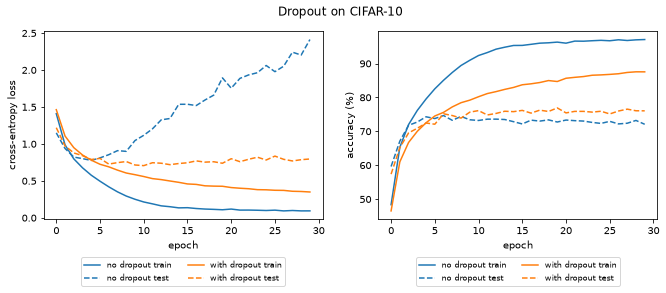

Dropout 없음: test loss 최저 0.776 (epoch 4), 마지막 2.412 | 마지막 정확도 train 97.1% / test 72.1%
Dropout 있음: test loss 최저 0.706 (epoch 10), 마지막 0.796 | 마지막 정확도 train 87.5% / test 76.0%


In [38]:
set_seed()
net_dropout = OverfitNet(dropout=0.25).to(device)
print(net_dropout)
history_dropout = fit(net_dropout, OVERFIT_EPOCHS, writer=make_writer("dropout"))
plot_history({"no dropout": history_base, "with dropout": history_dropout}, "Dropout on CIFAR-10")
summarize("Dropout 없음", history_base)
summarize("Dropout 있음", history_dropout)

Dropout만 켜도 마지막 test loss가 2.412에서 0.796으로, 테스트 정확도가 72.1%에서 76.0%로 좋아졌습니다. 학습 정확도는 97.1%에서 87.5%로 내려갑니다. 다만 test loss는 epoch 10의 0.706 이후 서서히 다시 오르므로 과적합이 사라지지는 않았고 느려졌습니다. 이 실험에서는 1.4의 증강(79.9%)이 더 강했습니다.

## 3.9 작은 CNN으로 오래 학습할 때의 Dropout

이번에는 더 작은 CNN(LeNet 계열)을 **SGD로 150 epoch** 학습합니다. 이 절의 모델과 기록 루프는 [The Python Code의 글](https://thepythoncode.com/article/dropout-regularization-in-pytorch)과 [예제 코드](https://github.com/x4nth055/pythoncode-tutorials/tree/master/machine-learning/dropout-in-pytorch)(MIT, Copyright (c) 2019 Rockikz)를 바탕으로 했습니다. 학습률이 작아 과적합이 천천히 나타나므로 긴 호흡으로 볼 수 있습니다. 배치 크기는 64입니다. 앞 절에서 쓴 `fit`과 달리 1000 iteration마다 기록합니다.

> **흔한 실수**: 평가 함수에서 `eval()`을 부르지 않으면 **Dropout이 켜진 채 test loss를 재게 됩니다.** 그러면 Dropout 모델의 test loss가 실제보다 나쁘게 나옵니다. 아래 `get_test_loss`는 평가 전후로 모드를 전환합니다.

In [39]:
lenet_transform = v2.Compose([
    to_tensor,
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
lenet_batch_size = 64

lenet_train_loader = DataLoader(datasets.CIFAR10(root="./data", train=True, download=True, transform=lenet_transform),
                                batch_size=lenet_batch_size, shuffle=True, num_workers=NUM_WORKERS)
lenet_test_loader = DataLoader(datasets.CIFAR10(root="./data", train=False, download=True, transform=lenet_transform),
                               batch_size=lenet_batch_size, shuffle=False, num_workers=NUM_WORKERS)

In [40]:
class LeNetLike(nn.Module):
    """LeNet 계열의 작은 CNN입니다."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)   # 배치를 뺀 모든 차원을 폅니다
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


class LeNetDropout(LeNetLike):
    """같은 구조에 층별로 다른 비율의 Dropout을 더했습니다."""

    def __init__(self):
        super().__init__()
        self.do1 = nn.Dropout(0.2)   # 20% 확률
        self.do2 = nn.Dropout(0.2)   # 20% 확률
        self.do3 = nn.Dropout(0.1)   # 10% 확률

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.do1(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.do2(x)
        x = F.relu(self.fc2(x))
        x = self.do3(x)
        return self.fc3(x)


def get_test_loss(net: nn.Module, criterion: nn.Module, data_loader: DataLoader) -> float:
    """data_loader 전체를 돌며 평균 loss를 계산합니다."""
    # 평가 중에는 Dropout을 꺼야 합니다. 끝나면 호출한 쪽의 학습을 위해 되돌립니다
    net.eval()
    testing_loss = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            testing_loss.append(criterion(net(inputs), labels).item())
    net.train()
    return sum(testing_loss) / len(testing_loss)


def train_lenet(net: nn.Module, epochs: int) -> tuple[list[float], list[float]]:
    """SGD로 학습하며 1000 iteration마다 train loss와 test loss를 기록합니다."""
    net.to(device)
    net.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
    training_loss, testing_loss, running_loss = [], [], []
    i = 0
    for epoch in range(epochs):
        for inputs, labels in lenet_train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(net(inputs), labels)
            loss.backward()
            optimizer.step()
            running_loss.append(loss.item())
            i += 1
            if i % 1000 == 0:
                avg_train_loss = sum(running_loss) / len(running_loss)
                avg_test_loss = get_test_loss(net, criterion, lenet_test_loader)
                running_loss.clear()
                training_loss.append(avg_train_loss)
                testing_loss.append(avg_test_loss)
                if i % 20000 == 0:   # 로그가 길어지지 않게 2만 번마다 출력합니다
                    print(f"[{epoch:3d}] [it={i:6d}] Train Loss: {avg_train_loss:.3f}, Test Loss: {avg_test_loss:.3f}")
    return training_loss, testing_loss


set_seed()
lenet = LeNetLike()
training_loss, testing_loss = train_lenet(lenet, LENET_EPOCHS)
set_seed()
lenet_dropout = LeNetDropout()
training_loss_d, testing_loss_d = train_lenet(lenet_dropout, LENET_EPOCHS)

[ 25] [it= 20000] Train Loss: 0.982, Test Loss: 1.092


[ 51] [it= 40000] Train Loss: 0.668, Test Loss: 1.122


[ 76] [it= 60000] Train Loss: 0.437, Test Loss: 1.469


[102] [it= 80000] Train Loss: 0.268, Test Loss: 2.104


[127] [it=100000] Train Loss: 0.203, Test Loss: 2.939


[ 25] [it= 20000] Train Loss: 1.212, Test Loss: 1.134


[ 51] [it= 40000] Train Loss: 1.015, Test Loss: 1.005


[ 76] [it= 60000] Train Loss: 0.910, Test Loss: 0.938


[102] [it= 80000] Train Loss: 0.853, Test Loss: 0.926


[127] [it=100000] Train Loss: 0.818, Test Loss: 0.935


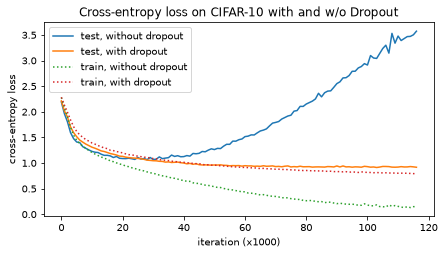

Dropout 없음: test loss 최저 1.065, 마지막 3.573, 정확도 59.71%


Dropout 있음: test loss 최저 0.912, 마지막 0.917, 정확도 68.17%


In [41]:
plt.figure(figsize=(7, 3.5))
plt.plot(testing_loss, label="test, without dropout")
plt.plot(testing_loss_d, label="test, with dropout")
plt.plot(training_loss, linestyle=":", label="train, without dropout")
plt.plot(training_loss_d, linestyle=":", label="train, with dropout")
plt.xlabel("iteration (x1000)")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.title("Cross-entropy loss on CIFAR-10 with and w/o Dropout")
plt.show()
print(f"Dropout 없음: test loss 최저 {min(testing_loss):.3f}, 마지막 {testing_loss[-1]:.3f}, 정확도 {evaluate(lenet, lenet_test_loader):.2f}%")
print(f"Dropout 있음: test loss 최저 {min(testing_loss_d):.3f}, 마지막 {testing_loss_d[-1]:.3f}, 정확도 {evaluate(lenet_dropout, lenet_test_loader):.2f}%")

차이가 뚜렷합니다. Dropout이 없으면 test loss는 1.065까지 내려갔다가 마지막에 3.573까지 치솟고, 정확도는 59.71%로 끝납니다. Dropout을 넣으면 test loss가 0.912까지 내려가 마지막에도 0.917을 유지하고, 정확도는 68.17%입니다. 초반 몇만 iteration만 보면 두 모델의 차이가 작거나 Dropout 쪽이 약간 뒤처집니다. 학습을 충분히 길게 봐야 드러나는 차이입니다.

학습 loss(점선)와 test loss의 간격도 보세요. Dropout 모델은 끝까지 0.1 정도이고, Dropout이 없는 모델은 3 넘게 벌어집니다.

## 3부 실습

`nn.Dropout(p=0.5)`에 1로 채운 `(1000, 1000)` 텐서를 넣어 다음을 확인하세요.

1. 학습 모드 출력 `out_train`에서 0이 된 비율이 약 0.5이다.
2. 0이 아닌 값은 모두 2.0이다(왜 그럴까요?).
3. 평가 모드 출력 `out_eval`은 입력과 같다.

In [42]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
ones = torch.ones(1000, 1000)
drop = nn.Dropout(p=0.5)
out_train = drop(ones)
zero_ratio = (out_train == 0).float().mean().item()
drop.eval()
out_eval = drop(ones)
print(zero_ratio)
assert abs(zero_ratio - 0.5) < 0.01
# 평균 출력이 평가 때와 같도록 살아남은 값을 1/(1-p) = 2배로 키웁니다
assert torch.all(out_train[out_train != 0] == 2.0)
assert torch.equal(out_eval, ones)
```
</details>

---
# 4부. 규제, Early stopping, gradient 문제

## 4.1 Norm: 벡터의 크기를 재는 방법

규제(regularization)를 이해하려면 먼저 Norm을 알아야 합니다. 3부의 정규화(normalization)와는 다른 말입니다. 책에 따라 regularization도 "정규화"로 옮기니 영어를 함께 확인하세요. 벡터 $w$에 대해 다음과 같이 정의합니다.

- **L0**: 0이 아닌 원소의 개수입니다. 엄밀히는 norm이 아니지만 관습적으로 이렇게 부릅니다.
- **L1**: $\|w\|_1 = \sum_i |w_i|$, 절댓값의 합입니다.
- **L2**: $\|w\|_2 = \sqrt{\sum_i w_i^2}$, 원점에서의 직선 거리입니다.
- **L∞**: $\|w\|_\infty = \max_i |w_i|$, 절댓값이 가장 큰 원소입니다.

In [43]:
w_example = torch.tensor([3.0, -4.0, 0.0])
print("L0  :", (w_example != 0).sum().item())
print("L1  :", torch.linalg.vector_norm(w_example, ord=1).item())
print("L2  :", torch.linalg.vector_norm(w_example, ord=2).item())
print("Linf:", torch.linalg.vector_norm(w_example, ord=float("inf")).item())

L0  : 2
L1  : 7.0
L2  : 5.0
Linf: 4.0


## 4.2 L1 Norm과 L2 Norm의 시각화

두 점 사이의 거리로 생각하면 L1은 **바둑판 길을 따라 가는 택시 거리**(taxi distance)이고, L2는 **곧게 가는 유클리드 거리**(Euclidean distance)입니다. 아래 그림에서 초록색이 L2이고 나머지가 L1입니다. L1 경로는 여러 개지만 길이가 모두 같습니다. (참고 그림: [L1](https://velog.velcdn.com/images%2Fsjinu%2Fpost%2F1d14f5ea-98f9-4a28-af7a-09efbbedffcf%2Fimage.png) · [L2](https://velog.velcdn.com/images%2Fsjinu%2Fpost%2F63abb1da-5ee3-41e3-a72a-c0f1f0b7486e%2Fimage.png) · [비교](https://velog.velcdn.com/images%2Fsjinu%2Fpost%2F942e28d3-cc8b-4c09-b752-059044b17e9c%2Fimage.png))

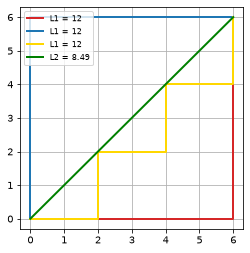

In [44]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 6, 6], [0, 0, 6], color="tab:red", linewidth=2, label="L1 = 12")
ax.plot([0, 0, 6], [0, 6, 6], color="tab:blue", linewidth=2, label="L1 = 12")
ax.plot([0, 2, 2, 4, 4, 6, 6], [0, 0, 2, 2, 4, 4, 6], color="gold", linewidth=2, label="L1 = 12")
ax.plot([0, 6], [0, 6], color="green", linewidth=2, label="L2 = 8.49")
ax.set_xticks(range(7))
ax.set_yticks(range(7))
ax.grid(True)
ax.legend(fontsize=8, loc="upper left")
plt.show()

## 4.3 L1 규제와 L2 규제

과적합된 모델은 가중치가 크게 자라는 경향이 있습니다. 그래서 **가중치의 크기 자체에 벌점을 줍니다.** loss 함수에 패널티 항을 더하는 것입니다. $\lambda$는 패널티의 세기입니다.

**L1 규제(L1 Regularization)** (참고 그림: [L1 식](https://velog.velcdn.com/images%2Fdongho5041%2Fpost%2F451c0978-2d71-49ed-8d73-4352d2332308%2Fimage.png)): $\lambda |w|$가 패널티입니다. $w$에 따라 loss를 증가시킵니다.

$$\text{Cost} = \frac{1}{n}\sum_{i=1}^{n} L(y_i, \hat{y}_i) + \lambda \sum_j |w_j|$$

**L2 규제(L2 Regularization)** (참고 그림: [L2 식](https://velog.velcdn.com/images%2Fdongho5041%2Fpost%2Ff9004c22-7358-4458-b86c-ec67972cdaa7%2Fimage.png)): $\lambda w^2$가 패널티입니다. 그림에 따라 앞에 1/2을 붙이기도 하는데 미분을 깔끔하게 하려는 관습입니다.

$$\text{Cost} = \frac{1}{n}\sum_{i=1}^{n} L(y_i, \hat{y}_i) + \lambda \sum_j w_j^2$$

**의의**: 패널티 때문에 어느 정도의 학습 loss는 남겨 두게 됩니다. 이것이 과적합을 막습니다. 실제로 적절하게 학습된 모델은 과적합된 모델보다 학습 데이터에서의 loss가 **더 큽니다.** ([참고 그림](https://user-images.githubusercontent.com/45377884/90508764-3c84ce00-e193-11ea-8350-9307399adaa4.png)) 1.1의 12차 다항식에 L2 패널티를 걸어 봅시다. $\lambda$를 키울수록 곡선이 순해지고, 지나치게 키우면 언더피팅이 됩니다.

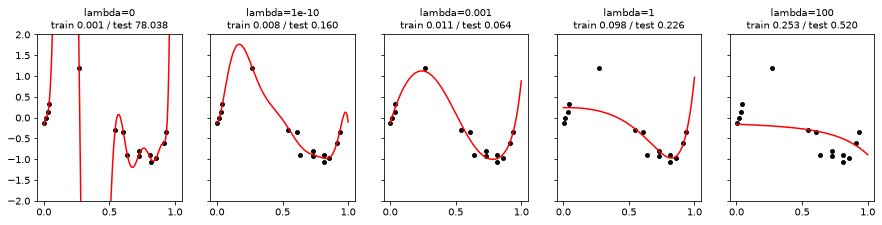

In [45]:
x_poly_2d, x_grid_2d, x_test_2d = x_poly[:, None], x_grid[:, None], x_poly_test[:, None]

fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharey=True)
for ax, alpha in zip(axes, [0.0, 1e-10, 1e-3, 1.0, 100.0]):
    # 다항식 항들은 크기가 서로 달라 표준화한 뒤 패널티를 겁니다
    ridge_poly = make_pipeline(PolynomialFeatures(12), StandardScaler(), Ridge(alpha=alpha))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # alpha=0은 행렬이 거의 특이해서 수치 경고가 납니다. 바로 그 점을 보려는 실험입니다
        ridge_poly.fit(x_poly_2d, y_poly)
    train_mse = mean_squared_error(y_poly, ridge_poly.predict(x_poly_2d))
    test_mse = mean_squared_error(y_poly_test, ridge_poly.predict(x_test_2d))
    ax.scatter(x_poly, y_poly, color="black", s=15)
    ax.plot(x_grid, ridge_poly.predict(x_grid_2d), "r")
    ax.set_ylim(-2, 2)
    ax.set_title(f"lambda={alpha:g}\ntrain {train_mse:.3f} / test {test_mse:.3f}", fontsize=10)
plt.show()

숫자를 봅시다. $\lambda=0$은 1.1의 12차 다항식과 같은 모델이고, 학습 MSE 0.001, 테스트 MSE 78.04로 심한 과적합입니다(거의 특이한 행렬을 푸는 값이라 환경에 따라 크게 다를 수 있습니다). $\lambda=10^{-10}$이라는 아주 작은 값만 줘도 테스트 MSE가 0.160으로 떨어집니다. 12차 다항식의 항들은 서로 매우 비슷해서 패널티가 없으면 계수가 크게 부풀기 때문입니다. $\lambda=0.001$이면 학습 MSE는 0.011로 **커지지만** 테스트 MSE는 0.064로 가장 좋습니다. 학습 loss를 조금 남겨 두고 일반화를 얻은 것입니다. $\lambda=1$(0.098, 0.226)을 지나 $\lambda=100$(0.253, 0.520)이 되면 언더피팅입니다. $\lambda$도 validation으로 골라야 하는 값입니다.

## 4.4 L1과 L2의 차이

아래 그림을 봅시다. 두 파라미터 $\theta_1, \theta_2$로 이루어진 모델을 학습한다고 합시다.

- 패널티가 없다면 $(\theta_1, \theta_2)$는 $\theta_{opt}$로 수렴했을 것입니다. 타원은 loss가 같은 지점을 이은 등고선입니다.
- 규제가 있으면 $(\theta_1, \theta_2)$는 각 도형 안에 머물러야 합니다(패널티를 "예산"으로 보는 시각입니다). 그래서 **등고선이 도형에 처음 닿는 점**으로 수렴합니다.
- $\lambda$가 커질수록 도형은 작아집니다. 더 강한 규제입니다.
- 쉽게 말해 $\theta_{opt}$에 완전히 박혀 버리면 Train set에 과적합되므로, 적당히 일반적인 특징만 배우도록 거리를 두는 것입니다. 약간의 bias를 받아들이고 variance를 줄이는 거래이며, 특정 파라미터만 커져서 과제에 과적합되는 상황을 막습니다.

L1 (diamond) 수렴점: [1. 0.]
L2 (circle) 수렴점: [0.986 0.169]


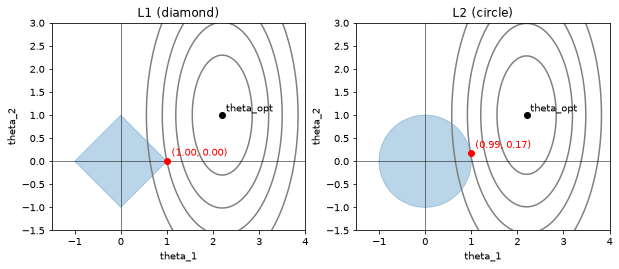

In [46]:
def constrained_optimum(boundary: np.ndarray, opt: np.ndarray, scale: np.ndarray) -> np.ndarray:
    """제약 도형의 테두리 점 중 loss가 가장 작은 점을 찾습니다."""
    losses = (((boundary - opt) * scale) ** 2).sum(axis=1)
    return boundary[np.argmin(losses)]


theta_opt = np.array([2.2, 1.0])
scale = np.array([2.0, 1.0])            # 축마다 곡률이 달라 등고선이 타원입니다
budget = 1.0
angle = np.linspace(0, 2 * np.pi, 20000)
l2_boundary = budget * np.c_[np.cos(angle), np.sin(angle)]
l1_boundary = l2_boundary / np.abs(l2_boundary).sum(axis=1, keepdims=True) * budget

t1, t2 = np.meshgrid(np.linspace(-1.5, 4, 300), np.linspace(-1.5, 3, 300))
loss_surface = ((t1 - theta_opt[0]) * scale[0]) ** 2 + ((t2 - theta_opt[1]) * scale[1]) ** 2

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, boundary, name in zip(axes, [l1_boundary, l2_boundary], ["L1 (diamond)", "L2 (circle)"]):
    point = constrained_optimum(boundary, theta_opt, scale)
    touching = (((point - theta_opt) * scale) ** 2).sum()
    ax.contour(t1, t2, loss_surface, levels=[touching * 0.25, touching * 0.6, touching, touching * 1.6], colors="gray")
    ax.fill(boundary[:, 0], boundary[:, 1], alpha=0.3, color="tab:blue")
    ax.scatter(*theta_opt, color="black", zorder=3)
    ax.annotate("theta_opt", theta_opt + 0.08)
    ax.scatter(*point, color="red", zorder=3)
    ax.annotate(f"({point[0]:.2f}, {point[1]:.2f})", point + np.array([0.1, 0.12]), color="red")
    ax.axhline(0, color="k", linewidth=0.5)
    ax.axvline(0, color="k", linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("theta_1")
    ax.set_ylabel("theta_2")
    ax.set_aspect("equal")
    print(name, "수렴점:", point.round(3))
plt.show()

**L1 규제**: 마름모는 **뾰족한 모서리가 축 위에** 있습니다. 등고선은 모서리에 먼저 닿기 쉽습니다. 그림의 수렴점처럼 어떤 파라미터가 **정확히 0**이 될 수 있다는 뜻입니다. 즉 특정 변수를 삭제하는 효과가 있어 변수 선택에 씁니다.

이것을 "택시 거리로는 최소 지점이 여러 곳 나오기 때문"이라고 설명하는 글도 있는데, 거리가 같은 경로가 여러 개인 것과 파라미터가 0이 되는 것은 다른 이야기입니다. 모서리가 이유입니다.

**L2 규제**: 원에는 모서리가 없습니다. $\theta_{opt}$가 축 위에 있지 않은 이상 파라미터가 정확히 0이 되지는 않습니다. 대신 모든 파라미터를 고르게 줄여, 특정 파라미터에 쏠리지 않게 만듭니다. 또 어디서나 미분 가능해서 gradient 기반 학습에 다루기 쉽습니다. 신경망에서는 L2(weight decay)가 훨씬 흔합니다.

"L2가 L1보다 $\theta_{opt}$에 더 정교하게 다가간다"는 설명도 조심해서 읽으세요. 위 그림처럼 **도형의 예산을 같게 놓으면** 원이 마름모를 포함하므로 L2의 loss가 항상 작거나 같습니다. 하지만 실제로는 $\lambda$로 세기를 정하므로 두 도형의 크기를 직접 비교할 수 없어, 일반적인 법칙으로 보기는 어렵습니다.

## 4.5 Elastic Net (L1 + L2)

L1과 L2의 패널티를 섞은 형태입니다. ([참고 그림](https://static.packt-cdn.com/products/9781838556334/graphics/C12624_04_60.jpg))

$$\text{Cost} = \frac{1}{n}\sum_{i=1}^{n} L(y_i, \hat{y}_i) + \lambda_1 \sum_j |w_j| + \lambda_2 \sum_j w_j^2$$

단순히 섞었을 뿐처럼 보이지만, 둘을 함께 쓰면 **변수 간 grouping effect**를 얻습니다. 상관관계가 큰 변수들에 비슷한 가중치를 주어, 중요한 변수들은 똑같이 중요하게 취급하고 중요하지 않은 변수들은 함께 버립니다. 상관관계가 커도 중요하지 않은 변수를 모두 버리면서 중요한 변수만 골라, 중요도와 상관관계에 맞는 가중치를 줄 수 있습니다.

쌍둥이처럼 거의 같은 변수 두 개를 넣어 확인해 봅시다. 세 번째 변수는 정답과 무관한 잡음입니다.

In [47]:
rng = np.random.default_rng(0)
signal = rng.normal(size=200)
X_twin = np.c_[signal + rng.normal(0, 0.01, 200), signal + rng.normal(0, 0.01, 200), rng.normal(size=200)]
y_twin = 3 * signal + rng.normal(0, 0.5, 200)

for name, model in [("Lasso (L1)", Lasso(alpha=0.1)),
                    ("Ridge (L2)", Ridge(alpha=1.0)),
                    ("ElasticNet", ElasticNet(alpha=0.1, l1_ratio=0.5))]:
    model.fit(X_twin, y_twin)
    print(f"{name:12s} 계수 {model.coef_.round(3)}")

Lasso (L1)   계수 [ 2.914  0.    -0.   ]
Ridge (L2)   계수 [ 1.531  1.482 -0.011]
ElasticNet   계수 [ 1.446  1.442 -0.   ]


Lasso는 쌍둥이 중 하나에 2.914를 몰아주고 다른 하나를 0으로 만듭니다. Ridge는 1.531과 1.482로 나눠 주지만 잡음 변수의 계수도 -0.011로 남깁니다. ElasticNet은 1.446, 1.442로 고르게 나누면서 잡음 변수는 0으로 만듭니다. 설명한 grouping effect 그대로입니다.

## 4.6 PyTorch에서 규제 쓰기

[`torch.optim.Adam`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html)의 인자 중 `weight_decay`가 L2 규제의 세기입니다(기본값 0). PyTorch의 옵티마이저에 L1 인자는 없어서 loss에 직접 더합니다.

`weight_decay`의 동작을 확인해 봅시다. gradient에 `weight_decay * w`를 더합니다. 그러므로 **패널티 식으로 쓰면 $\frac{\lambda}{2} w^2$에 해당**합니다.

Adam처럼 gradient 크기를 스스로 조절하는 옵티마이저에서는 이 방식이 순수한 가중치 감쇠와 같지 않습니다. 그래서 감쇠를 업데이트에서 따로 수행하는 `AdamW`([Loshchilov & Hutter, 2017](https://arxiv.org/abs/1711.05101))가 나왔습니다. **Adam 계열로 규제까지 걸 때의 기본 선택은 `AdamW`입니다.** Transformer 학습에서 특히 표준처럼 쓰입니다. 아래에서 CIFAR-10으로 효과를 직접 봅니다.

In [48]:
# params에는 model.parameters()를 넘깁니다. 작은 모델로 인자를 확인합니다
small_model = nn.Linear(2, 1)
optimizer = torch.optim.Adam(small_model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0)
print(optimizer)

# loss의 gradient가 0이어도 weight_decay만으로 가중치가 줄어듭니다
w = torch.tensor([2.0, -3.0], requires_grad=True)
sgd = torch.optim.SGD([w], lr=0.1, weight_decay=0.5)
(w * 0).sum().backward()
sgd.step()
print("weight_decay 한 스텝 뒤:", w.detach().numpy(), "= w - lr * 0.5 * w =", (np.array([2.0, -3.0]) * (1 - 0.1 * 0.5)))

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
weight_decay 한 스텝 뒤: [ 1.9  -2.85] = w - lr * 0.5 * w = [ 1.9  -2.85]


In [49]:
def fit_linear(l1_lambda: float = 0.0, weight_decay: float = 0.0, steps: int = 2000) -> np.ndarray:
    """특징 20개 중 3개만 정답과 관련된 회귀 문제를 학습해 가중치를 돌려줍니다."""
    set_seed()
    x = torch.randn(200, 20)
    y = 2 * x[:, 0] - 3 * x[:, 1] + 1.5 * x[:, 2] + torch.randn(200)
    linear = nn.Linear(20, 1)
    optimizer = optim.SGD(linear.parameters(), lr=0.01, weight_decay=weight_decay)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.mse_loss(linear(x).squeeze(1), y)
        # L1은 옵티마이저 인자가 없어 loss에 직접 더합니다
        loss = loss + l1_lambda * linear.weight.abs().sum()
        loss.backward()
        optimizer.step()
    return linear.weight.detach().numpy().ravel()


for name, weights in [("패널티 없음", fit_linear()),
                      ("L1 (lambda=0.3)", fit_linear(l1_lambda=0.3)),
                      ("L2 (weight_decay=0.3)", fit_linear(weight_decay=0.3))]:
    print(f"{name:22s} 앞 3개 {weights[:3].round(2)} | 절댓값 0.01 미만인 가중치 {(np.abs(weights) < 0.01).sum()}/20개")

패널티 없음                 앞 3개 [ 1.98 -3.01  1.5 ] | 절댓값 0.01 미만인 가중치 0/20개
L1 (lambda=0.3)        앞 3개 [ 1.82 -2.89  1.36] | 절댓값 0.01 미만인 가중치 17/20개
L2 (weight_decay=0.3)  앞 3개 [ 1.66 -2.54  1.31] | 절댓값 0.01 미만인 가중치 0/20개


L1은 관련 없는 17개 가중치를 0 근처로 눌렀고(앞 3개는 1.82, -2.89, 1.36), 패널티가 없을 때와 L2에서는 그런 가중치가 하나도 없습니다. L2는 큰 가중치 쪽을 비례해서 줄입니다(1.66, -2.54, 1.31).

SGD로 학습한 L1은 scikit-learn의 Lasso처럼 정확히 0을 만들지는 않고 0 근처에서 진동합니다. 위에서 "0.01 미만"으로 센 이유입니다.

이제 신경망입니다. 1.2의 과적합 모델을 `AdamW(weight_decay=0.1)`로 학습해 비교합니다. `AdamW`의 기본값은 0.01인데, 효과가 눈에 띄도록 키웠습니다.

Epoch [0] Loss: 1.4206, Accuracy: 48.12 | Test_loss: 1.1483, Test_accuracy: 59.24


Epoch [5] Loss: 0.6193, Accuracy: 78.26 | Test_loss: 0.7466, Test_accuracy: 74.29


Epoch [10] Loss: 0.4545, Accuracy: 84.11 | Test_loss: 0.7521, Test_accuracy: 74.55


Epoch [15] Loss: 0.3645, Accuracy: 87.14 | Test_loss: 0.7450, Test_accuracy: 76.14


Epoch [20] Loss: 0.3170, Accuracy: 89.02 | Test_loss: 0.8372, Test_accuracy: 74.41


Epoch [25] Loss: 0.2893, Accuracy: 89.87 | Test_loss: 0.8283, Test_accuracy: 75.13


Epoch [29] Loss: 0.2848, Accuracy: 89.98 | Test_loss: 0.7902, Test_accuracy: 75.47
Finished Training


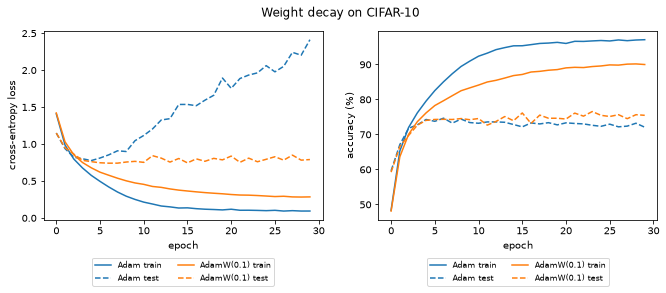

Adam: test loss 최저 0.776 (epoch 4), 마지막 2.412 | 마지막 정확도 train 97.1% / test 72.1%
AdamW(weight_decay=0.1): test loss 최저 0.741 (epoch 6), 마지막 0.790 | 마지막 정확도 train 90.0% / test 75.5%


In [50]:
set_seed()
history_wd = fit(OverfitNet().to(device), OVERFIT_EPOCHS, writer=make_writer("adamw"),
                 make_optimizer=lambda params: torch.optim.AdamW(params, weight_decay=0.1))
plot_history({"Adam": history_base, "AdamW(0.1)": history_wd}, "Weight decay on CIFAR-10")
summarize("Adam", history_base)
summarize("AdamW(weight_decay=0.1)", history_wd)

마지막 test loss가 2.412에서 0.790으로, 테스트 정확도가 72.1%에서 75.5%로 좋아졌고, 학습 정확도는 97.1%에서 90.0%로 내려갑니다. test loss는 epoch 6의 0.741 이후 조금 오르므로 과적합이 없어지지는 않았습니다. 3.8의 Dropout과 비슷한 정도의 효과입니다. 시드 하나의 결과이고, `weight_decay` 값도 검증 데이터로 골라야 합니다.

## 4.7 scikit-learn으로 규제 실습

선형 회귀로 세 가지 규제를 비교합니다.

> **데이터 고르기**: 다른 자료에서 Boston Housing을 자주 볼 수 있습니다. 이 데이터의 `B` 열은 지역의 흑인 비율 Bk를 `1000(Bk-0.63)^2`으로 변환해 주택 가격 예측에 넣도록 만들어져 윤리적 문제가 지적되었고, scikit-learn은 `load_boston`을 제공하지 않습니다. 대신 **California Housing**을 씁니다.
>
> **버전을 낮추지 마세요**: 함수 하나가 없다고 라이브러리 하나의 버전만 낮추면 다른 라이브러리와 맞지 않아 새 에러가 나기 쉽습니다. 예를 들어 `solve() got an unexpected keyword argument 'sym_pos'`는 낡은 scikit-learn이 최신 SciPy와 만났을 때 나는 에러입니다. 현재 버전에 맞는 데이터와 인자를 쓰세요.

In [51]:
np.set_printoptions(suppress=True)

# 데이터 로드
housing = fetch_california_housing()

# 데이터 프레임 만들기
df = pd.DataFrame(housing["data"], columns=housing["feature_names"])
df["MedHouseVal"] = housing["target"]
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


컬럼 소개 (feature 8 + target 1). 행 하나가 미국 캘리포니아의 인구조사 구역 하나입니다.

- MedInc: 구역의 중위 소득 (만 달러 단위)
- HouseAge: 주택 연식의 중앙값
- AveRooms: 가구당 평균 방 수
- AveBedrms: 가구당 평균 침실 수
- Population: 구역 인구
- AveOccup: 가구당 평균 거주자 수
- Latitude: 위도
- Longitude: 경도
- MedHouseVal: 주택 가격의 중앙값 (10만 달러 단위, 예측할 값)

Training set과 Test set을 나눕니다.

In [52]:
x_train, x_test, y_train, y_test = train_test_split(df.drop(columns="MedHouseVal"), df["MedHouseVal"], random_state=23)
print(x_train.shape, x_test.shape)

(15480, 8) (5160, 8)


scikit-learn의 평가지표를 활용해 예측을 그리고 비교하는 함수를 만듭니다.

> 이 함수들의 인자 순서는 `(이름, 정답, 예측)`입니다. 정답과 예측을 뒤집어 넘기는 실수가 흔합니다. MSE는 같게 나오지만 그래프가 틀립니다. 점 5000여 개를 다 찍으면 뭉개지므로 300개만 찍습니다.

In [53]:
mse_table: dict[str, float] = {}


def plot_pred_vs_actual(name_: str, actual: pd.Series, pred: np.ndarray) -> None:
    """정답 순서로 정렬해 예측과 정답을 겹쳐 그립니다."""
    frame = pd.DataFrame({"actual": np.asarray(actual), "prediction": pred})
    frame = frame.sample(300, random_state=0).sort_values(by="actual").reset_index(drop=True)
    plt.figure(figsize=(8, 3))
    plt.scatter(frame.index, frame["prediction"], marker="x", color="r", s=15)
    plt.scatter(frame.index, frame["actual"], alpha=0.7, marker="o", color="black", s=15)
    plt.title(name_)
    plt.legend(["prediction", "actual"])
    plt.show()


def report_regression(name_: str, actual: pd.Series, pred: np.ndarray) -> None:
    """MSE를 기록하고 지금까지의 모델을 막대그래프로 비교합니다."""
    plot_pred_vs_actual(name_, actual, pred)
    mse_table[name_] = mean_squared_error(actual, pred)
    table = pd.DataFrame(sorted(mse_table.items(), key=lambda x: x[1], reverse=True), columns=["model", "mse"])
    print(table.to_string())
    plt.figure(figsize=(8, 0.5 * len(table) + 0.8))
    ax = plt.subplot()
    ax.barh(np.arange(len(table)), table["mse"])
    ax.set_yticks(np.arange(len(table)))
    ax.set_yticklabels(table["model"])
    for i, value in enumerate(table["mse"]):
        ax.text(value, i, f" {value:.3f}", va="center")
    ax.set_xlim(0, table["mse"].max() * 1.2)
    plt.title("MSE Error")
    plt.show()


def drop_result(name_: str) -> bool:
    """표에서 모델 하나를 지웁니다."""
    return mse_table.pop(name_, None) is not None


def plot_coefficients(columns: pd.Index, coef: np.ndarray) -> None:
    """계수를 크기순으로 그립니다."""
    coef_df = pd.DataFrame({"feature": columns, "coef": coef}).sort_values("coef", ascending=False).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.barh(np.arange(len(coef_df)), coef_df["coef"])
    ax.set_yticks(np.arange(len(coef_df)))
    ax.set_yticklabels(coef_df["feature"])
    fig.tight_layout()
    plt.show()

**L1 규제 (Lasso)**

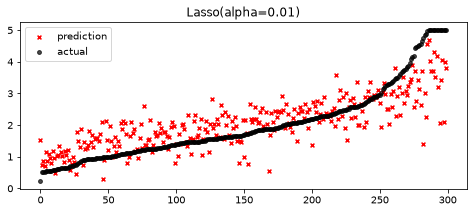

               model       mse
0  Lasso(alpha=0.01)  0.527876


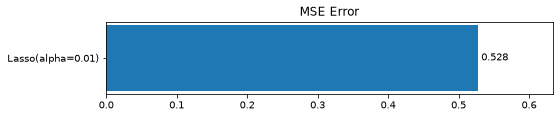

In [54]:
lasso = Lasso(alpha=0.01)
lasso.fit(x_train, y_train)
lasso_pred = lasso.predict(x_test)
report_regression("Lasso(alpha=0.01)", y_test, lasso_pred)

**L2 규제 (Ridge)**

`alpha`가 패널티의 세기입니다.

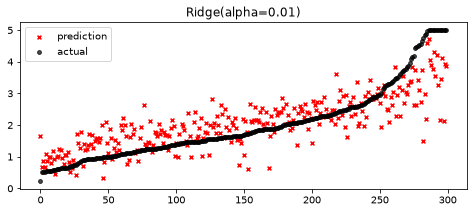

               model       mse
0  Lasso(alpha=0.01)  0.527876
1  Ridge(alpha=0.01)  0.519814


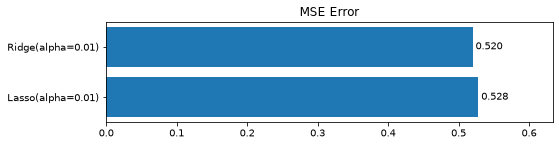

In [55]:
ridge = Ridge(alpha=0.01)
ridge.fit(x_train, y_train)
ridge_pred = ridge.predict(x_test)
report_regression("Ridge(alpha=0.01)", y_test, ridge_pred)

**L1 + L2 (Elastic Net)**

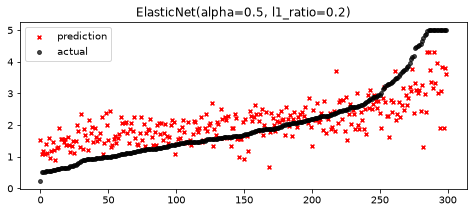

                                 model       mse
0  ElasticNet(alpha=0.5, l1_ratio=0.2)  0.631594
1                    Lasso(alpha=0.01)  0.527876
2                    Ridge(alpha=0.01)  0.519814


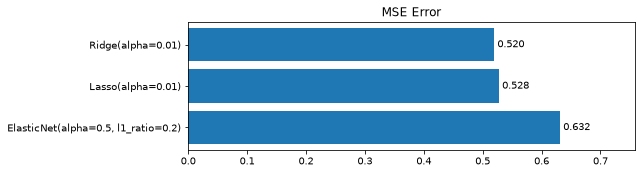

In [56]:
elasticnet = ElasticNet(alpha=0.5, l1_ratio=0.2)
elasticnet.fit(x_train, y_train)
elas_pred = elasticnet.predict(x_test)
report_regression("ElasticNet(alpha=0.5, l1_ratio=0.2)", y_test, elas_pred)

여러 모델의 MSE를 한 표에 정리해 봅시다. (비슷한 정리: [참고 그림](https://hyemin-kim.github.io/images/S-Python-sklearn4/output_226_2-1596543997347.png)) 패널티가 없는 선형 회귀를 기준으로 두고, 변수 크기를 맞춘 뒤 패널티를 거는 경우와, 다항식으로 일부러 복잡하게 만든 모델까지 넣습니다.

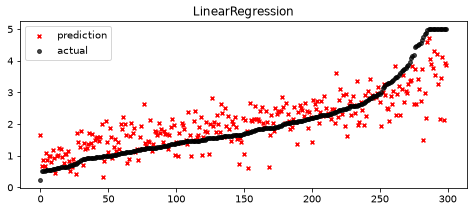

                                        model       mse
0  Scaled ElasticNet(alpha=0.5, l1_ratio=0.2)  0.763502
1         ElasticNet(alpha=0.5, l1_ratio=0.2)  0.631594
2                           Lasso(alpha=0.01)  0.527876
3                    Scaled Lasso(alpha=0.01)  0.521560
4                           Ridge(alpha=0.01)  0.519814
5                    Scaled Ridge(alpha=0.01)  0.519814
6                            LinearRegression  0.519814


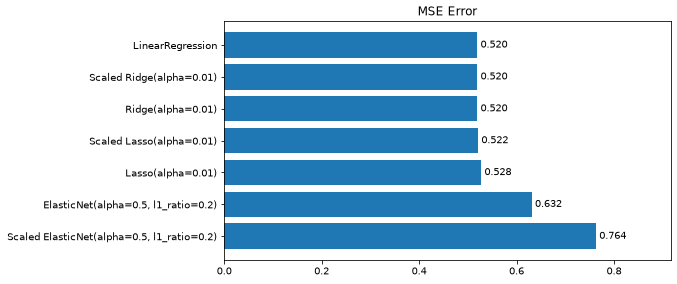

        Poly3 model  train MSE     test MSE  test MAE
0  LinearRegression      0.346  7699762.880    44.829
1    Ridge(alpha=1)      0.386        4.842     0.492
2  Ridge(alpha=100)      0.427        1.616     0.494


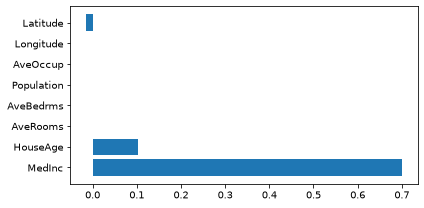

Lasso(alpha=0.1)가 0으로 만든 변수: ['AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Longitude']


In [57]:
def eval_silently(name_: str, model: BaseEstimator) -> np.ndarray:
    """모델을 학습하고 MSE만 표에 기록합니다."""
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    mse_table[name_] = mean_squared_error(y_test, pred)
    return pred


# 패널티는 계수 크기에 걸리므로 변수의 크기를 맞춰야 공평합니다
eval_silently("Scaled Lasso(alpha=0.01)", make_pipeline(StandardScaler(), Lasso(alpha=0.01)))
eval_silently("Scaled Ridge(alpha=0.01)", make_pipeline(StandardScaler(), Ridge(alpha=0.01)))
eval_silently("Scaled ElasticNet(alpha=0.5, l1_ratio=0.2)", make_pipeline(StandardScaler(), ElasticNet(alpha=0.5, l1_ratio=0.2)))
report_regression("LinearRegression", y_test, eval_silently("LinearRegression", LinearRegression()))

# 3차 다항식으로 일부러 복잡하게 만들면 패널티의 효과가 잘 드러납니다. 값의 차이가 너무 커서 표로 봅니다
poly_rows = []
for name_, last_step in [("LinearRegression", LinearRegression()), ("Ridge(alpha=1)", Ridge(alpha=1)), ("Ridge(alpha=100)", Ridge(alpha=100))]:
    poly_model = make_pipeline(PolynomialFeatures(3), StandardScaler(), last_step).fit(x_train, y_train)
    poly_pred = poly_model.predict(x_test)
    poly_rows.append({"Poly3 model": name_, "train MSE": mean_squared_error(y_train, poly_model.predict(x_train)),
                      "test MSE": mean_squared_error(y_test, poly_pred), "test MAE": mean_absolute_error(y_test, poly_pred)})
print(pd.DataFrame(poly_rows).round(3).to_string())

# 계수도 봅니다. Lasso가 어떤 변수를 없앴는지 확인합니다
scaled_lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.1)).fit(x_train, y_train)
plot_coefficients(x_train.columns, scaled_lasso[-1].coef_)
print("Lasso(alpha=0.1)가 0으로 만든 변수:", list(x_train.columns[scaled_lasso[-1].coef_ == 0]))

결과에서 배울 점이 세 가지 있습니다.

1. **과적합이 없으면 규제는 할 일이 없습니다.** 변수 8개인 선형 회귀는 복잡도가 낮아서, 패널티 없는 `LinearRegression`(0.520)이 가장 좋습니다. `Ridge(alpha=0.01)`는 거의 같고, `Lasso`는 0.528, `ElasticNet(alpha=0.5)`는 패널티가 과해 0.632입니다.
2. **변수의 크기를 맞추면 패널티의 뜻이 달라집니다.** Lasso는 0.528에서 0.522로 나아졌습니다. 같은 `alpha=0.5`의 ElasticNet은 0.764로 오히려 나빠졌는데, 표준화하면 모든 변수에 패널티가 똑같이 걸려 이 `alpha`가 너무 강해지기 때문입니다. `alpha`는 스케일과 함께 골라야 합니다.
3. **복잡한 모델에서는 효과가 극적입니다.** 3차 다항식 선형 회귀는 학습 MSE가 0.346으로 가장 작지만 테스트 MSE는 약 770만입니다. 학습 데이터에 없던 극단적인 값에서 3제곱 항이 폭주한 것입니다. Ridge를 걸면 1.6~4.8로 내려옵니다. 그래도 단순한 선형 회귀(0.520)에는 못 미칩니다. 규제가 만능은 아니고, MAE는 0.49로 평범한 것을 보면 소수의 큰 오차가 MSE를 끌어올리고 있습니다.

`Lasso(alpha=0.1)`는 변수 8개 중 5개를 정확히 0으로 만들어, 중위 소득(`MedInc`)과 주택 연식, 위도만 남겼습니다. L1의 변수 선택을 실제 데이터에서 본 것입니다.

## 4.8 여담: Multi Task Learning (MTL)

여러 과제를 함께 학습하는 것도 규제 효과를 냅니다. 아래 그림은 MTL 방법 중 하나인 **Soft Parameter Sharing**입니다. 과제마다 자기 네트워크와 파라미터를 갖되, 네트워크끼리 파라미터 사이의 거리가 너무 벌어지지 않도록 벌점을 줍니다. ([참고 그림](https://www.ruder.io/content/images/2017/05/mtl_images-002-1.png))

```
Task A 출력   Task B 출력   Task C 출력
    │             │             │
 [ 층 A4 ]     [ 층 B4 ]     [ 층 C4 ]     과제 전용 층 (제약 없음)
    │             │             │
 [ 층 A3 ]┄┄┄┄[ 층 B3 ]┄┄┄┄[ 층 C3 ]     ┄┄ : 파라미터가 비슷해지도록 하는 제약
    │             │             │            (예: λ‖θ_A − θ_B‖² 를 loss에 더함)
 [ 층 A2 ]┄┄┄┄[ 층 B2 ]┄┄┄┄[ 층 C2 ]
    │             │             │
 [ 층 A1 ]┄┄┄┄[ 층 B1 ]┄┄┄┄[ 층 C1 ]
```

Multi Task Learning의 장점은 다음과 같습니다.

**Implicit Data Augmentation.** Task A와 Task B의 데이터셋은 서로 다른 noise를 갖습니다. Task A로만 학습하면 A의 noise까지 배워 과적합될 수 있습니다. Task B를 함께 학습하면 공유 네트워크가 더 일반적인 표현을 배웁니다.

**더 다양한 feature를 학습할 수 있습니다.** Task A에서 잘 배우는 어떤 특징 G가 Task B만으로는 배우기 어려울 수 있습니다. 예를 들어 object detection에서는 위치 관련 특징이 잘 학습되고, classification에서는 색 관련 특징이 잘 학습될 것입니다. 두 과제를 공유 네트워크에 통과시키면 위치와 색 특징을 함께 배울 수 있습니다.

**각각의 task가 규제 역할을 합니다.** 위 그림처럼 서로의 파라미터 사이의 거리가 일정 값을 넘지 않도록 비슷하게 유지하면 규제처럼 작용해 과적합을 막습니다.

출처: Ruder, Sebastian. "An overview of multi-task learning in deep neural networks." [arXiv:1706.05098](https://arxiv.org/abs/1706.05098) (2017). 4.1~4.5절이 MTL의 장점을 소개합니다.

## 4.9 Early Stopping

말 그대로 **과적합이 일어나기 전에 학습을 멈추는 것**입니다. 1.2의 그래프에서 test loss가 다시 오르기 시작하는 지점이 멈출 자리입니다.

언제 멈출까요? "validation error가 train error보다 커지는 지점"이라고 생각하기 쉽지만 틀린 기준입니다. validation error는 보통 학습 초반부터 train error보다 큽니다. 올바른 기준은 **validation error가 더 이상 줄지 않는 지점**입니다. 잠깐 튀는 것에 속지 않도록 `patience`만큼 기다려 보고, 그동안 나아지지 않으면 멈춥니다.

먼저 간단한 버전을 봅시다. 직접 구현할 때 흔히 넣는 버그 두 가지를 담은 `BuggyEarlyStopping`과 고친 버전을 나란히 두고, 가짜 loss로 시험해 봅니다.

In [58]:
class BuggyEarlyStopping:
    """흔한 버그 두 가지가 든 버전입니다. 비교를 위해 둡니다."""

    def __init__(self, patience: int = 5, delta: float = 0):
        self.patience = patience
        self.delta = delta
        self.counter = 1            # 버그 1: 첫 개선 전에는 1부터 세고, 개선 뒤에는 0부터 셉니다
        self.best_score = None
        self.early_stop = False

    def __call__(self, val_loss: float) -> None:
        if self.best_score is None:
            self.best_score = val_loss
        elif val_loss > self.best_score + self.delta:
            self.counter += 1
            if self.counter > self.patience:
                self.early_stop = True
        else:
            # 버그 2: delta 범위 안에서 "나빠진" 값도 개선으로 치고 최고 기록을 덮어씁니다
            self.best_score = val_loss
            self.counter = 0


class SimpleEarlyStopping:
    """val_loss가 best보다 delta 넘게 나아져야 개선으로 칩니다. 개선 없이 patience번째가 되면 멈춥니다."""

    def __init__(self, patience: int = 5, delta: float = 0):
        self.patience = patience
        self.delta = delta
        self.counter = 0
        self.best_score = None
        self.early_stop = False

    def __call__(self, val_loss: float) -> None:
        if self.best_score is None or val_loss < self.best_score - self.delta:
            self.best_score = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True


def stop_epoch(stopper: BuggyEarlyStopping | SimpleEarlyStopping, losses: list[float]) -> int | None:
    """몇 번째 값에서 멈추는지 돌려줍니다. 안 멈추면 None입니다."""
    for i, loss in enumerate(losses):
        stopper(loss)
        if stopper.early_stop:
            return i
    return None


# 시험 1: 처음부터 나빠지기만 할 때와, 한 번 개선된 뒤 나빠질 때 인내심이 같아야 합니다
from_start = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5]
after_best = [1.0, 0.9, 1.1, 1.2, 1.3, 1.4, 1.5]
print("버그판 patience=3 | 바로 악화:", stop_epoch(BuggyEarlyStopping(3), from_start), "/ 개선 뒤 악화:", stop_epoch(BuggyEarlyStopping(3), after_best))
print("수정 patience=3 | 바로 악화:", stop_epoch(SimpleEarlyStopping(3), from_start), "/ 개선 뒤 악화:", stop_epoch(SimpleEarlyStopping(3), after_best))

# 시험 2: loss가 조금씩 나빠지는데 delta 안쪽이면 버그판은 영원히 멈추지 않습니다
slowly_worse = [1.0 + 0.01 * i for i in range(30)]
print("버그판 delta=0.05 | 서서히 악화:", stop_epoch(BuggyEarlyStopping(3, delta=0.05), slowly_worse))
print("수정 delta=0.05 | 서서히 악화:", stop_epoch(SimpleEarlyStopping(3, delta=0.05), slowly_worse))

버그판 patience=3 | 바로 악화: 3 / 개선 뒤 악화: 5
수정 patience=3 | 바로 악화: 3 / 개선 뒤 악화: 4
버그판 delta=0.05 | 서서히 악화: None
수정 delta=0.05 | 서서히 악화: 3


이제 CNN을 학습합니다. 네트워크, 데이터로더, 인스턴스 선언, 학습 반복문을 차례로 만듭니다. `random_split`으로 학습 데이터의 20%를 떼어 validation set으로 씁니다. **test set으로 멈출 시점을 정하면 test set이 시험지가 아니게 됩니다.**

> 모델과 데이터를 `device`로 옮기는 것을 잊으면 CPU에서 돌아 epoch마다 몇 분씩 걸리기도 합니다. 학습이 이상하게 느리면 먼저 확인하세요.

In [59]:
class CNN(nn.Module):
    """간단한 합성곱 신경망입니다. 28 → 24 → 12 → 8 → 4 순으로 크기가 줄어 64*4*4=1024가 됩니다."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5)
        self.fc1 = nn.Linear(1024, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.relu(self.conv1(x))
        x = torch.max_pool2d(x, 2)
        x = torch.relu(self.conv2(x))
        x = torch.max_pool2d(x, 2)
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        return self.fc2(x)


# 데이터 변환을 정의하고 MNIST를 불러옵니다
es_transform = v2.Compose([to_tensor, v2.Normalize((0.5,), (0.5,))])
mnist_dataset = datasets.MNIST(root="./data", train=True, transform=es_transform, download=True)
train_size = int(0.8 * len(mnist_dataset))
val_size = len(mnist_dataset) - train_size
set_seed()
es_train_dataset, es_val_dataset = random_split(mnist_dataset, [train_size, val_size])
es_train_loader = DataLoader(es_train_dataset, batch_size=64, shuffle=True)
es_val_loader = DataLoader(es_val_dataset, batch_size=64)

# 모델, 옵티마이저, Early stopping 객체를 만듭니다
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
early_stopping = SimpleEarlyStopping(patience=3)

# Early stopping이 있으면 100을 다 돌지 않습니다
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for images, labels in es_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in es_val_loader:
            images, labels = images.to(device), labels.to(device)
            val_loss += criterion(model(images), labels).item()
    avg_val_loss = val_loss / len(es_val_loader)

    print(f"Epoch [{epoch + 1}/{num_epochs}] Train Loss: {train_loss / len(es_train_loader):.4f} Validation Loss: {avg_val_loss:.4f}")

    early_stopping(avg_val_loss)
    if early_stopping.early_stop:
        print("Early stopping")
        break

Epoch [1/100] Train Loss: 0.1597 Validation Loss: 0.0687


Epoch [2/100] Train Loss: 0.0479 Validation Loss: 0.0660


Epoch [3/100] Train Loss: 0.0341 Validation Loss: 0.0409


Epoch [4/100] Train Loss: 0.0265 Validation Loss: 0.0402


Epoch [5/100] Train Loss: 0.0190 Validation Loss: 0.0473


Epoch [6/100] Train Loss: 0.0154 Validation Loss: 0.0423


... (4 outputs left out)

Epoch [11/100] Train Loss: 0.0110 Validation Loss: 0.0384


Epoch [12/100] Train Loss: 0.0078 Validation Loss: 0.0437


Epoch [13/100] Train Loss: 0.0041 Validation Loss: 0.0585


Epoch [14/100] Train Loss: 0.0084 Validation Loss: 0.0578
Early stopping


이 단순한 버전에는 부족한 점이 있습니다. 멈춘 순간의 모델은 이미 `patience`만큼 나빠진 뒤의 모델입니다. 우리가 원하는 것은 **validation loss가 가장 좋았던 순간의 모델**입니다. 그래서 개선될 때마다 저장해 두고 끝나면 되돌리는 버전을 씁니다. 이어지는 코드는 [Udacity의 MNIST 예제](https://github.com/udacity/deep-learning-v2-pytorch/blob/master/convolutional-neural-networks/mnist-mlp/mnist_mlp_solution_with_validation.ipynb)에 [Early stopping 코드](https://github.com/Bjarten/early-stopping-pytorch)(MIT 라이선스)를 맞춘 것입니다.

먼저 데이터입니다. 학습 데이터의 인덱스를 섞어 20%를 validation용으로 떼고, `SubsetRandomSampler`로 뽑습니다. 앞의 `random_split`과 목적이 같은 다른 방법입니다.

In [60]:
def create_datasets(batch_size: int) -> tuple[DataLoader, DataLoader, DataLoader]:
    """MNIST의 학습, 테스트, 검증 데이터로더를 만듭니다."""
    valid_size = 0.2     # 학습 데이터 중 검증에 쓸 비율
    transform = to_tensor
    train_data = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
    test_data = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

    # 인덱스를 섞어 검증용을 떼어 냅니다
    num_train = len(train_data)
    indices = list(range(num_train))
    np.random.shuffle(indices)
    split = int(np.floor(valid_size * num_train))
    train_idx, valid_idx = indices[split:], indices[:split]

    train_loader = DataLoader(train_data, batch_size=batch_size, sampler=SubsetRandomSampler(train_idx), num_workers=0)
    valid_loader = DataLoader(train_data, batch_size=batch_size, sampler=SubsetRandomSampler(valid_idx), num_workers=0)
    test_loader = DataLoader(test_data, batch_size=batch_size, num_workers=0)
    return train_loader, test_loader, valid_loader


class DropoutMLP(nn.Module):
    """Dropout 0.5를 넣은 완전연결 신경망입니다."""

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(-1, 28 * 28)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        return self.fc3(x)


set_seed()
model = DropoutMLP().to(device)
print(model)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

DropoutMLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


In [61]:
class EarlyStopping:
    """val_loss가 patience 동안 나아지지 않으면 멈추고, 가장 좋았던 모델을 파일로 남깁니다."""

    def __init__(self, patience: int = 7, verbose: bool = False, delta: float = 0, path: str = "checkpoint.pt", trace_func: Callable[[str], None] = print):
        """
        Args:
            patience: 마지막 개선 뒤 몇 번까지 기다릴지. 기본값 7
            verbose: True면 개선될 때마다 메시지를 출력합니다
            delta: 이만큼 넘게 줄어야 개선으로 칩니다. 기본값 0
            path: 체크포인트를 저장할 경로
            trace_func: 메시지를 출력할 함수
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.delta = delta
        self.path = path
        self.trace_func = trace_func

    def __call__(self, val_loss: float, model: nn.Module) -> None:
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                self.trace_func(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss: float, model: nn.Module) -> None:
        """validation loss가 줄면 모델을 저장합니다."""
        if self.verbose:
            self.trace_func(f"Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model ...")
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

Early stopping을 넣어 모델을 학습합니다.

> validation 반복문에는 `torch.no_grad()`를 씁니다. 없으면 필요 없는 계산 그래프를 만들어 메모리를 낭비합니다. 데이터로더, 옵티마이저, 손실 함수는 전역 변수에 기대지 않고 인자로 받습니다.

In [62]:
def train_model(model: nn.Module, train_loader: DataLoader, valid_loader: DataLoader, optimizer: optim.Optimizer,
                criterion: nn.Module, patience: int, n_epochs: int) -> tuple[nn.Module, list[float], list[float]]:
    """Early stopping으로 학습하고 가장 좋았던 가중치를 복원해 돌려줍니다."""
    avg_train_losses, avg_valid_losses = [], []
    early_stopping = EarlyStopping(patience=patience)

    for epoch in range(1, n_epochs + 1):
        model.train()
        train_losses = []
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            loss = criterion(model(data), target)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        valid_losses = []
        with torch.no_grad():
            for data, target in valid_loader:
                data, target = data.to(device), target.to(device)
                valid_losses.append(criterion(model(data), target).item())

        train_loss = np.average(train_losses)
        valid_loss = np.average(valid_losses)
        avg_train_losses.append(train_loss)
        avg_valid_losses.append(valid_loss)
        if epoch % 10 == 0:   # 로그가 길어지지 않게 10 epoch마다 출력합니다
            print(f"[{epoch:>3}/{n_epochs}] train_loss: {train_loss:.5f} valid_loss: {valid_loss:.5f}")

        # 개선되면 체크포인트를 저장하고, 아니면 카운터를 올립니다
        early_stopping(valid_loss, model)
        if early_stopping.early_stop:
            print(f"Early stopping at epoch {epoch}")
            break

    # 마지막 모델이 아니라 가장 좋았던 체크포인트로 되돌립니다
    model.load_state_dict(torch.load("checkpoint.pt"))
    return model, avg_train_losses, avg_valid_losses


batch_size_es = 256
n_epochs = 100
train_loader_es, test_loader_es, valid_loader_es = create_datasets(batch_size_es)
patience = 20     # 마지막 개선 뒤 몇 epoch을 기다릴지
model, train_loss, valid_loss = train_model(model, train_loader_es, valid_loader_es, optimizer, criterion, patience, n_epochs)

[ 10/100] train_loss: 0.17027 valid_loss: 0.11642


[ 20/100] train_loss: 0.12078 valid_loss: 0.09773


[ 30/100] train_loss: 0.10127 valid_loss: 0.09430


[ 40/100] train_loss: 0.09121 valid_loss: 0.09356


[ 50/100] train_loss: 0.08237 valid_loss: 0.09602


Early stopping at epoch 58


**Loss와 Early Stopping 체크포인트 시각화.** 빨간 점선이 validation loss가 가장 낮았던 지점이고, 복원된 모델이 바로 이 순간의 모델입니다.

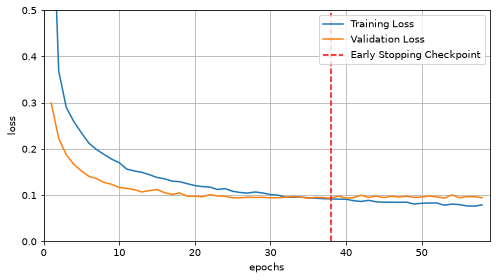

체크포인트 epoch: 38 / 학습한 epoch: 58


In [63]:
fig = plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_loss) + 1), train_loss, label="Training Loss")
plt.plot(range(1, len(valid_loss) + 1), valid_loss, label="Validation Loss")

# 검증 loss가 가장 낮은 위치를 찾습니다
minposs = int(np.argmin(valid_loss)) + 1
plt.axvline(minposs, linestyle="--", color="r", label="Early Stopping Checkpoint")

plt.xlabel("epochs")
plt.ylabel("loss")
plt.ylim(0, 0.5)
plt.xlim(0, len(train_loss) + 1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
print("체크포인트 epoch:", minposs, "/ 학습한 epoch:", len(train_loss))

validation loss는 epoch 20 무렵부터 0.10 근처에서 거의 내려가지 않습니다. 체크포인트는 epoch 38이고, 그 뒤 20 epoch을 기다렸다가 58에서 멈췄습니다. 100을 다 돌지 않아도 됐습니다. 초반에 학습 loss가 validation loss보다 높은 것은 이상한 일이 아닙니다. 학습 loss는 Dropout을 켜고, 그것도 epoch 동안 평균을 낸 값이기 때문입니다. 앞의 단순 CNN에서도 마찬가지로, epoch 14에 멈췄지만 가장 좋은 validation loss는 epoch 11의 0.0384였습니다. 그래서 체크포인트가 필요합니다.

학습된 네트워크를 테스트합니다.

> **흔한 실수**: 크기가 `batch_size`보다 작은 마지막 배치를 건너뛰면서(`break`) loss를 전체 개수로 나누면, loss를 실제보다 작게 계산하고 테스트 데이터 일부를 빼고 정확도를 재게 됩니다. 전체를 평가하세요.

In [64]:
test_loss = 0.0
class_correct = [0.0] * 10
class_total = [0.0] * 10

model.eval()
with torch.no_grad():
    for data, target in test_loader_es:
        data, target = data.to(device), target.to(device)
        output = model(data)
        test_loss += criterion(output, target).item() * data.size(0)
        _, pred = torch.max(output, 1)
        correct = pred.eq(target)
        # 클래스별로 맞힌 개수를 셉니다
        for label, is_correct in zip(target, correct):
            class_correct[label.item()] += is_correct.item()
            class_total[label.item()] += 1

test_loss = test_loss / len(test_loader_es.dataset)
print(f"Test Loss: {test_loss:.6f}\n")
for i in range(10):
    print(f"Test Accuracy of {i:5d}: {100 * class_correct[i] / class_total[i]:.0f}% ({int(class_correct[i])}/{int(class_total[i])})")
print(f"\nTest Accuracy (Overall): {100 * sum(class_correct) / sum(class_total):.2f}% ({int(sum(class_correct))}/{int(sum(class_total))})")

Test Loss: 0.087086

Test Accuracy of     0: 99% (972/980)
Test Accuracy of     1: 98% (1116/1135)
Test Accuracy of     2: 98% (1013/1032)
Test Accuracy of     3: 98% (990/1010)
Test Accuracy of     4: 97% (957/982)
Test Accuracy of     5: 97% (861/892)
Test Accuracy of     6: 98% (938/958)
Test Accuracy of     7: 97% (1001/1028)
Test Accuracy of     8: 96% (938/974)
Test Accuracy of     9: 97% (976/1009)

Test Accuracy (Overall): 97.62% (9762/10000)


테스트 결과를 그림으로 봅니다. 제목은 `예측 (정답)`이고, 맞으면 초록색, 틀리면 빨간색입니다.

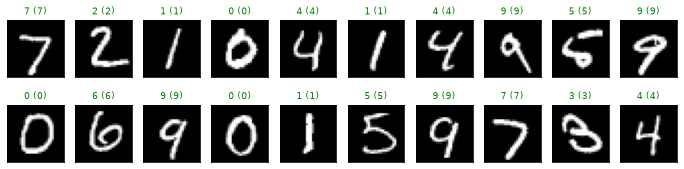

In [65]:
images, labels = next(iter(test_loader_es))
with torch.no_grad():
    output = model(images.to(device))
_, preds = torch.max(output.cpu(), 1)   # GPU에 있는 결과는 numpy나 그림으로 쓰기 전에 CPU로 옮깁니다

fig = plt.figure(figsize=(12, 2.8))
for idx in np.arange(20):
    ax = fig.add_subplot(2, 10, idx + 1, xticks=[], yticks=[])
    ax.imshow(images[idx].squeeze().numpy(), cmap="gray")
    ax.set_title(f"{preds[idx].item()} ({labels[idx].item()})",
                 color="green" if preds[idx] == labels[idx] else "red", fontsize=9)
plt.show()

## 4.10 Gradient vanishing

신경망을 깊게 쌓기 시작했을 때 문제가 드러났습니다. 역전파에서 **입력 쪽으로 올수록 gradient가 점점 작아져** 앞쪽 층이 학습되지 않는 것입니다. ([참고 그림](https://blog.kakaocdn.net/dn/okTU1/btrCH4Fx7Ro/m5f9UkRkl7CP3dUEgXTtk1/img.png))

연쇄 법칙은 층마다의 미분값을 곱합니다. 원인으로 먼저 지목된 것은 **sigmoid**입니다. 미분값이 최대 0.25이고, 입력이 조금만 커져도 0에 가깝습니다. 0.25보다 작은 수를 층 수만큼 곱하면 금방 0이 됩니다.

**tanh가 등장했습니다.** 미분의 최댓값이 1로 커졌지만 양 끝이 평평한 것은 똑같습니다. 스케일만 조금 커졌을 뿐 같은 문제가 생깁니다. 근본적인 해결책이 필요했습니다.

**ReLU가 등장했습니다.** 양수 구간의 미분값이 항상 1이라 곱해도 줄지 않습니다. 이것으로 층을 깊이 쌓을 길이 열렸습니다. 다음 그림은 세 활성화 함수([sigmoid](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FyJnMy%2FbtrCKh4ojvw%2FLtlaMwrtEZHC3KtGNWvuLK%2Fimg.png) · [tanh](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcq4ZGq%2FbtrCJJNA2bI%2FZhOpBc6Rj3061ZMw11AfPK%2Fimg.png) · [ReLU](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcf41pg%2FbtrCKjuuLjU%2FqtdsmkQ2xB7xf5MuKYtaUK%2Fimg.png))를 직접 그린 것입니다.

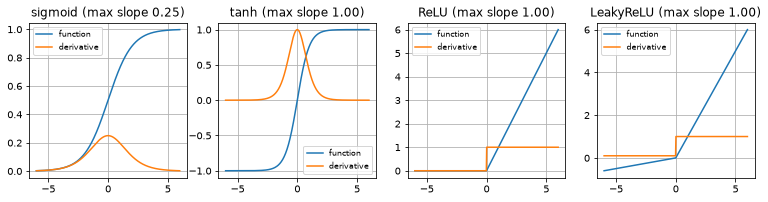

In [66]:
z = torch.linspace(-6, 6, 400, requires_grad=True)
functions = [("sigmoid", torch.sigmoid), ("tanh", torch.tanh), ("ReLU", torch.relu), ("LeakyReLU", lambda v: F.leaky_relu(v, 0.1))]

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, (name, fn) in zip(axes, functions):
    y = fn(z)
    grad, = torch.autograd.grad(y.sum(), z)
    ax.plot(z.detach(), y.detach(), label="function")
    ax.plot(z.detach(), grad, label="derivative")
    ax.set_title(f"{name} (max slope {grad.max():.2f})")
    ax.grid(True)
    ax.legend(fontsize=8)
plt.show()

그림만으로 끝내지 말고 재 봅시다. 10층짜리 MLP에 MNIST 한 배치를 넣고, **층별 gradient의 크기**를 활성화 함수별로 비교합니다. 그래프의 왼쪽이 입력 쪽, 오른쪽이 출력 쪽이고 y축은 로그 스케일입니다.

Sigmoid    입력 쪽 3.09e-08 / 출력 쪽 6.09e-01 / 비율 5.1e-08
Tanh       입력 쪽 7.12e-03 / 출력 쪽 5.56e-02 / 비율 1.3e-01


ReLU       입력 쪽 2.81e-04 / 출력 쪽 3.75e-02 / 비율 7.5e-03
LeakyReLU  입력 쪽 2.79e-04 / 출력 쪽 3.75e-02 / 비율 7.4e-03


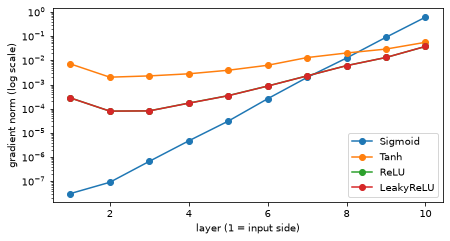

In [67]:
def layer_grad_norms(activation: type[nn.Module], depth: int = 10) -> list[float]:
    """초기 상태의 MLP에서 층별 가중치 gradient의 norm을 잽니다."""
    set_seed()
    layers: list[nn.Module] = [nn.Flatten(), nn.Linear(28 * 28, 64), activation()]
    for _ in range(depth - 2):
        layers += [nn.Linear(64, 64), activation()]
    layers.append(nn.Linear(64, 10))
    net_probe = nn.Sequential(*layers)
    x, y = next(iter(DataLoader(plain_test_dataset, batch_size=256, shuffle=True)))
    F.cross_entropy(net_probe(x), y).backward()
    return [m.weight.grad.norm().item() for m in net_probe if isinstance(m, nn.Linear)]


plt.figure(figsize=(7, 3.5))
for activation in [nn.Sigmoid, nn.Tanh, nn.ReLU, nn.LeakyReLU]:
    norms = layer_grad_norms(activation)
    plt.semilogy(range(1, len(norms) + 1), norms, "o-", label=activation.__name__)
    print(f"{activation.__name__:10s} 입력 쪽 {norms[0]:.2e} / 출력 쪽 {norms[-1]:.2e} / 비율 {norms[0] / norms[-1]:.1e}")
plt.xlabel("layer (1 = input side)")
plt.ylabel("gradient norm (log scale)")
plt.legend()
plt.show()

sigmoid는 입력 쪽 gradient가 출력 쪽의 **약 2천만분의 1**(비율 $5.1\times10^{-8}$)입니다. 앞쪽 층은 사실상 학습되지 않습니다. 소실이 정말로 일어납니다.

나머지 결과는 위 이야기보다 조금 복잡합니다.

- **tanh**(비율 0.13)는 이 초기 상태에서 ReLU(비율 $7.5\times10^{-3}$)보다 오히려 덜 줄어듭니다. 입력이 0 근처면 tanh의 기울기는 거의 1이기 때문입니다. tanh의 문제는 학습이 진행되어 값이 양 끝으로 밀려났을 때 생깁니다. 위 그래프는 학습 전 상태만 재었다는 점에 주의하세요.
- **ReLU**도 100배 넘게 줄어듭니다. 활성화 함수만이 아니라 초기화도 관여합니다. 같은 구조에 2강의 He 초기화를 적용해 이 노트북 밖에서 따로 재 보니 비율이 2~4 정도(초기화와 배치에 따라 다름)로, 소실이 사라졌습니다. 숙제 8에서 직접 확인해 보세요.

깊은 신경망을 가능하게 한 것은 ReLU 하나가 아니라 **ReLU, 알맞은 초기화, BatchNorm 같은 정규화 층의 조합**입니다.

**Tip: LeakyReLU도 좋습니다.** ReLU에는 **dying ReLU** 문제가 있습니다. 입력이 음수면 출력도 미분도 0이라, 어떤 뉴런의 입력이 항상 음수가 되어 버리면 gradient가 영영 0이고 다시 살아나지 못합니다. ([설명 글](https://towardsdatascience.com/the-dying-relu-problem-clearly-explained-42d0c54e0d24)) 해결책으로 음수 쪽에 작은 기울기를 남긴 LeakyReLU와 [ELU](https://pytorch.org/docs/stable/generated/torch.nn.ELU.html)를 참고하세요. 일부러 뉴런을 죽여 봅시다.

In [68]:
for name, act in [("ReLU", nn.ReLU()), ("LeakyReLU", nn.LeakyReLU(0.1))]:
    neuron = nn.Linear(3, 1)
    nn.init.constant_(neuron.weight, 0.1)
    # bias가 크게 음수면 입력이 항상 음수가 됩니다. 큰 업데이트 한 번으로 이런 상태에 빠질 수 있습니다
    nn.init.constant_(neuron.bias, -10.0)
    out = act(neuron(torch.randn(16, 3)))
    (out - 1.0).pow(2).mean().backward()
    print(f"{name:10s} 출력 평균 {out.mean().item():7.3f} | 가중치 gradient의 크기 {neuron.weight.grad.norm().item():.4f}")

ReLU       출력 평균   0.000 | 가중치 gradient의 크기 0.0000
LeakyReLU  출력 평균  -0.998 | 가중치 gradient의 크기 0.1759


## 4.11 Gradient clipping

반대 문제도 있습니다. gradient가 너무 커지는 **gradient exploding**입니다. loss 지형에 절벽 같은 곳이 있으면 그 지점의 gradient가 매우 커서, 한 번의 업데이트로 멀리 튕겨 나갑니다. RNN에서 특히 흔합니다. (참고 그림: [활성화와 폭발, 소실](https://blog.kakaocdn.net/dn/PRtdv/btrijTKa3AA/lO27DGHxRyNDzUd7TusXtk/img.png) · [절벽 지형에서 clipping 유무 비교](https://blog.kakaocdn.net/dn/co004I/btrbtx882Im/w9I77xg7zp4gHSwtTchnKK/img.png) · [임계값으로 나누는 원리](https://blog.kakaocdn.net/dn/bhDouC/btqJnEUH6N4/cHCdmBGndw51Wu8LV9dFt1/img.png))

**Gradient clipping**은 gradient의 전체 크기가 임계값 $\tau$를 넘으면 **방향은 그대로 두고 크기만 줄입니다.**

$$g \leftarrow \frac{\tau}{\|g\|}\, g \quad \text{if } \|g\| > \tau$$

1차원 절벽으로 그려 봅시다. 같은 위치에서 원래 gradient로 한 걸음 가면 최저점을 한참 지나 **출발점보다 loss가 높은 곳**으로 튀어 나가고, 줄인 gradient로 가면 최저점 쪽으로 내려갑니다. 출력의 loss를 비교해 보세요.

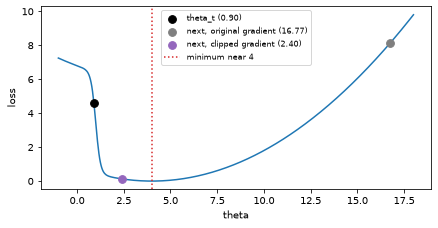

gradient -10.58: 원래 한 걸음 15.87, 잘라서 한 걸음 1.50
출발점: theta 0.90, loss 4.620
원래 gradient: theta 16.77, loss 8.149
잘린 gradient: theta 2.40, loss 0.128


In [69]:
def cliff_loss(theta: torch.Tensor) -> torch.Tensor:
    """왼쪽에 가파른 절벽이 있고 오른쪽은 완만한 loss입니다."""
    return 0.05 * (theta - 4) ** 2 + 6 * torch.sigmoid(-8 * (theta - 1))


grid = torch.linspace(-1, 18, 500)
theta_t = torch.tensor(0.9, requires_grad=True)
cliff_loss(theta_t).backward()
gradient = theta_t.grad.item()
lr, tau = 1.5, 1.0
step_plain = theta_t.item() - lr * gradient
step_clipped = theta_t.item() - lr * gradient * min(1.0, tau / abs(gradient))

plt.figure(figsize=(7, 3.3))
plt.plot(grid, cliff_loss(grid), color="tab:blue")
for x_value, color, label in [(theta_t.item(), "black", "theta_t"),
                              (step_plain, "tab:gray", "next, original gradient"),
                              (step_clipped, "tab:purple", "next, clipped gradient")]:
    plt.scatter(x_value, cliff_loss(torch.tensor(x_value)).item(), color=color, zorder=3, s=60, label=f"{label} ({x_value:.2f})")
plt.axvline(4, linestyle=":", color="tab:red", label="minimum near 4")
plt.xlabel("theta")
plt.ylabel("loss")
plt.legend(fontsize=8)
plt.show()
print(f"gradient {gradient:.2f}: 원래 한 걸음 {lr * abs(gradient):.2f}, 잘라서 한 걸음 {lr * min(abs(gradient), tau):.2f}")
for label, value in [("출발점", theta_t.item()), ("원래 gradient", step_plain), ("잘린 gradient", step_clipped)]:
    print(f"{label}: theta {value:.2f}, loss {cliff_loss(torch.tensor(value)).item():.3f}")

사용법은 한 줄입니다. **`backward()`와 `step()` 사이**에 `clip_grad_norm_`을 부릅니다. ([공식 문서](https://pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html)) 돌려주는 값은 자르기 전의 전체 norm이라, 기록해 두면 폭발 여부를 살필 수 있습니다.

In [70]:
class ClipNet(nn.Module):
    """간단한 신경망입니다."""

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10, 5)
        self.fc2 = nn.Linear(5, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.fc1(x))
        return self.fc2(x)


set_seed()
clip_net = ClipNet()
optimizer = optim.SGD(clip_net.parameters(), lr=0.01)
criterion = nn.MSELoss()

inputs = torch.randn(1, 10)
targets = torch.ones(1, 1) * 100   # 오차가 커서 gradient도 커지도록 큰 값을 줍니다

optimizer.zero_grad()
outputs = clip_net(inputs)
loss = criterion(outputs, targets)
loss.backward()
norm_before = nn.utils.clip_grad_norm_(clip_net.parameters(), 1.0)
norm_after = torch.sqrt(sum(p.grad.pow(2).sum() for p in clip_net.parameters()))
optimizer.step()
print(f"자르기 전 norm {norm_before.item():.2f} → 자른 뒤 norm {norm_after.item():.2f}")

자르기 전 norm 321.95 → 자른 뒤 norm 1.00


실제 학습에서 어떤 차이가 나는지 봅시다. 학습률이 큰 회귀 문제에 clipping 없는 경우와 있는 경우를 비교합니다.

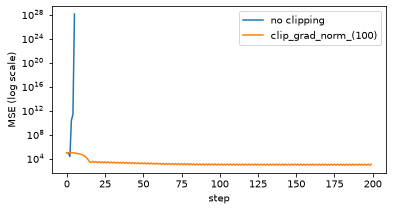

clipping 없음, 마지막 loss: nan
clipping 있음, 마지막 loss: 1168.7


In [71]:
def train_with_clip(max_norm: float | None, steps: int = 200) -> list[float]:
    """큰 학습률로 회귀를 학습하며 loss를 기록합니다. max_norm이 None이면 자르지 않습니다."""
    set_seed()
    x = torch.randn(256, 10)
    y = 100 * x.sum(dim=1, keepdim=True)
    regressor = nn.Sequential(nn.Linear(10, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    optimizer = optim.SGD(regressor.parameters(), lr=0.01)
    losses = []
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.mse_loss(regressor(x), y)
        losses.append(loss.item())
        loss.backward()
        if max_norm is not None:
            nn.utils.clip_grad_norm_(regressor.parameters(), max_norm)
        optimizer.step()
    return losses


no_clip = train_with_clip(None)
with_clip = train_with_clip(100.0)
plt.figure(figsize=(6, 3))
plt.semilogy(no_clip, label="no clipping")
plt.semilogy(with_clip, label="clip_grad_norm_(100)")
plt.xlabel("step")
plt.ylabel("MSE (log scale)")
plt.legend()
plt.show()
print("clipping 없음, 마지막 loss:", no_clip[-1])
print("clipping 있음, 마지막 loss:", round(with_clip[-1], 1))

clipping이 없으면 loss가 몇 스텝 만에 폭발해 `nan`이 됩니다. 한 번 `nan`이 되면 학습은 되돌릴 수 없습니다. 같은 설정에 clipping만 넣으면 안정적으로 내려가 1168.7에 도착합니다. 정답값의 분산이 약 100000이니 큰 폭으로 줄어든 것입니다. 임계값은 평소의 gradient norm을 기록해 보고 정하면 됩니다.

## 4부 실습

모델의 모든 **가중치** 파라미터 절댓값의 합을 돌려주는 `l1_penalty(model)`을 작성하세요. 이름에 `weight`가 들어간 파라미터만 더합니다(bias에는 보통 패널티를 걸지 않습니다). 그다음 `SimpleEarlyStopping(patience=2)`에 `[0.5, 0.4, 0.45, 0.46, 0.3]`을 차례로 넣어 보고, 몇 번째 값(0부터 셈)에서 멈추는지 `stop_at`에 담으세요.

In [72]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def l1_penalty(model: nn.Module) -> torch.Tensor:
    return sum(p.abs().sum() for name, p in model.named_parameters() if "weight" in name)


check_model = nn.Linear(2, 1)
nn.init.constant_(check_model.weight, -2.0)
nn.init.constant_(check_model.bias, 100.0)
assert l1_penalty(check_model).item() == 4.0   # bias는 빼고 |-2| + |-2|입니다

stop_at = stop_epoch(SimpleEarlyStopping(patience=2), [0.5, 0.4, 0.45, 0.46, 0.3])
print(stop_at)
assert stop_at == 3   # 0.45, 0.46에서 두 번 연속 개선이 없어 멈추므로 0.3은 보지 못합니다
```
</details>

---
# 5부. 앙상블과 실험 기록

## 5.1 Ensemble model이란

앙상블(Ensemble Learning)은 **여러 개의 개별 모델을 조합해 더 일반화된 모델을 만드는 방법**입니다. 약한 분류기(weak classifier)들을 결합해 강한 분류기(strong classifier)를 만듭니다. 결정 트리에서 생기는 과적합 문제를 줄여 준다는 장점이 있습니다. ([참고 그림](https://miro.medium.com/v2/resize:fit:720/format:webp/0*com0q0rUjm-UR-PX.png), [출처](https://medium.com/dawn-cau/%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D-%EC%95%99%EC%83%81%EB%B8%94-%ED%95%99%EC%8A%B5-%EC%9D%B4%EB%9E%80-cf1fcb97f9d0))

앙상블 기법에는 보팅(voting), 배깅(bagging), 부스팅(boosting), 스태킹(stacking)이 있습니다. 실습에 쓸 데이터를 미리 불러옵니다.

In [73]:
# 붓꽃 데이터셋을 로드합니다
iris = load_iris()
iris_df = pd.DataFrame(data=np.c_[iris.data, iris.target],
                       columns=["sepal length", "sepal width", "petal length", "petal width", "target"])

# train, test 데이터셋 분리
X = iris_df[iris_df.columns[:-1]]
y = iris_df["target"]
X_train, X_test, y_train, y_test_iris = train_test_split(X, y, test_size=0.3, random_state=68)
print(X_train.shape, X_test.shape)

(105, 4) (45, 4)


## 5.2 Bagging

Bagging은 "Bootstrap Aggregation"의 약자입니다. 데이터를 **복원 추출로 여러 번 뽑아** 각각 모델을 학습시킨 뒤 결과를 집계합니다. ([참고 그림](https://miro.medium.com/v2/resize:fit:640/format:webp/0*pH1BOQf72C8FVmoL.png))

```
전체 데이터 ─┬─ 복원 추출 1 ─▶ 모델 1 ─┐
             ├─ 복원 추출 2 ─▶ 모델 2 ─┼─▶ 투표 또는 평균 ─▶ 최종 예측
             └─ 복원 추출 3 ─▶ 모델 3 ─┘
```

- **범주형(Categorical) 데이터**는 투표로 집계합니다. 전체 모델의 예측 중 가장 많은 값을 최종 예측으로 삼습니다. 결정 트리 6개 중 4개가 A, 2개가 B라고 예측했다면 최종 결과는 A입니다.
- **연속형(Continuous) 데이터**는 각 모델의 예측값을 평균 내어 최종 예측값으로 삼습니다.

학습 데이터가 충분하지 않아도 여러 번 뽑아 쓰므로 효과를 낼 수 있습니다. 평균을 내면 모델마다의 들쭉날쭉함이 줄어들어 **variance가 큰 과적합 문제에 특히 도움이 됩니다.** bias가 높은 underfitting까지 고쳐 준다고 오해하기 쉬운데, 배깅은 주로 variance를 줄이는 방법입니다. 약한 모델을 모아도 평균의 bias는 거의 그대로이므로, bias를 줄이려면 다음에 볼 부스팅이 더 적합합니다.

In [74]:
# 어떤 모델을 여러 개 만들지 estimator 인자로 정합니다
estimator = SVC()   # 서포트 벡터 분류기
model = BaggingClassifier(estimator=estimator, n_estimators=5, random_state=45)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Bagging(SVC) 정확도:", accuracy_score(y_test_iris, y_pred) * 100)

single_svc = SVC().fit(X_train, y_train)
print("SVC 하나 정확도    :", accuracy_score(y_test_iris, single_svc.predict(X_test)) * 100)

Bagging(SVC) 정확도: 93.33333333333333
SVC 하나 정확도    : 93.33333333333333


둘 다 93.33%로 같습니다. 붓꽃은 쉬운 데이터이고 SVC는 안정적인 모델이라 배깅으로 얻을 것이 적습니다. 테스트가 45개뿐이어서 1개 차이가 2.2%포인트라는 점도 기억하세요.

배깅의 효과는 모델이 불안정할수록 잘 보입니다. variance가 큰 대표 모델인 결정 트리로, 더 어려운 손글씨 숫자 데이터에서 5겹 교차 검증을 해 봅시다.

In [75]:
X_digits, y_digits = load_digits(return_X_y=True)
for name, clf in [("결정 트리 1개", DecisionTreeClassifier(random_state=0)),
                  ("결정 트리 50개 배깅", BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=50, random_state=0))]:
    scores = cross_val_score(clf, X_digits, y_digits, cv=5)
    print(f"{name:12s} 평균 정확도 {scores.mean() * 100:.1f}% (fold 간 표준편차 {scores.std() * 100:.1f})")

결정 트리 1개     평균 정확도 78.6% (fold 간 표준편차 4.0)


결정 트리 50개 배깅 평균 정확도 91.2% (fold 간 표준편차 1.8)


## 5.3 Voting

Voting과 Bagging은 비슷해 보이지만 다릅니다. ([참고 그림](https://miro.medium.com/v2/resize:fit:720/format:webp/1*956o83hQsonj9cCjVeGMog.png))

- **Voting**: 서로 **다른 알고리즘**의 분류기를 결합합니다. 같은 데이터로 학습해 최종 예측을 투표합니다.
- **Bagging**: **같은 알고리즘**의 분류기들이 데이터 샘플링을 각자 다르게 가져가며 학습합니다.

투표 방식에는 두 가지가 있습니다. ([참고 그림](https://miro.medium.com/v2/resize:fit:720/format:webp/1*vxjYMhZz24FgE4SeIuc3hQ.png))

- **Hard voting**: 각 모델이 무엇으로 예측했는지 보고, 가장 많은 모델이 예측한 클래스를 고릅니다(다수결).
- **Soft voting**: 각 모델의 예측 확률을 클래스별로 평균 내어, 평균 확률이 가장 높은 클래스를 고릅니다.

Soft voting은 모델이 확률을 내야 합니다. `SVC()`는 기본적으로 확률을 계산하지 않아서 그대로 넣으면 에러가 납니다. `CalibratedClassifierCV`로 감싸 확률을 얻습니다(`SVC(probability=True)`는 scikit-learn 1.9부터 사용 중단 예고가 나와 있습니다).

또 모델이 두 개면 hard voting에서 두 모델의 답이 갈릴 때마다 동률이 되어, scikit-learn은 항상 번호가 작은 클래스를 고릅니다. 다수결이 실제로 일어나지 않습니다. 그래서 세 개를 넣습니다. 클래스가 2개일 때는 모델을 홀수 개로 두면 동률이 없습니다. 클래스가 3개 이상이면 홀수 개여도 동률이 날 수 있지만 훨씬 줄어듭니다.

In [76]:
estimator1 = CalibratedClassifierCV(SVC(), ensemble=False)
estimator2 = RandomForestClassifier(n_estimators=50, random_state=0)

estimator3 = LogisticRegression(max_iter=1000)   # 다수결이 동작하도록 세 번째 모델을 넣습니다

for voting in ["hard", "soft"]:
    # 각 모델을 불러낼 이름도 같이 지정합니다
    model = VotingClassifier(estimators=[("SVM", estimator1), ("RF", estimator2), ("LR", estimator3)], voting=voting)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{voting} voting 정확도:", accuracy_score(y_test_iris, y_pred) * 100)

hard voting 정확도: 97.77777777777777
soft voting 정확도: 97.77777777777777


## 5.4 Boosting

배깅의 모델들이 독립적으로 학습하는 반면, 부스팅은 **이전 모델의 학습이 다음 모델의 학습에 영향을 줍니다.** 이전 모델이 틀린 데이터에 높은 가중치를, 맞힌 데이터에 낮은 가중치를 주어 다음 모델을 학습합니다. 잘못 분류된 데이터에 집중해 새 분류 규칙을 만드는 일을 반복합니다. ([참고 그림](https://miro.medium.com/v2/resize:fit:720/format:webp/0*ijgfDicMQSRdydza.png))

```
데이터 ─▶ 모델 1 ─▶ 틀린 데이터 가중치↑ ─▶ 모델 2 ─▶ 틀린 데이터 가중치↑ ─▶ 모델 3 ─▶ 가중 합산
```

- **AdaBoostClassifier**: 위 설명 그대로 데이터 가중치를 바꿔 가며 학습합니다.
- **GradientBoostingClassifier**: 앞 모델이 남긴 오차(정확히는 loss의 gradient)를 다음 모델이 맞히도록 학습합니다.

예측 결과만 찍고 정확도를 보지 않으면 놓치는 문제를 하나 봅시다. `AdaBoostClassifier`에 SVC를 넣으면 무슨 일이 일어날까요? 정확도와 예측 분포를 함께 보며 원인을 찾습니다.

In [77]:
def report_boost(name: str, clf: BaseEstimator) -> None:
    """부스팅 모델을 학습하고 정확도와 예측 분포를 출력합니다."""
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    values, counts = np.unique(pred, return_counts=True)
    print(f"{name:35s} 정확도 {accuracy_score(y_test_iris, pred) * 100:5.1f}% | 예측한 클래스별 개수 {dict(zip(values.astype(int).tolist(), counts.tolist()))}")


# SVC를 약한 학습기로 넣어 봅니다
report_boost("AdaBoost(SVC) 5개", AdaBoostClassifier(estimator=SVC(), n_estimators=5, learning_rate=0.5, random_state=0))
# AdaBoost의 기본값은 깊이 1짜리 작은 결정 트리입니다
report_boost("AdaBoost(얕은 결정 트리) 50개", AdaBoostClassifier(n_estimators=50, random_state=0))

# 원인 확인: AdaBoost는 샘플 가중치의 합을 1로 맞춰 넘깁니다. SVC는 가중치를 벌점 세기 C에 곱하므로 C가 사실상 1/샘플 수가 됩니다
uniform_weight = np.full(len(X_train), 1 / len(X_train))
weak_svc = SVC().fit(X_train, y_train, sample_weight=uniform_weight)
print("가중치 합 1로 학습한 SVC 하나가 예측한 클래스:", np.unique(weak_svc.predict(X_test)).astype(int).tolist())
report_boost("AdaBoost(SVC, C를 샘플 수만큼 키움) 5개", AdaBoostClassifier(estimator=SVC(C=len(X_train)), n_estimators=5, learning_rate=0.5, random_state=0))

AdaBoost(SVC) 5개                    정확도  31.1% | 예측한 클래스별 개수 {2: 45}
AdaBoost(얕은 결정 트리) 50개              정확도  93.3% | 예측한 클래스별 개수 {0: 16, 1: 18, 2: 11}
가중치 합 1로 학습한 SVC 하나가 예측한 클래스: [2]
AdaBoost(SVC, C를 샘플 수만큼 키움) 5개      정확도  93.3% | 예측한 클래스별 개수 {0: 16, 1: 18, 2: 11}


In [78]:
report_boost("GradientBoosting 5개", GradientBoostingClassifier(n_estimators=5, learning_rate=0.5, max_depth=3, min_samples_leaf=1, random_state=0))
# 표 데이터가 크면 값을 구간으로 묶어 훨씬 빠른 히스토그램 방식을 씁니다
report_boost("HistGradientBoosting", HistGradientBoostingClassifier(random_state=0))

GradientBoosting 5개                 정확도  97.8% | 예측한 클래스별 개수 {0: 16, 1: 16, 2: 13}


HistGradientBoosting                정확도  97.8% | 예측한 클래스별 개수 {0: 16, 1: 16, 2: 13}


**원인을 찾았습니다.** AdaBoost는 샘플 가중치의 합을 1로 맞춰 넘기는데, SVC는 그 가중치를 벌점 세기 `C`에 곱합니다. 샘플 105개이니 `C`가 사실상 1/105로 줄어, 약한 정도를 넘어 **한 클래스만 답하는 모델**이 됩니다. 위 출력에서 SVC 하나가 클래스 2만 예측하고, 정확도가 31.1%인 것이 그 때문입니다. `C`를 샘플 수만큼 키우면 93.3%로 회복합니다. 정확도를 보지 않고 예측값만 찍었다면 지나치기 쉬운 문제입니다.

기본값인 얕은 결정 트리는 93.3%, GradientBoosting은 나무 5개로 97.8%입니다. 테스트가 45개뿐이라 1개 차이가 2.2%포인트이니, 이 숫자로 모델의 순위를 매기지는 마세요.

실무의 표 데이터에서는 부스팅이 강력한 기본 선택입니다. scikit-learn의 `HistGradientBoostingClassifier`나 LightGBM, XGBoost가 널리 쓰입니다.

## 5.5 Bagging과 Boosting 비교

| | 배깅 | 부스팅 |
|---|---|---|
| 학습 순서 | 병렬 학습 | 순차 학습 |
| 훈련 집합 | 균일한 확률로 복원 추출 | 앞 모델이 어려워한 데이터에 집중 |
| 장점 | 과대적합에 강함 | 오답에 집중해 정확도가 높음 |
| 약점 | 특정 영역에서 정확도가 낮을 수 있음 | 과대적합 가능성, 이상치와 결측치에 취약 |
| 시간 | 병렬이라 빠름 | 일반적으로 더 오래 걸림 |

"둘 다 복원 추출로 훈련 집합을 만든다"는 설명을 볼 수 있는데, 배깅은 맞지만 부스팅은 항상 그런 것은 아닙니다. scikit-learn의 AdaBoost는 데이터를 다시 뽑지 않고 샘플 가중치를 바꾸며, GradientBoosting은 기본 설정에서 전체 데이터를 그대로 씁니다. 공통점은 **여러 모델을 합쳐 하나의 예측을 만든다는 점**입니다.

## 5.6 Stacking

스태킹은 개별 모델이 예측한 값을 **다시 입력 데이터(meta dataset)로 삼아** 최종 모델(Meta Learner)을 학습하는 방식입니다. ([참고 그림 1](https://miro.medium.com/v2/resize:fit:720/format:webp/0*Qjil0P5JWZaCUgl_.png))

```
              ┌▶ Base Learner 1 ─▶ 예측 1 ─┐
학습 데이터 ──┼▶ Base Learner 2 ─▶ 예측 2 ─┼─▶ Meta Learner ─▶ 최종 예측
              └▶ Base Learner 3 ─▶ 예측 3 ─┘
```

그런데 Base Learner가 학습한 데이터를 그대로 예측해 Meta Learner에게 넘기면 과적합 문제가 생깁니다. 이미 답을 본 데이터의 예측은 지나치게 좋기 때문입니다. Meta Learner는 믿을 수 없이 좋은 입력에 속습니다.

그래서 데이터를 k번 나누어(k-fold cross validation) 활용합니다. training fold로 학습하고 **보지 않은 validation fold를 예측**하는 일을 k번 반복합니다. 그러면 모든 데이터에 "자기를 보지 않은 모델의 예측"이 하나씩 생기고, 이것을 Meta Learner에게 줍니다. ([참고 그림 2](https://miro.medium.com/v2/resize:fit:720/format:webp/0*TEyjCDwZQKk9ngb_.png) · [참고 그림 3](https://miro.medium.com/v2/resize:fit:640/format:webp/0*HjbKeS20I3UBJxzo.png))

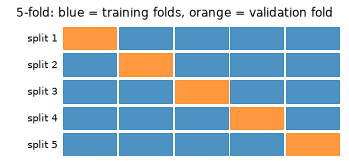

Stacking 정확도: 93.33333333333333


In [79]:
# k-fold 구조를 그립니다. 주황색 칸이 그 차례의 validation fold입니다
k = 5
fig, ax = plt.subplots(figsize=(6, 2.4))
for row in range(k):
    for col in range(k):
        ax.add_patch(plt.Rectangle((col, k - row - 1), 0.95, 0.85, color="tab:orange" if col == row else "tab:blue", alpha=0.8))
    ax.text(-0.1, k - row - 0.6, f"split {row + 1}", ha="right", va="center")
ax.set_xlim(-1, k)
ax.set_ylim(0, k)
ax.axis("off")
ax.set_title("5-fold: blue = training folds, orange = validation fold")
plt.show()

# scikit-learn의 StackingClassifier가 위 과정을 대신 해 줍니다
stacking = StackingClassifier(
    estimators=[("SVM", SVC(random_state=0)), ("RF", RandomForestClassifier(n_estimators=50, random_state=0))],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
)
stacking.fit(X_train, y_train)
print("Stacking 정확도:", accuracy_score(y_test_iris, stacking.predict(X_test)) * 100)

## 5.7 신경망 앙상블: 사전학습 모델 합치기

사전학습된 세 모델의 출력을 합쳐 CIFAR-10을 분류합니다. 출력을 더하지 않고 이어 붙인 뒤(concat) 완전연결층에 넣거나, 새 모델의 입력으로 넣어도 됩니다. 후자가 스태킹에 해당합니다.

> **이 코드에서 지킨 것들**
> - 마지막 층의 칸 수는 클래스 수(10)와 같아야 합니다.
> - 출력에 `softmax`를 걸어 `CrossEntropyLoss`에 넣으면 이중 적용입니다. `CrossEntropyLoss`는 안에 softmax가 포함되어 있습니다. 1, 2강에서 본 실수입니다. logit을 그대로 돌려줍니다.
> - 사전학습 모델 전체를 학습률 0.003으로 학습하면 애써 받아 온 가중치가 크게 흔들립니다. 세 모델은 고정하고 마지막 층만 학습합니다. 고정한 모델은 BatchNorm 통계가 바뀌지 않도록 항상 평가 모드로 둡니다.
> - Inception은 32×32 입력에서 에러가 납니다. 입력을 96×96으로 키우면 세 모델을 모두 쓸 수 있습니다.
> - 입력 정규화는 사전학습 모델이 학습한 ImageNet 값을 씁니다.
> - 사전학습 가중치는 `weights=` 인자로 고릅니다. torchvision은 가중치마다 라이선스가 따로 있을 수 있다고 안내하니, 상업적으로 쓸 때는 확인하세요.

처음 실행하면 가중치를 약 300MB 내려받습니다. 학습은 마지막 층만 하지만 입력마다 세 모델을 모두 통과하므로, GPU에서도 시간이 조금 걸립니다.

In [80]:
ENSEMBLE_TRAIN_SIZE = 50000
ENSEMBLE_TEST_SIZE = 10000
IMAGE_SIZE = 96

ensemble_transform = v2.Compose([
    v2.Resize(IMAGE_SIZE),
    to_tensor,
    v2.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),   # ImageNet 평균과 표준편차
])
ensemble_train = datasets.CIFAR10(root="./data", train=True, transform=ensemble_transform, download=True)
ensemble_test = datasets.CIFAR10(root="./data", train=False, transform=ensemble_transform, download=True)
ensemble_train_loader = DataLoader(Subset(ensemble_train, range(ENSEMBLE_TRAIN_SIZE)), batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
ensemble_test_loader = DataLoader(Subset(ensemble_test, range(ENSEMBLE_TEST_SIZE)), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)


class MyEnsemble(nn.Module):
    """사전학습 모델 세 개의 출력을 더한 뒤 마지막 층으로 분류합니다."""

    def __init__(self, modelA: nn.Module, modelB: nn.Module, modelC: nn.Module, input_size: int, num_classes: int = 10):
        super().__init__()
        self.modelA = modelA
        self.modelB = modelB
        self.modelC = modelC
        for backbone in (modelA, modelB, modelC):
            backbone.requires_grad_(False)
        self.fc1 = nn.Linear(input_size, num_classes)

    def train(self, mode: bool = True) -> "MyEnsemble":
        # model.train()을 불러도 사전학습 모델은 평가 모드로 남겨 BatchNorm 통계를 지킵니다
        super().train(mode)
        for backbone in (self.modelA, self.modelB, self.modelC):
            backbone.eval()
        return self

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            # 여기서는 단순히 더했습니다. concat 뒤 완전연결층에 넣거나 새 모델의 입력으로 넣어도 됩니다
            out = self.modelA(x) + self.modelB(x) + self.modelC(x)
        return self.fc1(out)


def train_ensemble(model: nn.Module, train_loader: DataLoader, test_loader: DataLoader, epochs: int,
                   optimizer: optim.Optimizer, criterion: nn.Module) -> tuple[nn.Module, list[float], list[float]]:
    """매 epoch의 train loss와 test loss를 기록합니다."""
    train_losses, test_losses = [], []
    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            running += loss.item()
        train_losses.append(running / len(train_loader))
        test_losses.append(get_test_loss(model, criterion, test_loader))
        print(f"Epoch: {epoch}/{epochs} train_loss: {train_losses[-1]:.3f} test_loss: {test_losses[-1]:.3f} test_acc: {evaluate(model, test_loader):.2f}%")
    return model, train_losses, test_losses


set_seed()
incept = models.inception_v3(weights=models.Inception_V3_Weights.DEFAULT)
resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
densenet = models.densenet161(weights=models.DenseNet161_Weights.DEFAULT)

ensemble_model = MyEnsemble(densenet, resnet, incept, 1000).to(device)
optimizer = optim.Adam(ensemble_model.fc1.parameters(), lr=0.003)
criterion = nn.CrossEntropyLoss()
ensemble_model, ensemble_train_loss, ensemble_test_loss = train_ensemble(
    ensemble_model, ensemble_train_loader, ensemble_test_loader, ENSEMBLE_EPOCHS, optimizer, criterion)

Epoch: 1/5 train_loss: 1.394 test_loss: 1.630 test_acc: 83.09%


Epoch: 2/5 train_loss: 1.340 test_loss: 1.385 test_acc: 86.88%


Epoch: 3/5 train_loss: 1.331 test_loss: 1.433 test_acc: 87.28%


Epoch: 4/5 train_loss: 1.333 test_loss: 1.569 test_acc: 87.02%


Epoch: 5/5 train_loss: 1.254 test_loss: 1.456 test_acc: 87.96%


위 출력에서 사전학습 모델 셋과 학습한 마지막 층 하나만으로 5 epoch 뒤 테스트 정확도가 87.96%입니다. 이 강의의 다른 CIFAR-10 모델보다 높습니다. 다만 test loss는 1.4 근처에서 내려가지 않습니다. 세 모델의 출력을 더하면 값의 크기가 커지므로 학습률 0.003이 큰 탓일 수 있습니다. 확인하지 않은 가설이니 숙제에서 학습률을 낮춰 보세요.

## 5.8 같은 모델을 여러 번 학습한 앙상블

신경망은 시드만 달라도 다른 지점으로 수렴합니다. 그래서 **같은 구조를 시드만 바꿔 여러 번 학습한 뒤 출력을 평균**하는 것(딥 앙상블)도 소프트 보팅의 한 형태입니다. 5분 안쪽의 작은 실험으로 앙상블의 효과를 직접 확인합니다.

In [81]:
def collect_probs(net: nn.Module, loader: DataLoader) -> tuple[torch.Tensor, torch.Tensor]:
    """테스트 데이터 전체의 클래스 확률과 정답을 모읍니다."""
    net.eval()
    probs, targets = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            probs.append(F.softmax(net(inputs.to(device)), dim=1).cpu())
            targets.append(labels)
    return torch.cat(probs), torch.cat(targets)


member_probs = []
for seed in range(3):
    set_seed(seed)
    member = LeNetLike().to(device)
    member_optimizer = optim.Adam(member.parameters(), lr=0.001)
    for epoch in range(5):
        member.train()
        for inputs, labels in lenet_train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            member_optimizer.zero_grad()
            F.cross_entropy(member(inputs), labels).backward()
            member_optimizer.step()
    probs, targets = collect_probs(member, lenet_test_loader)
    member_probs.append(probs)
    print(f"모델 {seed}: {(probs.argmax(dim=1) == targets).float().mean().item() * 100:.2f}%")

ensemble_probs = torch.stack(member_probs).mean(dim=0)
print(f"3개 평균(soft voting): {(ensemble_probs.argmax(dim=1) == targets).float().mean().item() * 100:.2f}%")

모델 0: 59.17%


모델 1: 60.63%


모델 2: 60.78%
3개 평균(soft voting): 64.66%


모델 세 개는 59.17%, 60.63%, 60.78%이고 평균을 내면 **64.66%**입니다. 가장 좋은 모델보다 3.9%포인트 높습니다. 추가 데이터 없이 시드만 바꾼 결과입니다. 대신 학습 시간과 추론 시간은 세 배가 듭니다.

## 5부 실습 1: 소프트 보팅 직접 구현

아래 셀이 세 모델의 클래스 확률을 만들어 둡니다. 샘플 4개, 클래스 3개입니다. 이 값으로 `hard_pred`(먼저 각 모델이 고른 클래스를 구한 뒤 다수결, 동률이면 번호가 작은 클래스)와 `soft_pred`(확률 평균의 최댓값)를 구하세요. 모델이 세 개이므로 동률은 3개 모두 다른 경우에만 생깁니다. 두 방식의 답이 갈리는 샘플이 하나 있으니 왜 그런지도 생각해 보세요.

In [82]:
probs_a = np.array([[0.9, 0.05, 0.05], [0.4, 0.35, 0.25], [0.2, 0.5, 0.3], [0.1, 0.2, 0.7]])
probs_b = np.array([[0.8, 0.1, 0.1], [0.4, 0.5, 0.1], [0.3, 0.45, 0.25], [0.05, 0.25, 0.7]])
probs_c = np.array([[0.7, 0.2, 0.1], [0.05, 0.9, 0.05], [0.9, 0.05, 0.05], [0.3, 0.3, 0.4]])
all_probs = np.stack([probs_a, probs_b, probs_c])   # (모델 수, 샘플 수, 클래스 수)
print(all_probs.shape)

(3, 4, 3)


In [83]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
choices = all_probs.argmax(axis=2)       # 모델별로 고른 클래스 (모델 수, 샘플 수)
hard_pred = np.array([np.bincount(choices[:, i], minlength=3).argmax() for i in range(choices.shape[1])])
soft_pred = all_probs.mean(axis=0).argmax(axis=1)
print(hard_pred, soft_pred)
assert hard_pred.tolist() == [0, 1, 1, 2]
assert soft_pred.tolist() == [0, 1, 0, 2]   # 세 번째 샘플: 두 모델이 약하게 1, 한 모델이 강하게 0
assert np.allclose(all_probs.mean(axis=0).sum(axis=1), 1.0)   # 평균 확률의 합도 1입니다
```
</details>

## 5.9 실험 기록: TensorBoard

여기까지 실험을 많이 돌렸습니다. "어제 돌린 것이 어떤 설정이었지?"가 금방 찾아옵니다. 그래서 실험은 기록해야 합니다. 앞에서 `SummaryWriter`로 남긴 파일을 이제 열어 봅니다.

아래 셀을 실행하면 Colab 안에 TensorBoard 화면이 뜹니다. `SCALARS` 탭에서 각 실험의 곡선을, `CUSTOM SCALARS` 탭에서 train과 test를 겹친 그래프를 볼 수 있습니다. 왼쪽 실행 목록에서 `overfitting`, `augment`, `trivial`, `mix`, `dropout`, `adamw`를 켜고 끄며 비교하세요.

만약 6006 포트가 사용 중이라는 메시지가 나오면 다음 명령으로 pid를 확인한 뒤 종료합니다.

```
!lsof -i:6006
!kill <pid>
```

In [84]:
%reload_ext tensorboard
%tensorboard --logdir=runs

TensorBoard 확장 불러오기 건너뜀
TensorBoard 화면은 Colab에서 직접 확인하세요


화면 없이 기록 파일을 코드로 읽을 수도 있습니다. 결과를 자동으로 비교하거나 표로 만들 때 쓰는 방법입니다.

overfitting  기록 30개, 마지막 test loss 2.412
augment      기록 30개, 마지막 test loss 0.595
dropout      기록 30개, 마지막 test loss 0.796


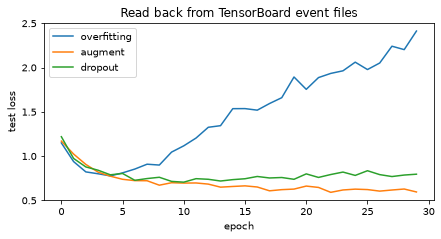

In [85]:
def read_scalar(run_name: str, tag: str) -> list[float]:
    """TensorBoard 기록 파일에서 값을 읽어 옵니다."""
    accumulator = EventAccumulator(f"runs/{run_name}")
    accumulator.Reload()
    return [event.value for event in accumulator.Scalars(tag)]


plt.figure(figsize=(7, 3.2))
for run_name in ["overfitting", "augment", "dropout"]:
    values = read_scalar(run_name, "loss/test")
    plt.plot(values, label=run_name)
    print(f"{run_name:12s} 기록 {len(values)}개, 마지막 test loss {values[-1]:.3f}")
plt.xlabel("epoch")
plt.ylabel("test loss")
plt.legend()
plt.title("Read back from TensorBoard event files")
plt.show()

## 5.10 실험 기록: wandb (선택 실습)

TensorBoard는 파일이 실행 중인 환경에 남는 반면(Colab이면 런타임의 임시 디스크라서 런타임이 끝나면 사라집니다), [wandb](https://docs.wandb.ai/)(Weights & Biases)는 결과를 웹 서버에 올려 어디서나 보고 동료와 공유할 수 있습니다. 사용법은 텐서보드와 크게 다르지 않습니다. 다음처럼 기록합니다.

```python
wandb.log({"Train Loss": train_loss, "Train Accuracy": acc, "Epoch": epoch})
```

`wandb.init(project=...)`으로 시작하고 `wandb.finish()`로 끝냅니다. `wandb.watch(net, log="all")`을 부르면 가중치와 gradient의 분포도 함께 기록합니다. 서버에 올리면 프로젝트 화면에서 `Train Loss`, `Test Accuracy` 같은 항목별 그래프와 실험 목록을 웹에서 볼 수 있습니다.

> **이 실습은 계정이 없어도 돌아갑니다.** `wandb.login()`은 키를 입력할 때까지 기다리느라 Run All을 멈춰 세웁니다. 그래서 키가 있을 때만 로그인하고, 없으면 `offline` 모드로 파일에만 저장합니다.
>
> 웹에서 보려면 [wandb.ai](https://wandb.ai/)에서 무료 계정을 만들고 API 키를 받아, Colab 왼쪽의 열쇠 아이콘(보안 비밀)에 `WANDB_API_KEY`라는 이름으로 저장한 뒤 이 셀을 다시 실행하세요. **키를 코드에 직접 적지 마세요.** 오프라인으로 남긴 기록도 같은 임시 디스크에 있으니, 런타임이 끝나기 전에 `wandb sync wandb/offline-run-*`로 올리거나 내려받으세요.

In [86]:
os.environ["WANDB_SILENT"] = "true"   # 진행 메시지로 출력이 길어지지 않게 합니다


def get_wandb_key() -> str | None:
    """Colab 보안 비밀이나 환경 변수에서 키를 찾습니다. 없으면 None입니다."""
    try:
        from google.colab import userdata
        return userdata.get("WANDB_API_KEY")
    except Exception as error:   # Colab이 아니거나, 비밀을 등록하지 않았거나, 접근을 허용하지 않은 경우입니다
        print("Colab 보안 비밀을 읽지 못했습니다:", type(error).__name__)
        return os.environ.get("WANDB_API_KEY")


wandb_key = get_wandb_key()
if wandb_key:
    wandb.login(key=wandb_key)
wandb_mode = "online" if wandb_key else "offline"
print("wandb 모드:", wandb_mode)

Colab 보안 비밀을 읽지 못했습니다: ModuleNotFoundError
wandb 모드: offline


**실습: wandb로 직접 코드를 짜고 돌려 보기.** 앞에서 만든 `train`과 `test`가 돌려주는 값을 `wandb.log`로 기록하면 됩니다.

> 이미 학습이 끝난 모델을 이어서 학습하면 처음부터 정확도가 높게 나와 곡선을 읽기 어렵습니다. 여기서는 새 모델을 만듭니다.

In [87]:
def run_wandb_epoch(model: nn.Module, train_loader: DataLoader, test_loader: DataLoader, optimizer: optim.Optimizer,
                    criterion: nn.Module, epoch: int) -> None:
    """앞에서 만든 train과 test로 한 epoch을 돌고 결과를 wandb에 기록합니다."""
    train_loss, train_acc = train(model, device, train_loader, optimizer, criterion, epoch)
    test_loss, test_acc = test(model, device, test_loader, criterion, epoch)
    wandb.log({"Epoch": epoch, "Train Loss": train_loss, "Train Accuracy": train_acc,
               "Test Loss": test_loss, "Test Accuracy": test_acc})
    if epoch % 5 == 0:
        print(f"Epoch [{epoch}] Loss: {train_loss:.4f}, Accuracy: {train_acc} | Test_loss: {test_loss:.4f}, Test_accuracy: {test_acc}")

In [88]:
set_seed()
wandb_net = OverfitNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(wandb_net.parameters())

wandb.init(project="OVERFITTING", mode=wandb_mode, config={"model": "OverfitNet", "epochs": WANDB_EPOCHS, "batch_size": batch_size})
wandb.watch(wandb_net, log="all")

for epoch in range(WANDB_EPOCHS):
    run_wandb_epoch(wandb_net, trainloader, testloader, optimizer, criterion, epoch)

print("Finished Training")
print("기록 위치:", Path(wandb.run.dir).relative_to(Path.cwd()))
wandb.finish()

Epoch [0] Loss: 1.4089, Accuracy: 48.35 | Test_loss: 1.1490, Test_accuracy: 59.62


Epoch [5] Loss: 0.4949, Accuracy: 82.53 | Test_loss: 0.8107, Test_accuracy: 73.76


Epoch [10] Loss: 0.2140, Accuracy: 92.36 | Test_loss: 1.1163, Test_accuracy: 73.2


Epoch [15] Loss: 0.1366, Accuracy: 95.34 | Test_loss: 1.5364, Test_accuracy: 72.17


Epoch [20] Loss: 0.1179, Accuracy: 96.0 | Test_loss: 1.7540, Test_accuracy: 73.32


Epoch [25] Loss: 0.1032, Accuracy: 96.71 | Test_loss: 1.9774, Test_accuracy: 72.94


Finished Training
기록 위치: wandb/offline-run-20261105_195016-t4ised2i/files


## 5부 실습 2: 나만의 기록 남기기

`SummaryWriter`로 `runs/practice`에 `demo/value`라는 이름의 값을 기록하세요. step 0~4에서 값은 `step ** 2`입니다. writer를 닫은 뒤 앞에서 만든 `read_scalar`로 읽어 `[0, 1, 4, 9, 16]`이 나오는지 확인합니다.

In [89]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
shutil.rmtree("runs/practice", ignore_errors=True)   # 다시 실행해도 기록이 겹치지 않게 합니다
practice_writer = SummaryWriter(log_dir="runs/practice")
for step in range(5):
    practice_writer.add_scalar("demo/value", step ** 2, step)
practice_writer.close()
values = read_scalar("practice", "demo/value")
print(values)
assert values == [0, 1, 4, 9, 16]
```
</details>

---
# 이 강의 요약

- **과적합**은 학습 곡선으로 진단합니다. 학습 오차가 크면 언더피팅, 학습 오차는 작은데 테스트 오차가 크면 오버피팅입니다. 정확도만 보지 말고 loss도 보세요.
- **증강**은 `torchvision.transforms.v2`로 구성합니다. 먼저 자동 증강으로는 `TrivialAugmentWide`가, 긴 학습에는 MixUp과 CutMix가 있습니다. 정보를 보존하면서 다양성을 늘리는 변환을 고릅니다. 숫자의 상하 반전처럼 뜻을 바꾸는 변환은 해롭습니다. torchvision의 `AutoAugment`는 탐색이 아니라 이미 찾아 둔 정책의 적용입니다. TTA에도 같은 규칙이 적용됩니다. Albumentations의 `ToTensorV2`는 255로 나누지 않습니다.
- **BatchNorm**은 학습 때 배치 통계를, 평가 때 저장된 통계를 씁니다. **Dropout**은 평가 때 꺼집니다. 둘 다 `model.train()`과 `model.eval()` 전환이 중요합니다.
- **L1**은 파라미터를 정확히 0으로 만들 수 있고, **L2**는 고르게 줄이며, **Elastic Net**은 둘을 섞습니다. 신경망에서는 `weight_decay`가 L2이고, Adam 계열의 기본 선택은 `AdamW`입니다. 패널티를 걸기 전에 변수의 크기를 맞추세요.
- **Early stopping**은 validation loss가 더 이상 줄지 않으면 멈추고, 가장 좋았던 모델로 되돌립니다. test set으로 멈출 시점을 정하면 안 됩니다.
- **Gradient 소실**은 ReLU 계열, 알맞은 초기화, BatchNorm을 함께 써서 다루고, **폭발**은 `clip_grad_norm_`으로 다룹니다.
- **앙상블**: 배깅은 variance를, 부스팅은 bias를 주로 줄입니다. 보팅은 다른 알고리즘을 합치고, 스태킹은 예측을 다시 입력으로 씁니다.
- **기록**: TensorBoard는 실행 환경의 파일로(Colab에서는 런타임이 끝나면 사라집니다), wandb는 웹에 남깁니다. 키는 코드에 적지 않습니다.

# 숙제

1. **MNIST 증강 경진대회**: 2.2의 주석을 풀거나 공식 문서에서 다른 증강을 골라, `MLP`의 테스트 정확도를 `no augmentation`보다 높여 보세요. 맨 앞 셀의 `MNIST_EPOCHS`를 30으로 늘리면 결과가 어떻게 달라지나요? `run_torch_aug`의 `seed` 인자로 시드를 3개 돌려 평균을 내고, 차이가 시드에 의한 흔들림보다 큰지 확인하세요.
2. **AutoAugment 정책 비교**: 1.4의 CIFAR-10 실험에 `AutoAugment(CIFAR10)`을 넣어 보고, `IMAGENET`, `SVHN` 정책과 비교하세요.
3. **BatchNorm과 Dropout 바꿔 보기**: 3.7의 "아래쪽을 바꿔 보세요" 부분에서 Dropout을 BatchNorm 뒤로 옮기고, 비율을 바꾸고, 옵티마이저를 SGD로 바꿔 결과를 표로 정리하세요.
4. **`model.eval()` 빠뜨려 보기**: `get_test_loss`에서 `net.eval()`을 지우고 `LeNetDropout`의 test loss가 어떻게 달라지는지 재 보세요. 흔한 버그입니다.
5. **세 가지를 함께**: `OverfitNet`에 증강, Dropout, `AdamW`의 `weight_decay`, Early stopping을 모두 넣어(`fit`에는 Early stopping이 없으니 4.9의 반복문처럼 직접 작성합니다) test loss를 얼마나 낮출 수 있는지 시험하고, TensorBoard에서 비교하세요.
6. **wandb로 올리기**: 무료 계정을 만들어 `WANDB_API_KEY`를 등록하고, 5.10을 다시 돌려 웹 화면에서 곡선을 확인하세요. `wandb.init`의 `config`에 학습률과 배치 크기를 넣고 여러 번 돌려 실험 목록에서 비교해 보세요.
7. **concat 앙상블**: 5.7의 `MyEnsemble`을 `torch.cat`으로 바꿔 보세요. 입력 크기는 어떻게 달라져야 하나요? 합(sum) 방식과 비교하고, 학습률을 낮췄을 때 test loss가 어떻게 바뀌는지도 보세요.
8. **초기화와 gradient 소실**: 4.10의 `layer_grad_norms`에서 `nn.Linear`의 가중치를 `nn.init.kaiming_normal_`로 초기화하고, ReLU의 입력 쪽과 출력 쪽 gradient 비율을 다시 재 보세요.

# 더 읽을거리

- [Ioffe & Szegedy, Batch Normalization (2015)](https://arxiv.org/abs/1502.03167) · [Santurkar et al., How Does Batch Normalization Help Optimization? (2018)](https://arxiv.org/abs/1805.11604)
- [Cubuk et al., AutoAugment (2018)](https://arxiv.org/abs/1805.09501)
- [Li et al., Dropout과 BatchNorm의 불화 (2018)](https://arxiv.org/abs/1801.05134)
- [Loshchilov & Hutter, Decoupled Weight Decay (AdamW) (2017)](https://arxiv.org/abs/1711.05101)
- [Ruder, An Overview of Multi-Task Learning (2017)](https://arxiv.org/abs/1706.05098)
- [PyTorch TensorBoard 문서](https://pytorch.org/docs/stable/tensorboard.html) · [wandb 문서](https://docs.wandb.ai/)
- [ttach](https://github.com/qubvel/ttach) · [early-stopping-pytorch](https://github.com/Bjarten/early-stopping-pytorch)